# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import ok_k_mer

In [2]:
import os
# from random import randint
import multiprocessing as mp
from random import sample
from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40



In [3]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [4]:
import warnings
warnings.filterwarnings("ignore")


In [5]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Process data

In [6]:
aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = ok_k_mer.process_data(chlamydia_tree_path, chlamydia_dir_path)
aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = ok_k_mer.process_data(aquificota_tree_path, aquificota_dir_path)
bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = ok_k_mer.process_data(bacillales_tree_path, bacillales_dir_path)
caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = ok_k_mer.process_data(caldisericia_tree_path, caldisericia_dir_path)
cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = ok_k_mer.process_data(cyano_tree_path, cyano_dir_path)
neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = ok_k_mer.process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)


Loaded 60 files
distance_k42.txt: (288, 288)
distance_k10.txt: (288, 288)
distance_k54.txt: (288, 288)
distance_k58.txt: (288, 288)
distance_k39.txt: (288, 288)
distance_k57.txt: (288, 288)
distance_k26.txt: (288, 288)
distance_k34.txt: (288, 288)
distance_k11.txt: (288, 288)
distance_k22.txt: (288, 288)
distance_k7.txt: (288, 288)
distance_k45.txt: (288, 288)
distance_k61.txt: (288, 288)
distance_k14.txt: (288, 288)
distance_k52.txt: (288, 288)
distance_k59.txt: (288, 288)
distance_k18.txt: (288, 288)
distance_k38.txt: (288, 288)
distance_k31.txt: (288, 288)
distance_k41.txt: (288, 288)
distance_k55.txt: (288, 288)
distance_k60.txt: (288, 288)
distance_k64.txt: (288, 288)
distance_k33.txt: (288, 288)
distance_k12.txt: (288, 288)
distance_k30.txt: (288, 288)
distance_k15.txt: (288, 288)
distance_k56.txt: (288, 288)
distance_k44.txt: (288, 288)
distance_k37.txt: (288, 288)
distance_k36.txt: (288, 288)
distance_k63.txt: (288, 288)
distance_k51.txt: (288, 288)
distance_k21.txt: (288, 288

In [7]:
# Prepare a list of all available merged_dfs and their names
datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]


## Grid search and heatmaps on (one to three) k-mers

### One k-mer

Aquificota


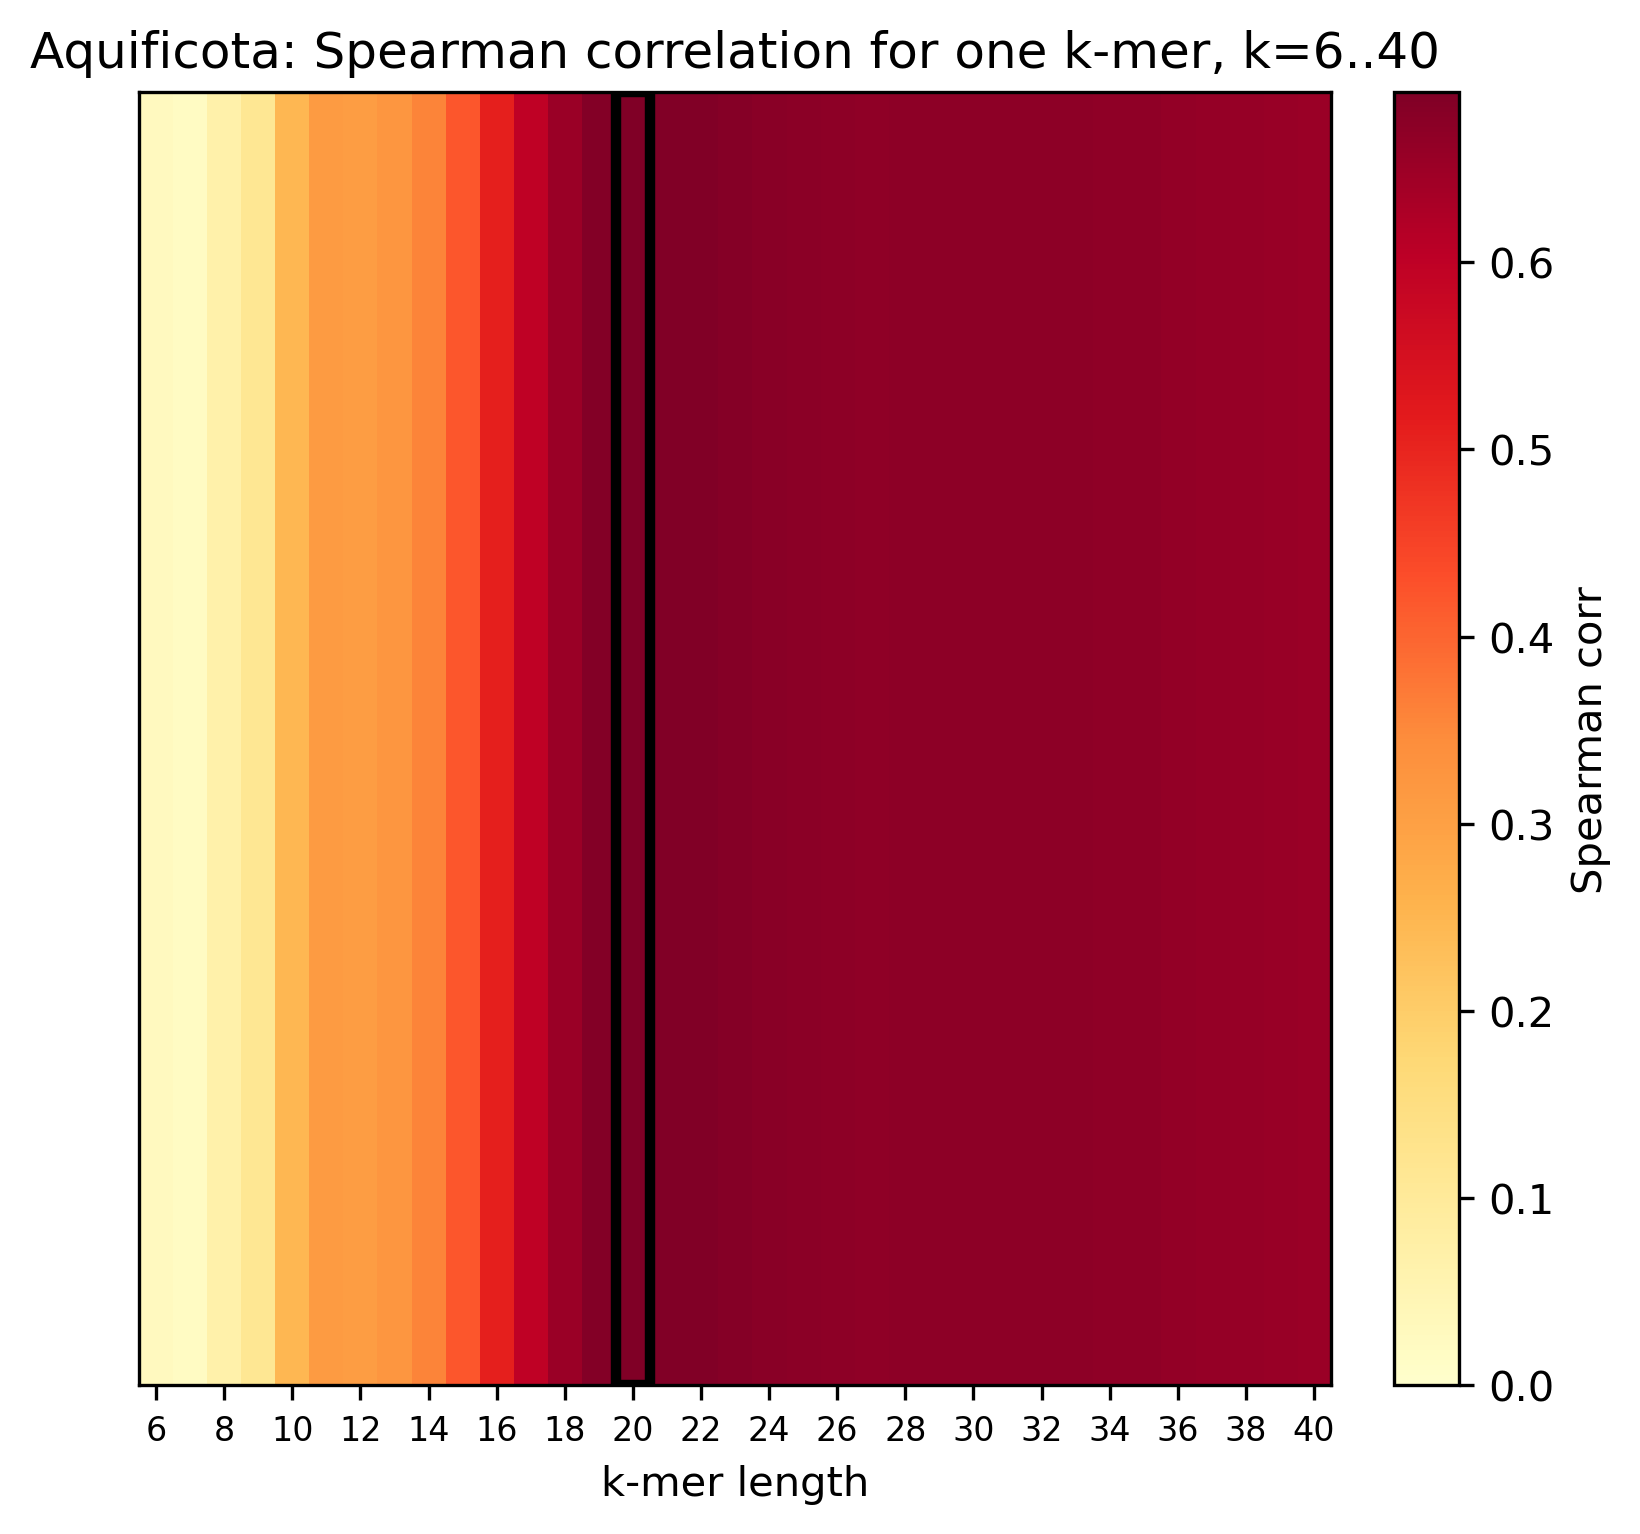


Bacillales


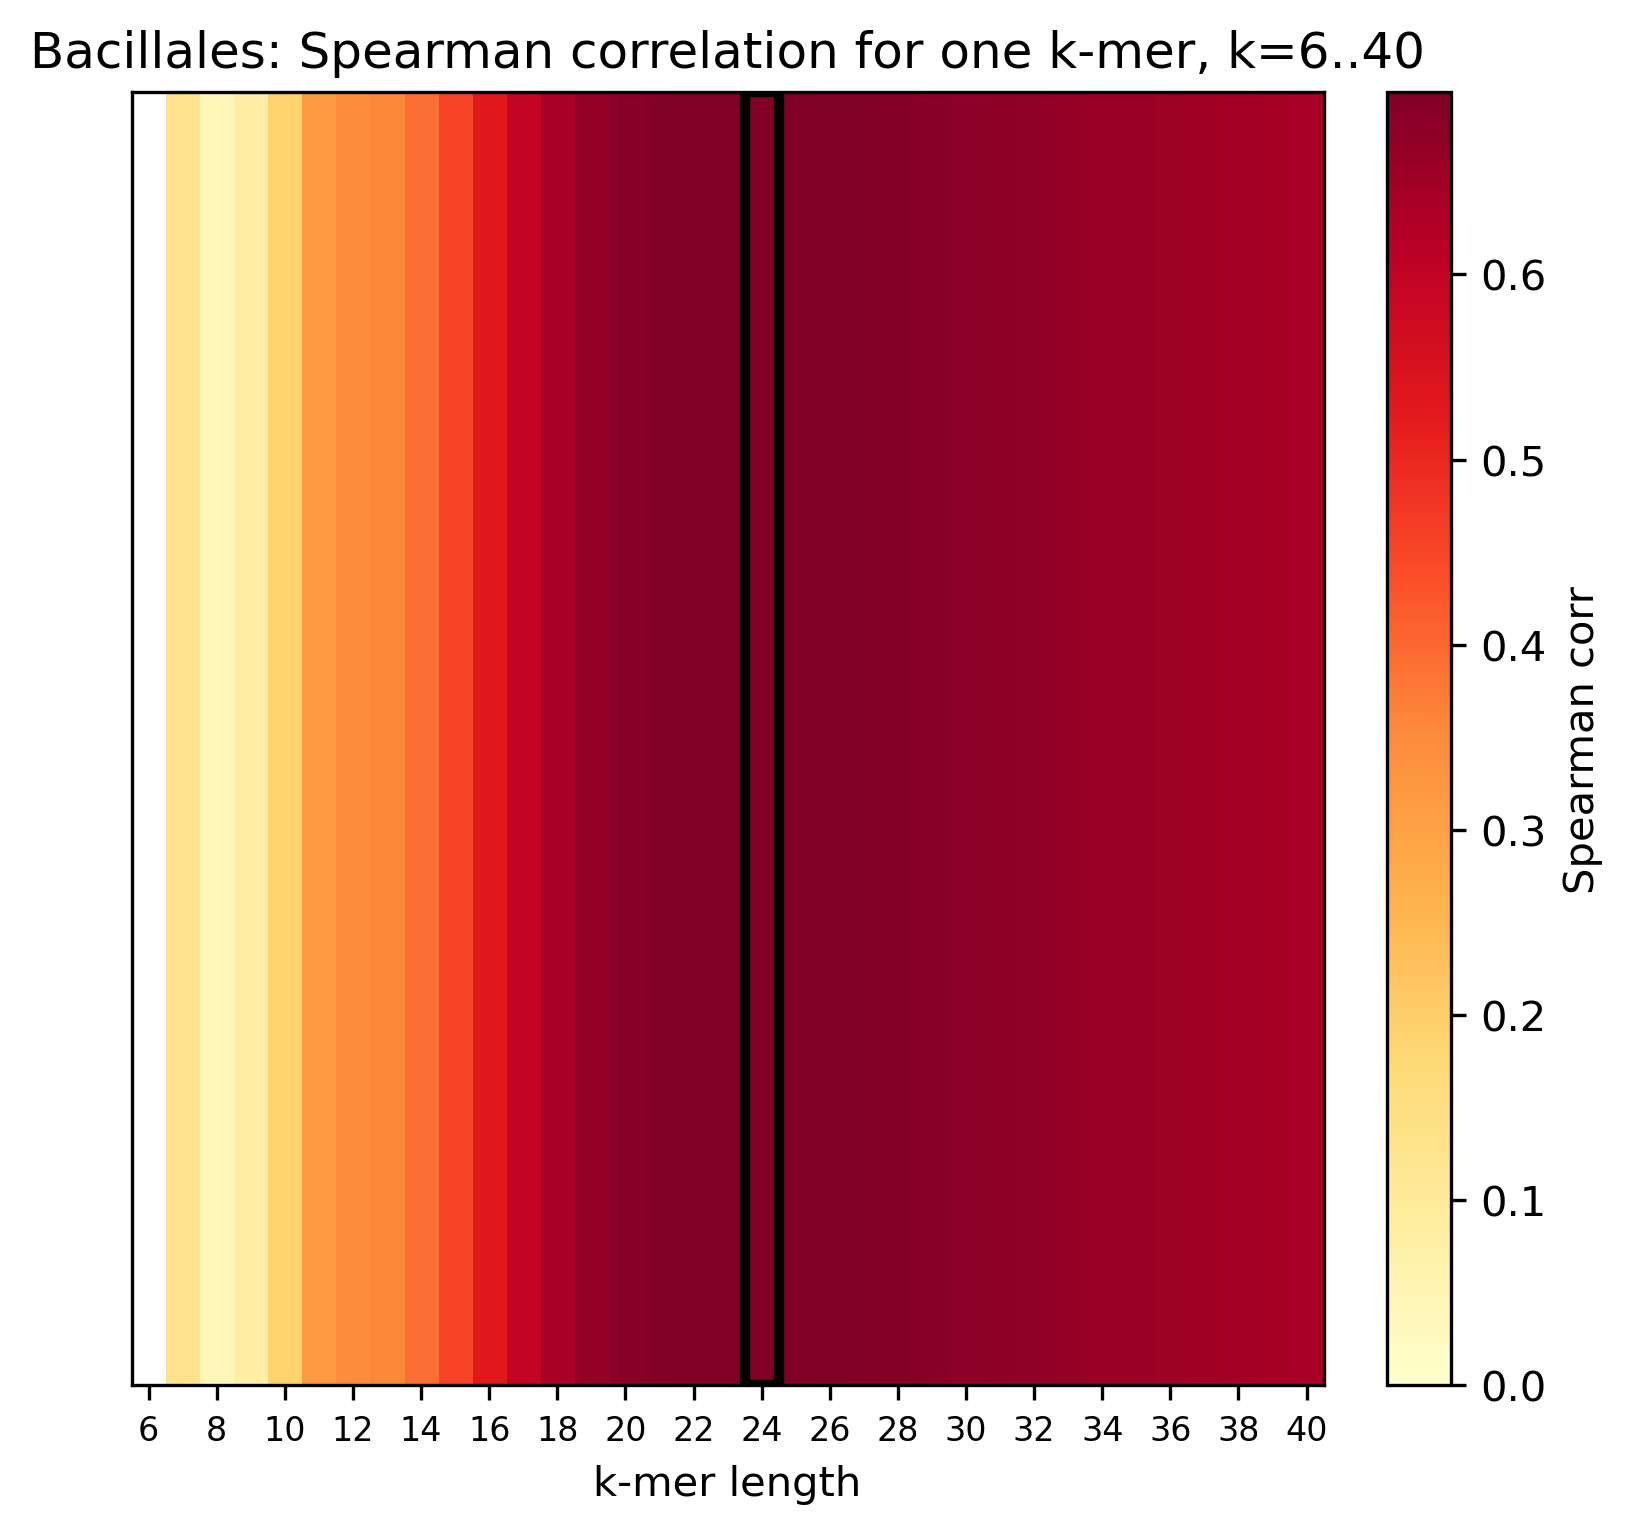


Caldisericia


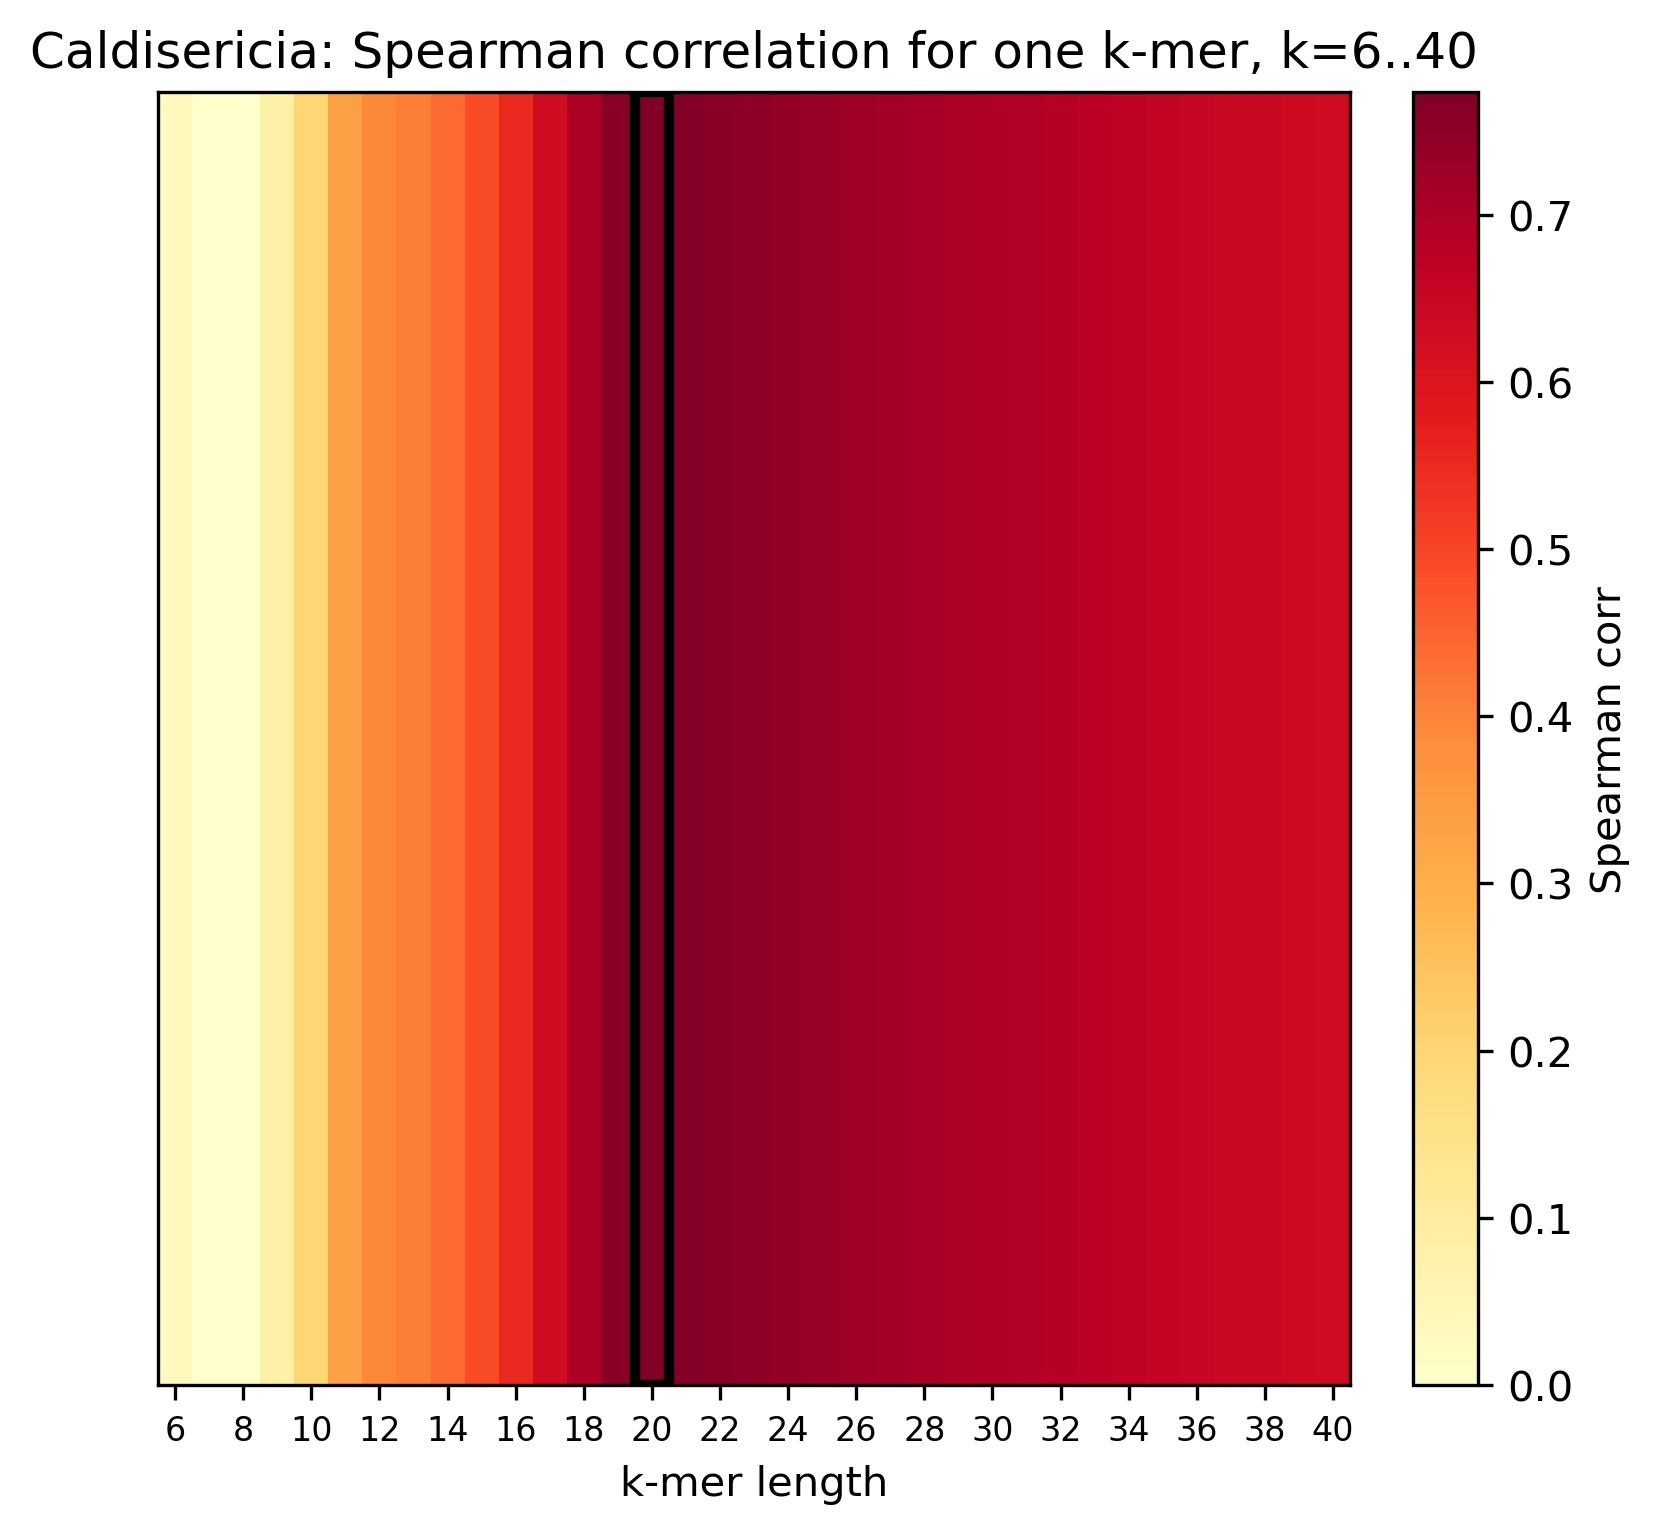


Chlamydia


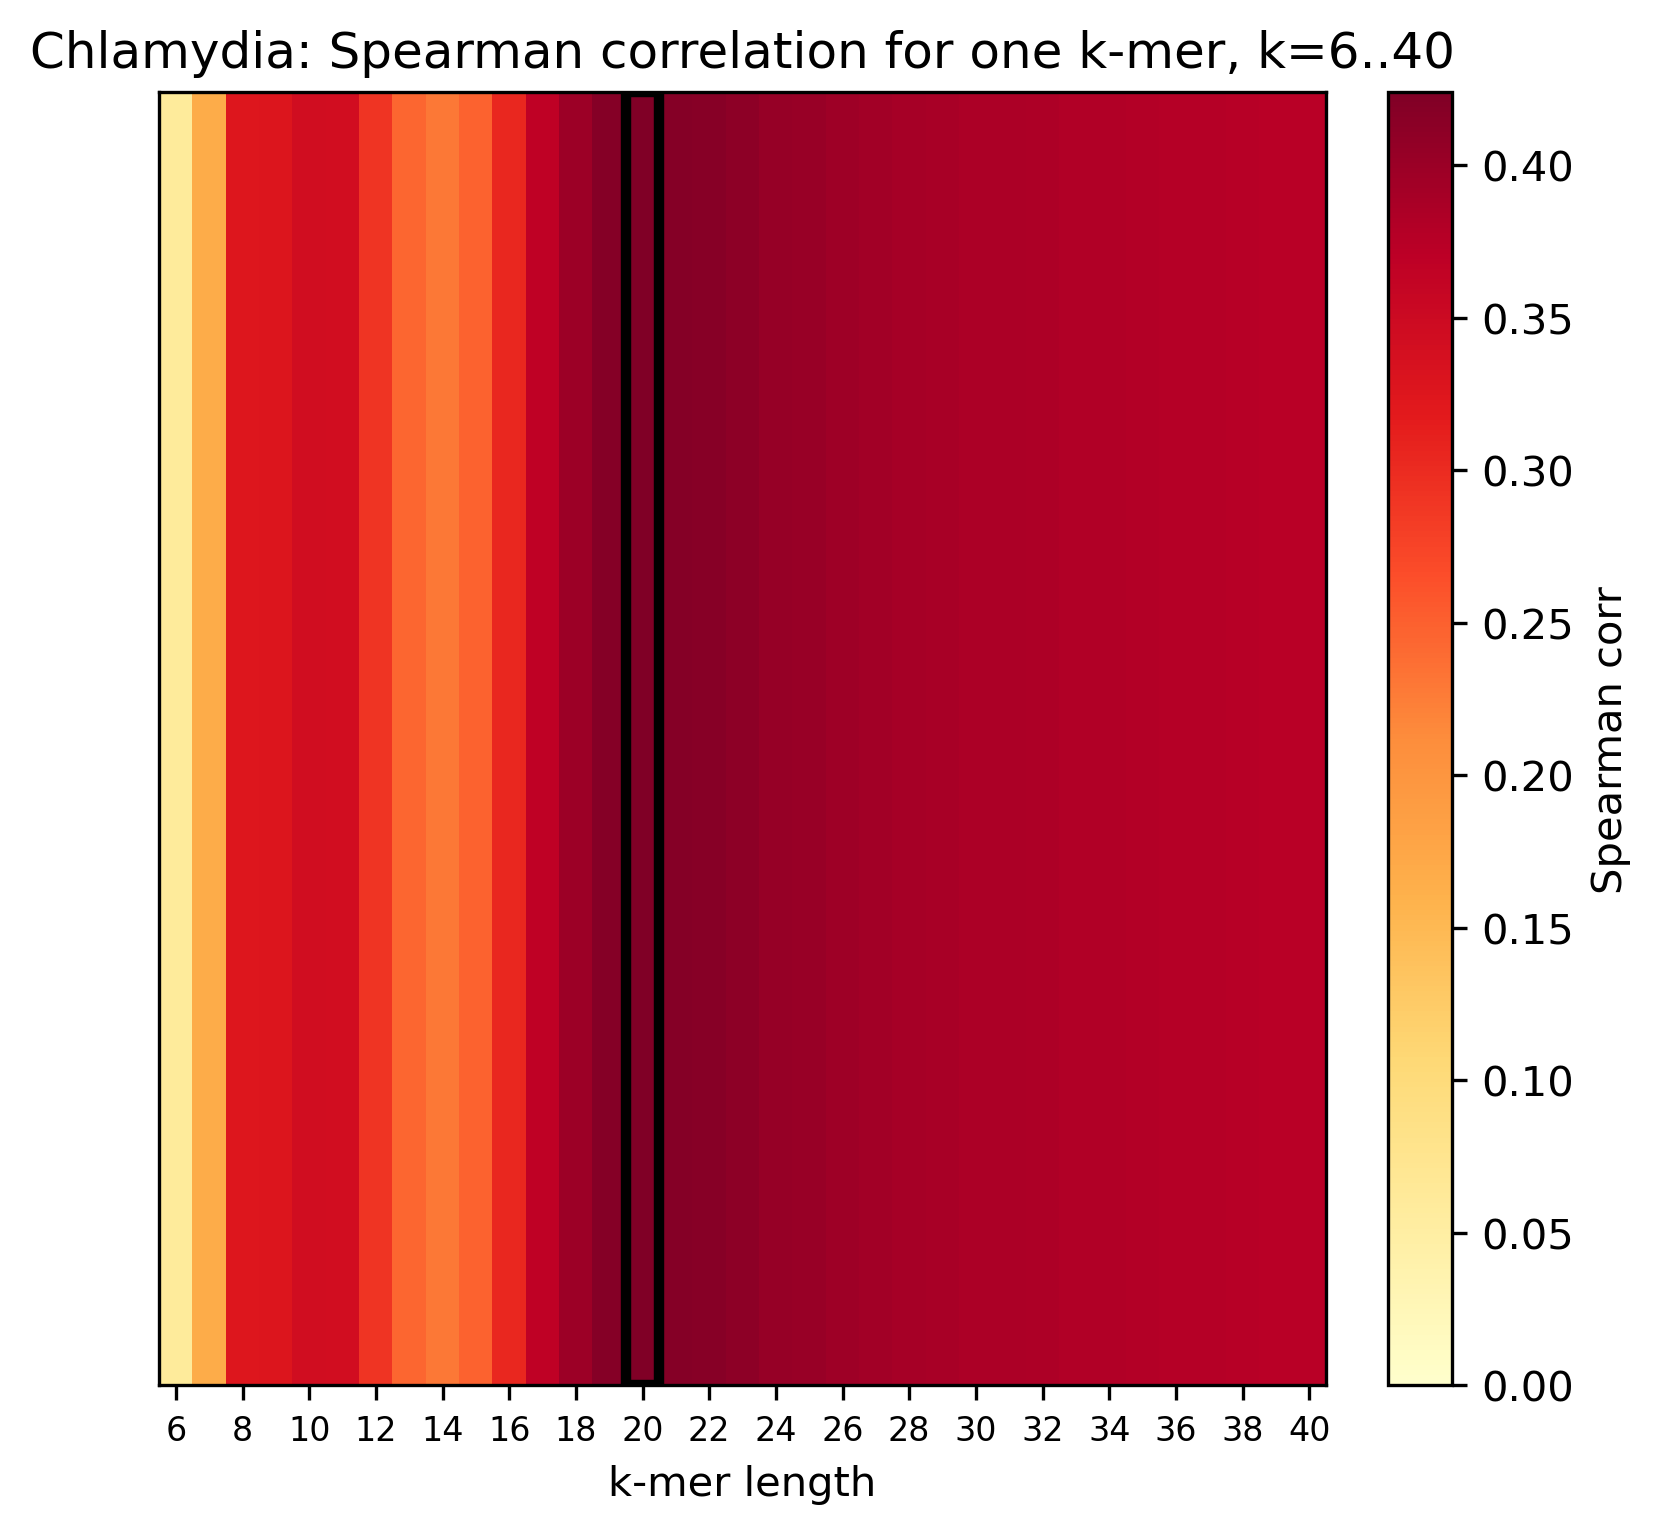


Cyano


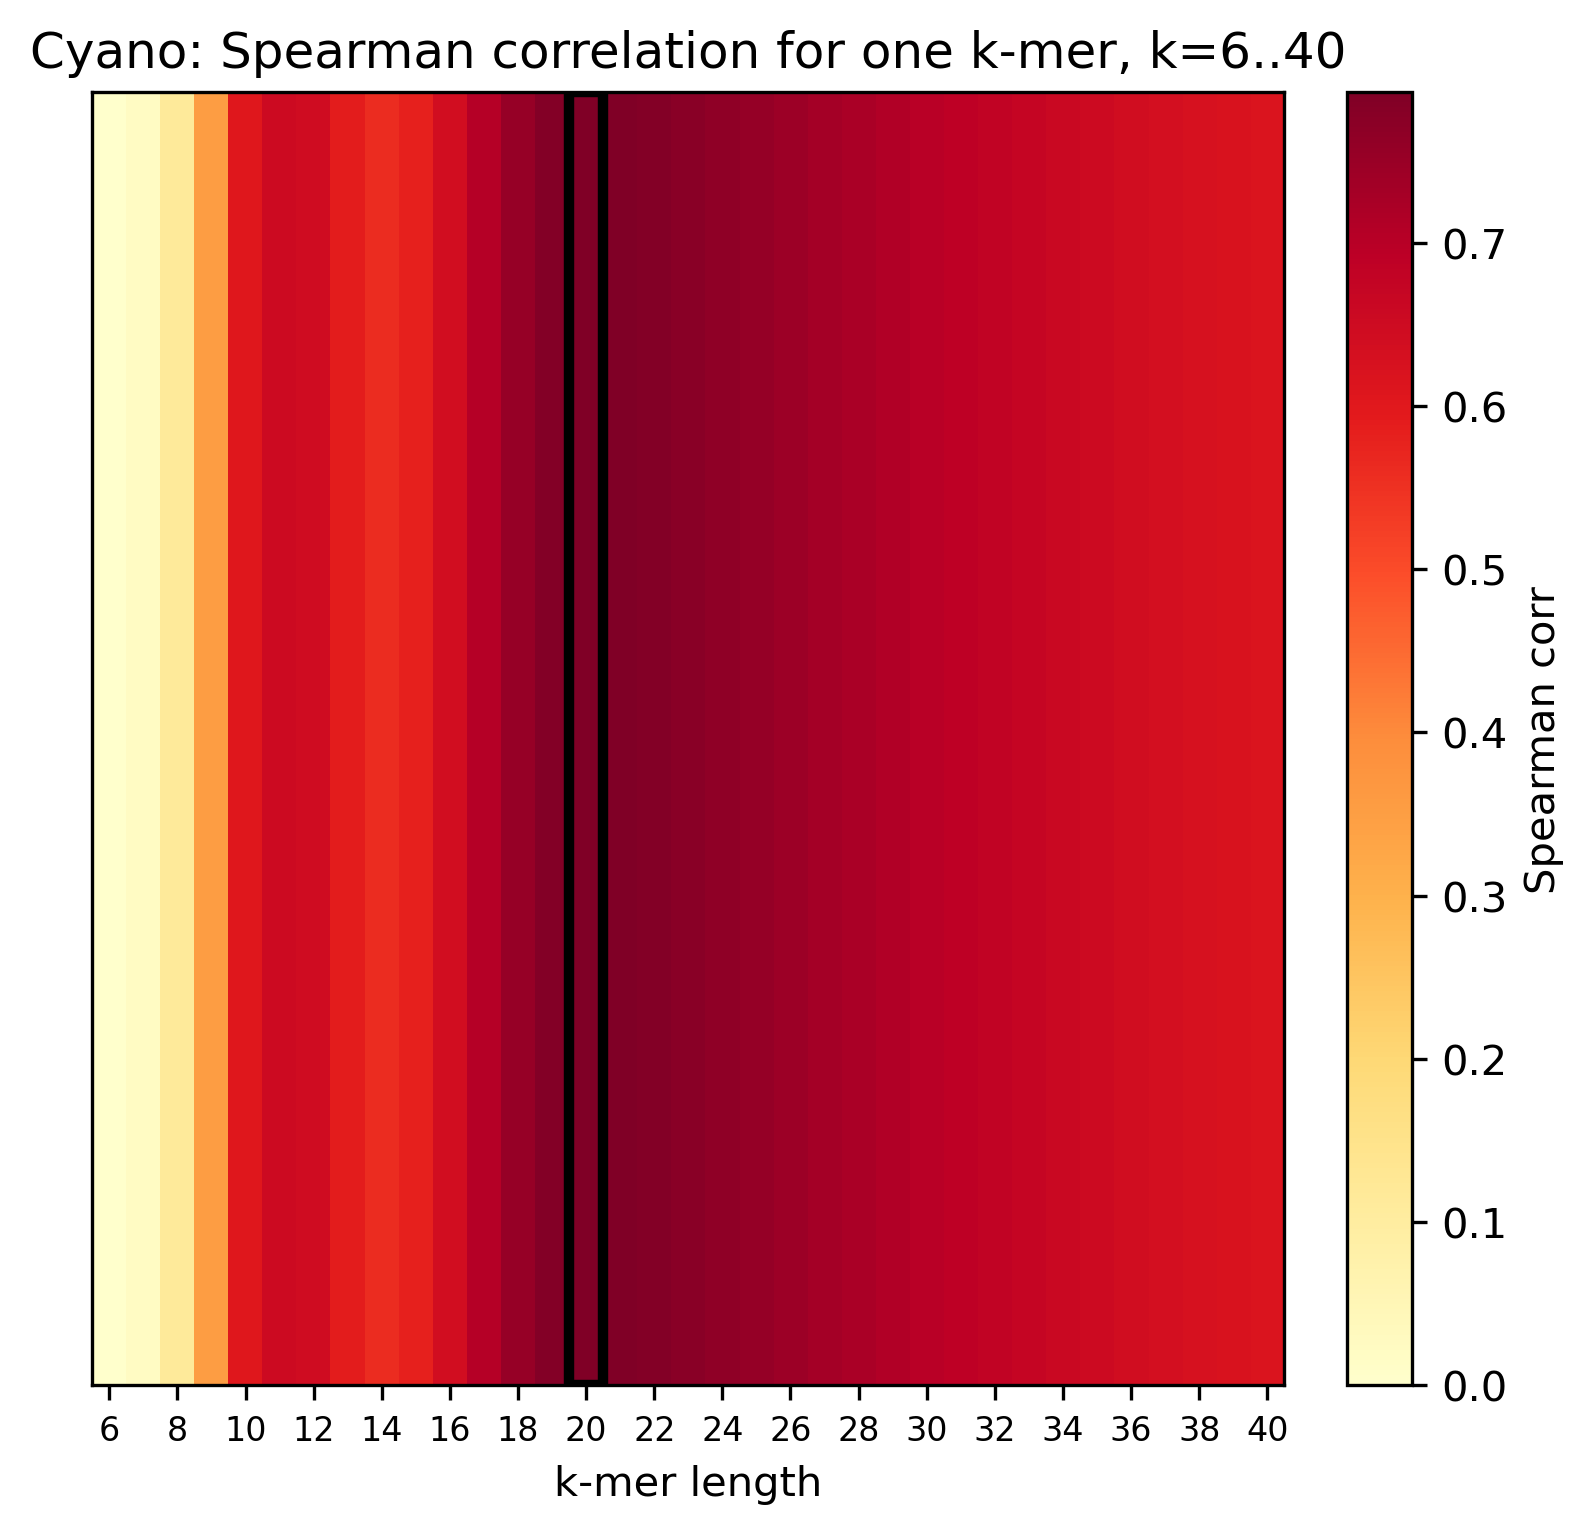


Neisseriaceae


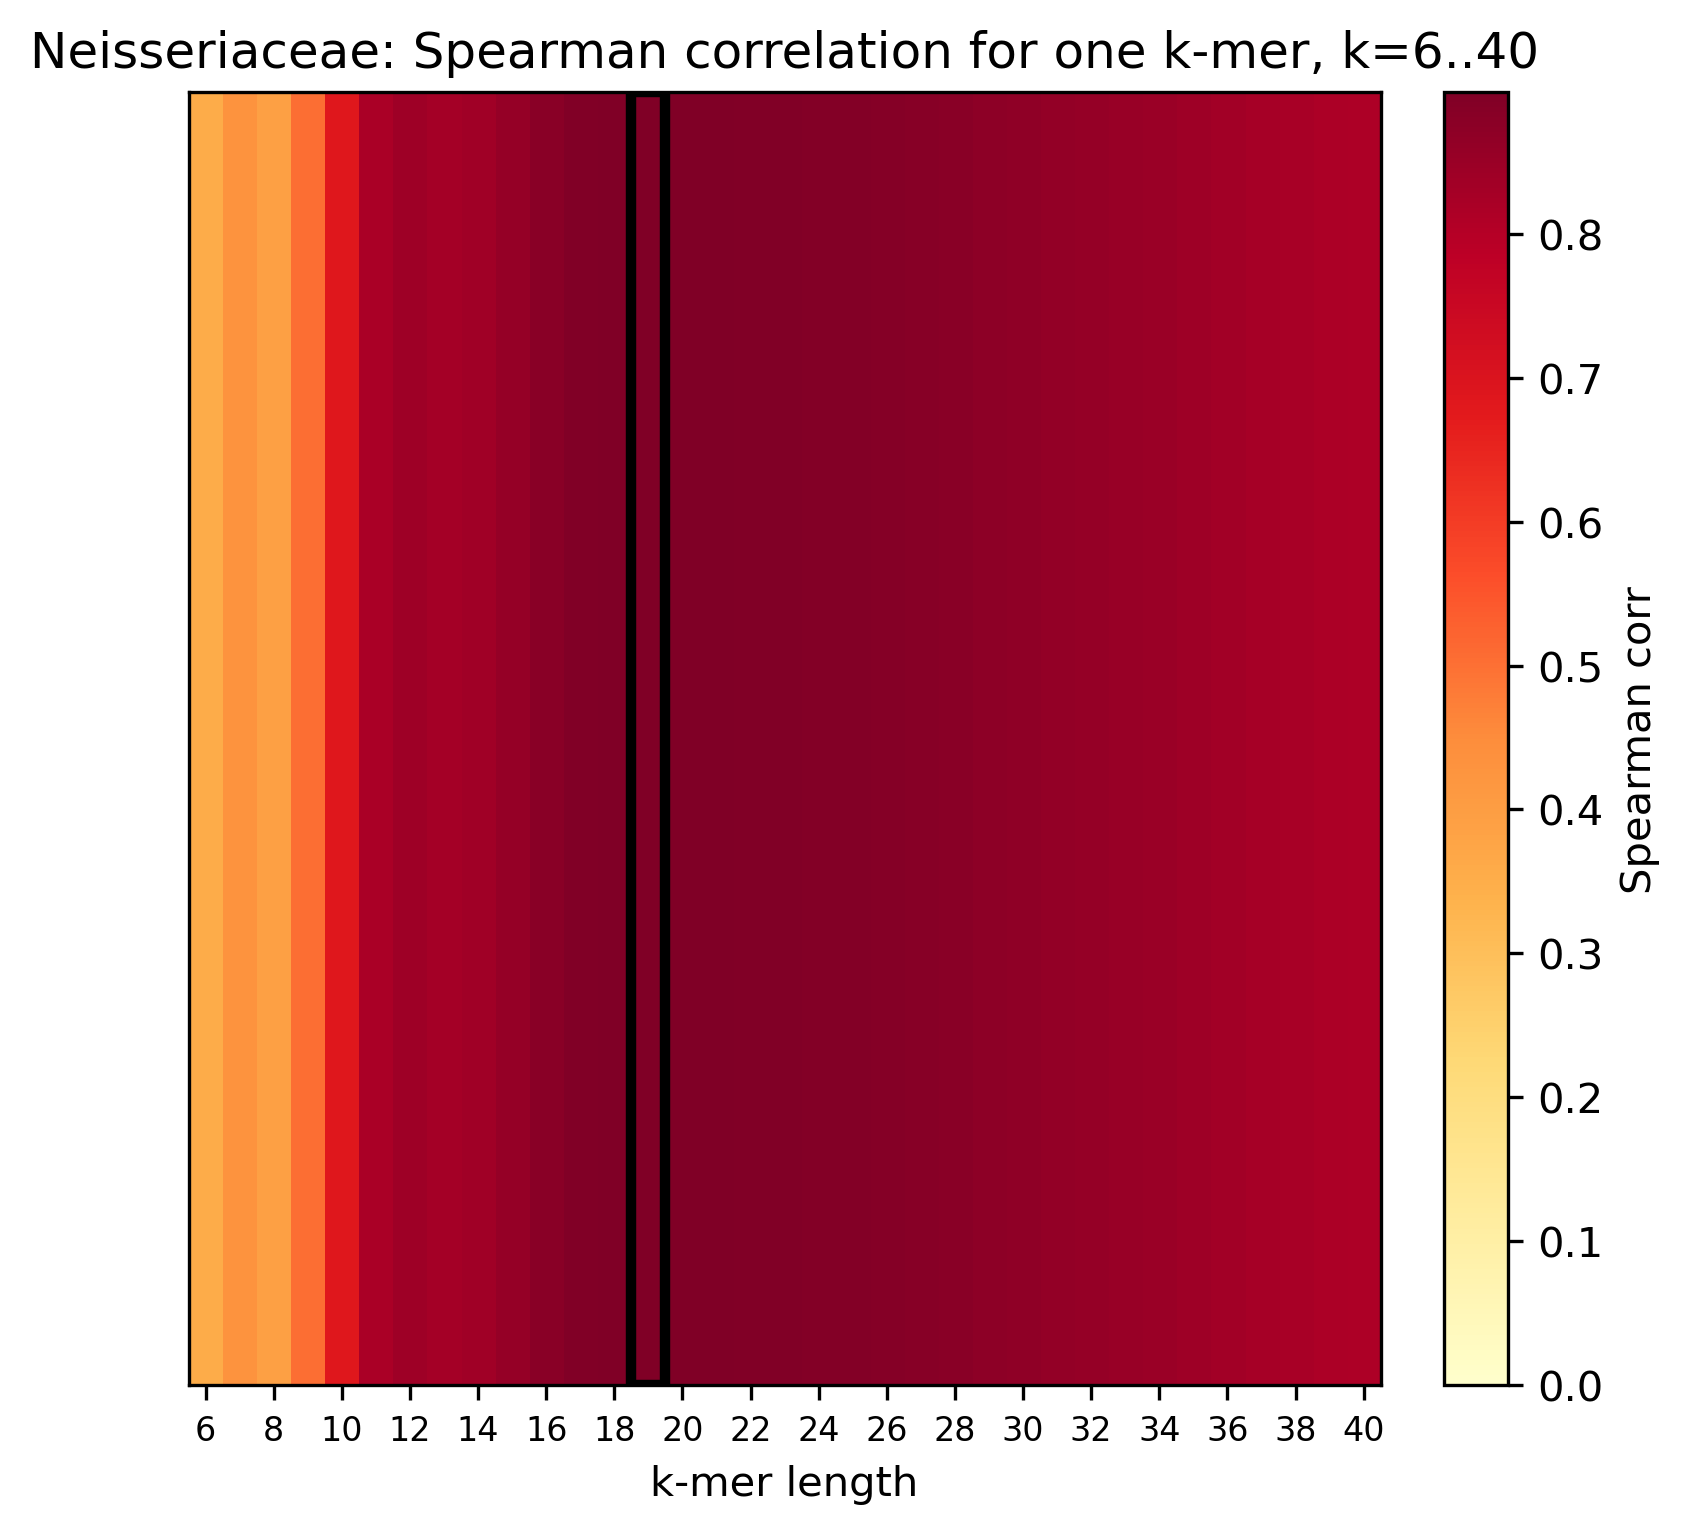

In [8]:
# Run full grid search
for name, merged_df in datasets:
    print(name)
    df, (k, corr, pval) = ok_k_mer.initial_corr(merged_df, k_low=6, k_high=40)
    ok_k_mer.plot_single_corr_colorbar(name, df, k_low=6, k_high=40)
    print()


### Two k-mers


In [9]:
# Load data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_2k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_2k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_2k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_slurm_tensor_2k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_2k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neis_slurm_tensor_2k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_2k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

Aquificota
(array([28]), array([14])) 0.6930305020275189


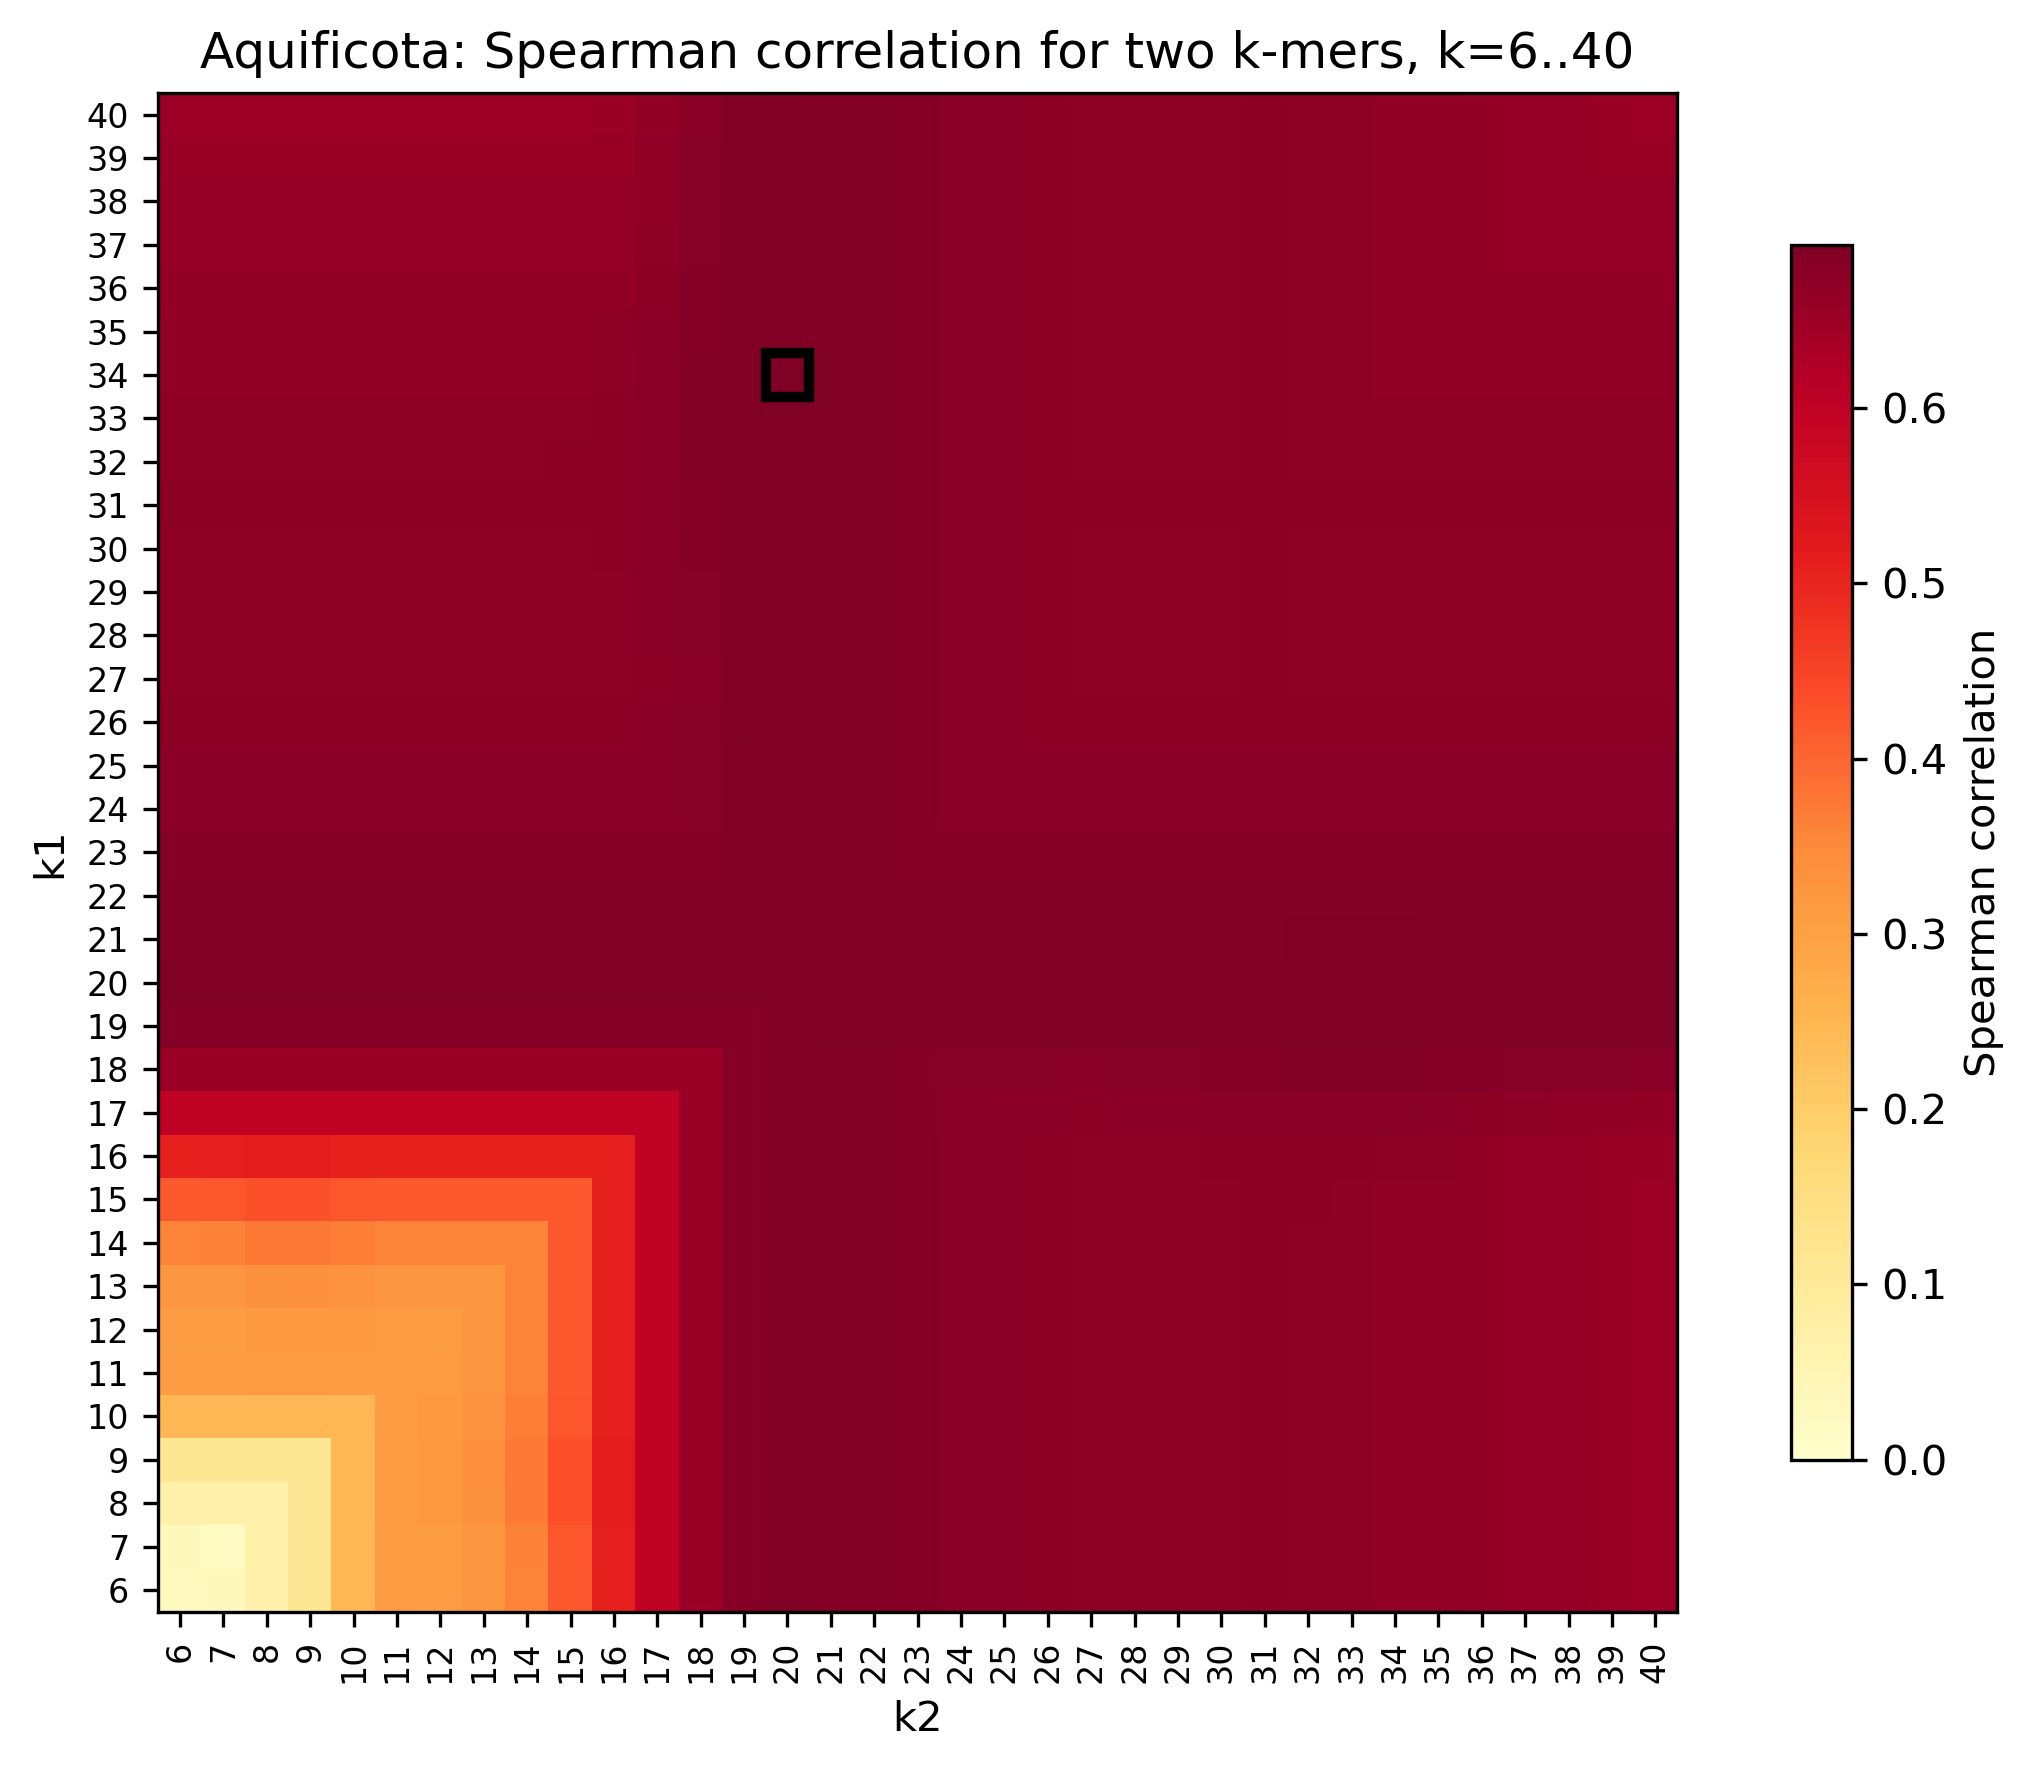

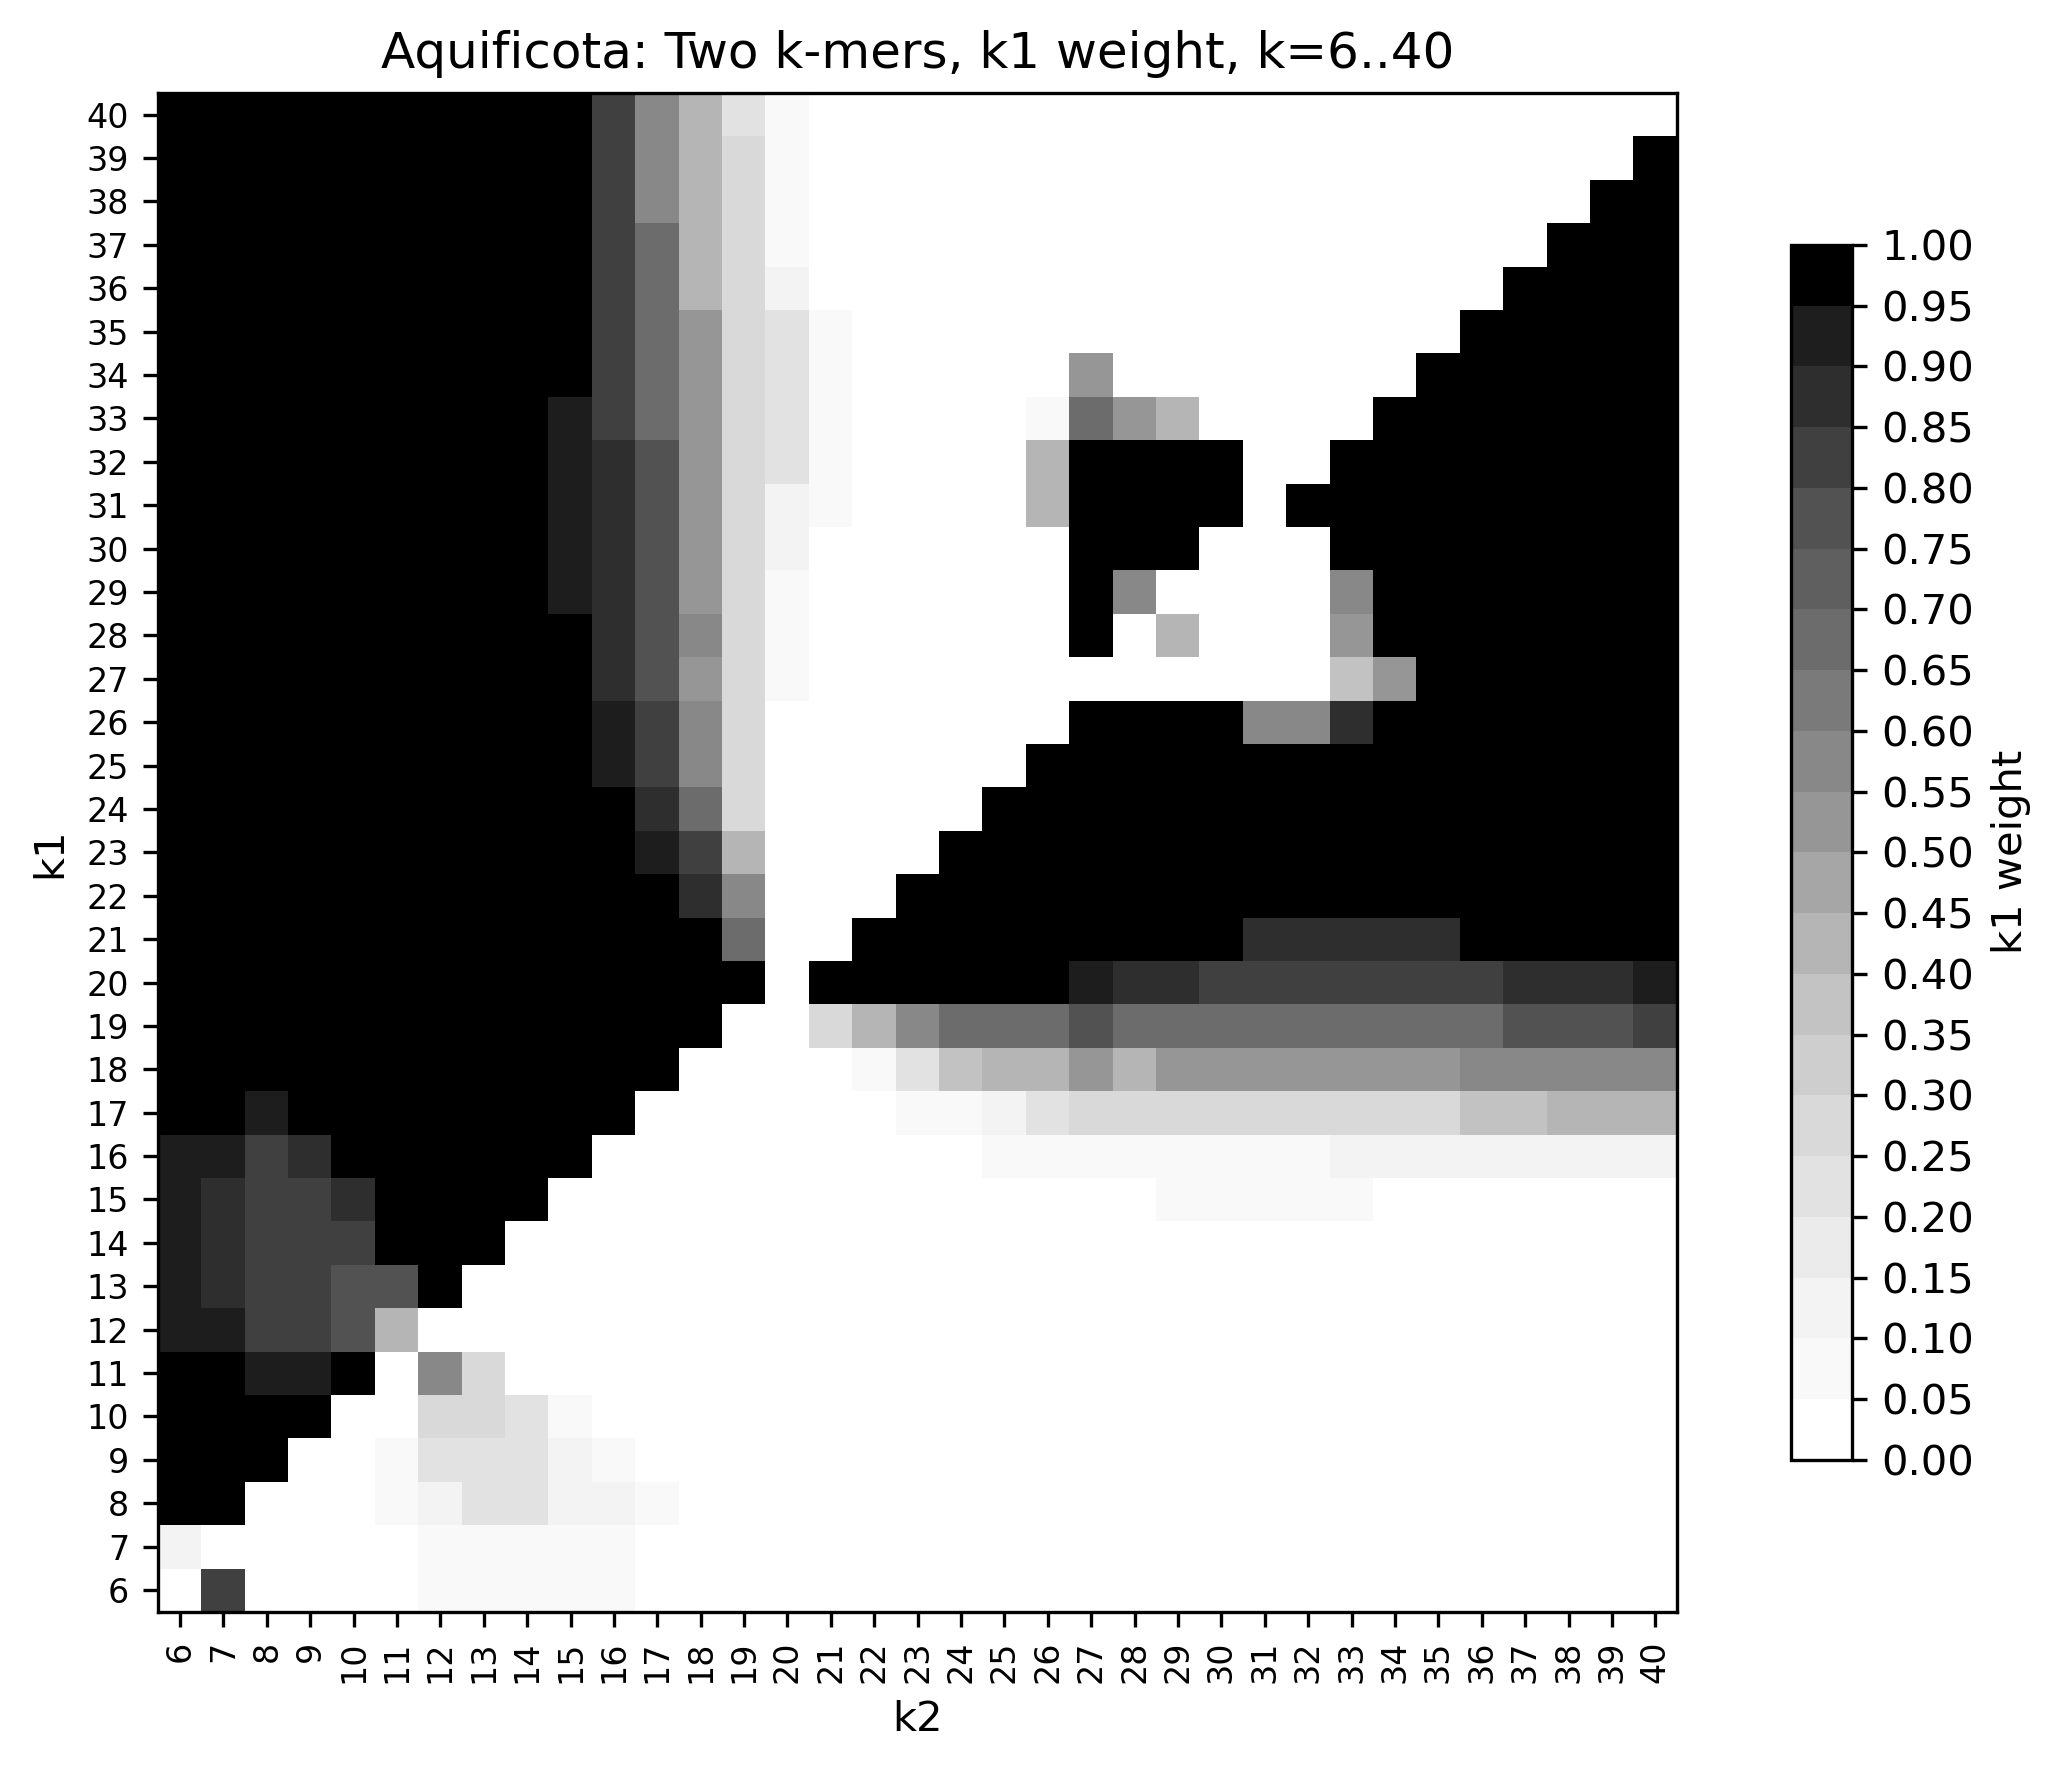


Bacillales
(array([ 1, 17]), array([17,  1])) 0.6993156409948573


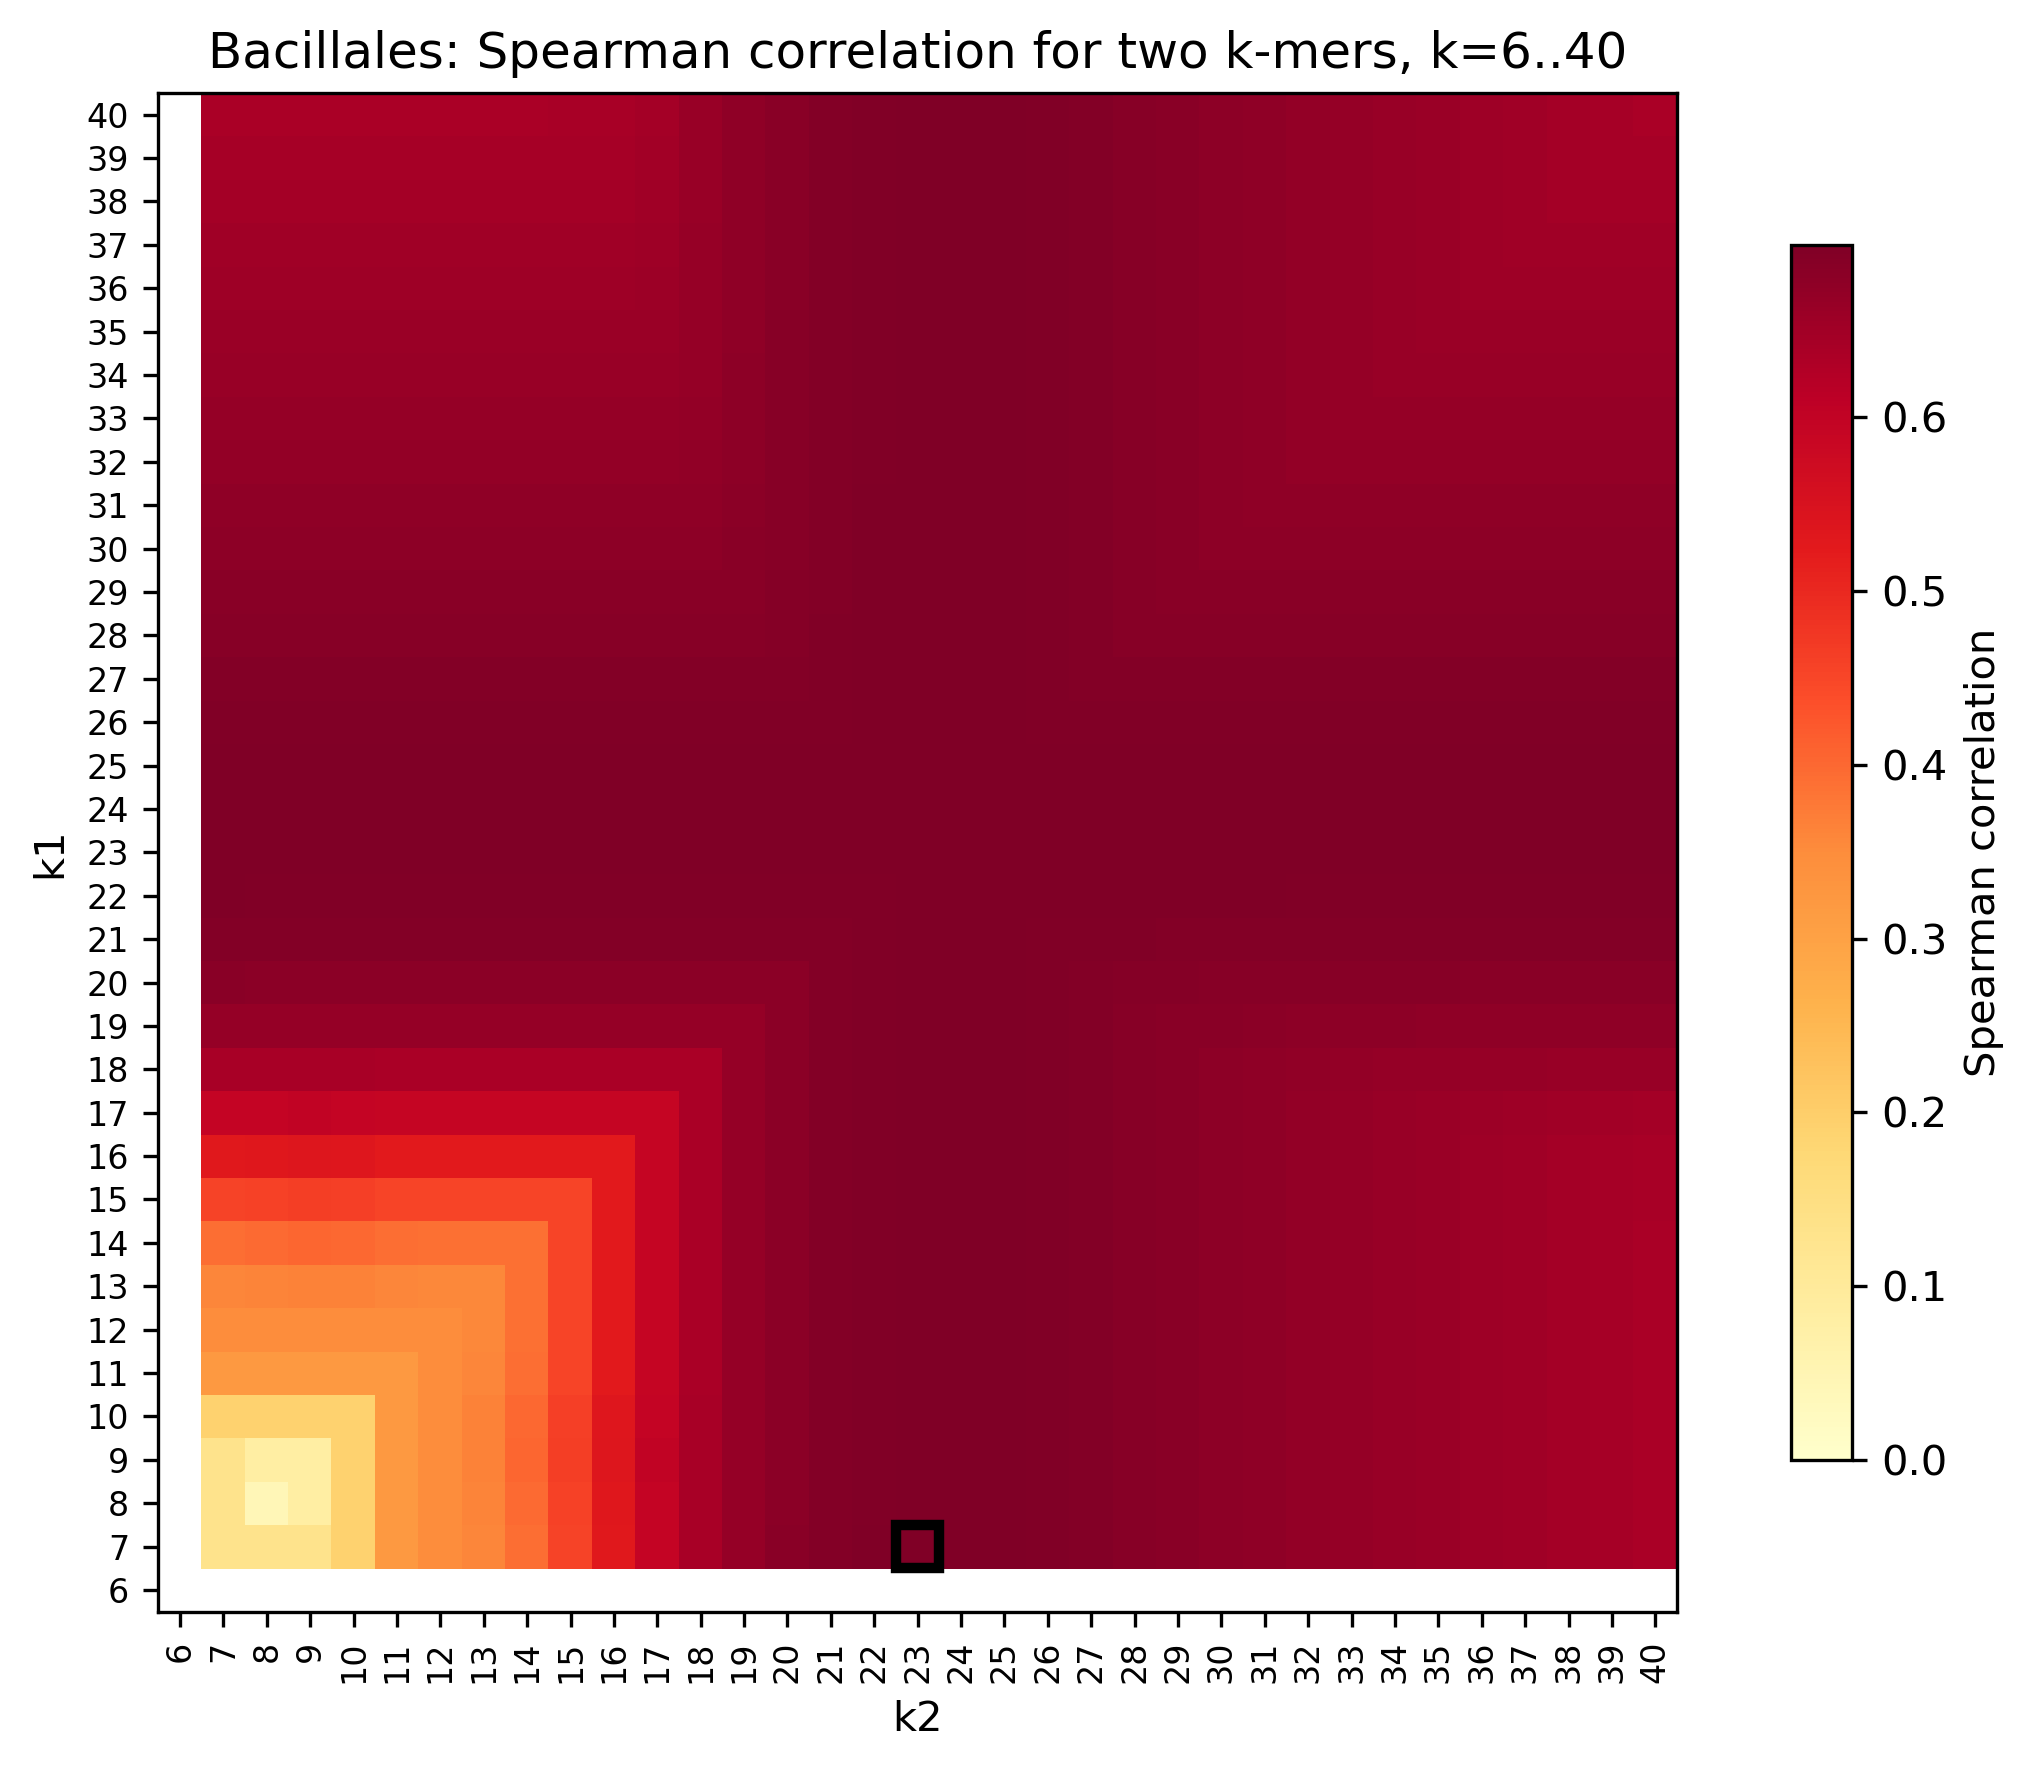

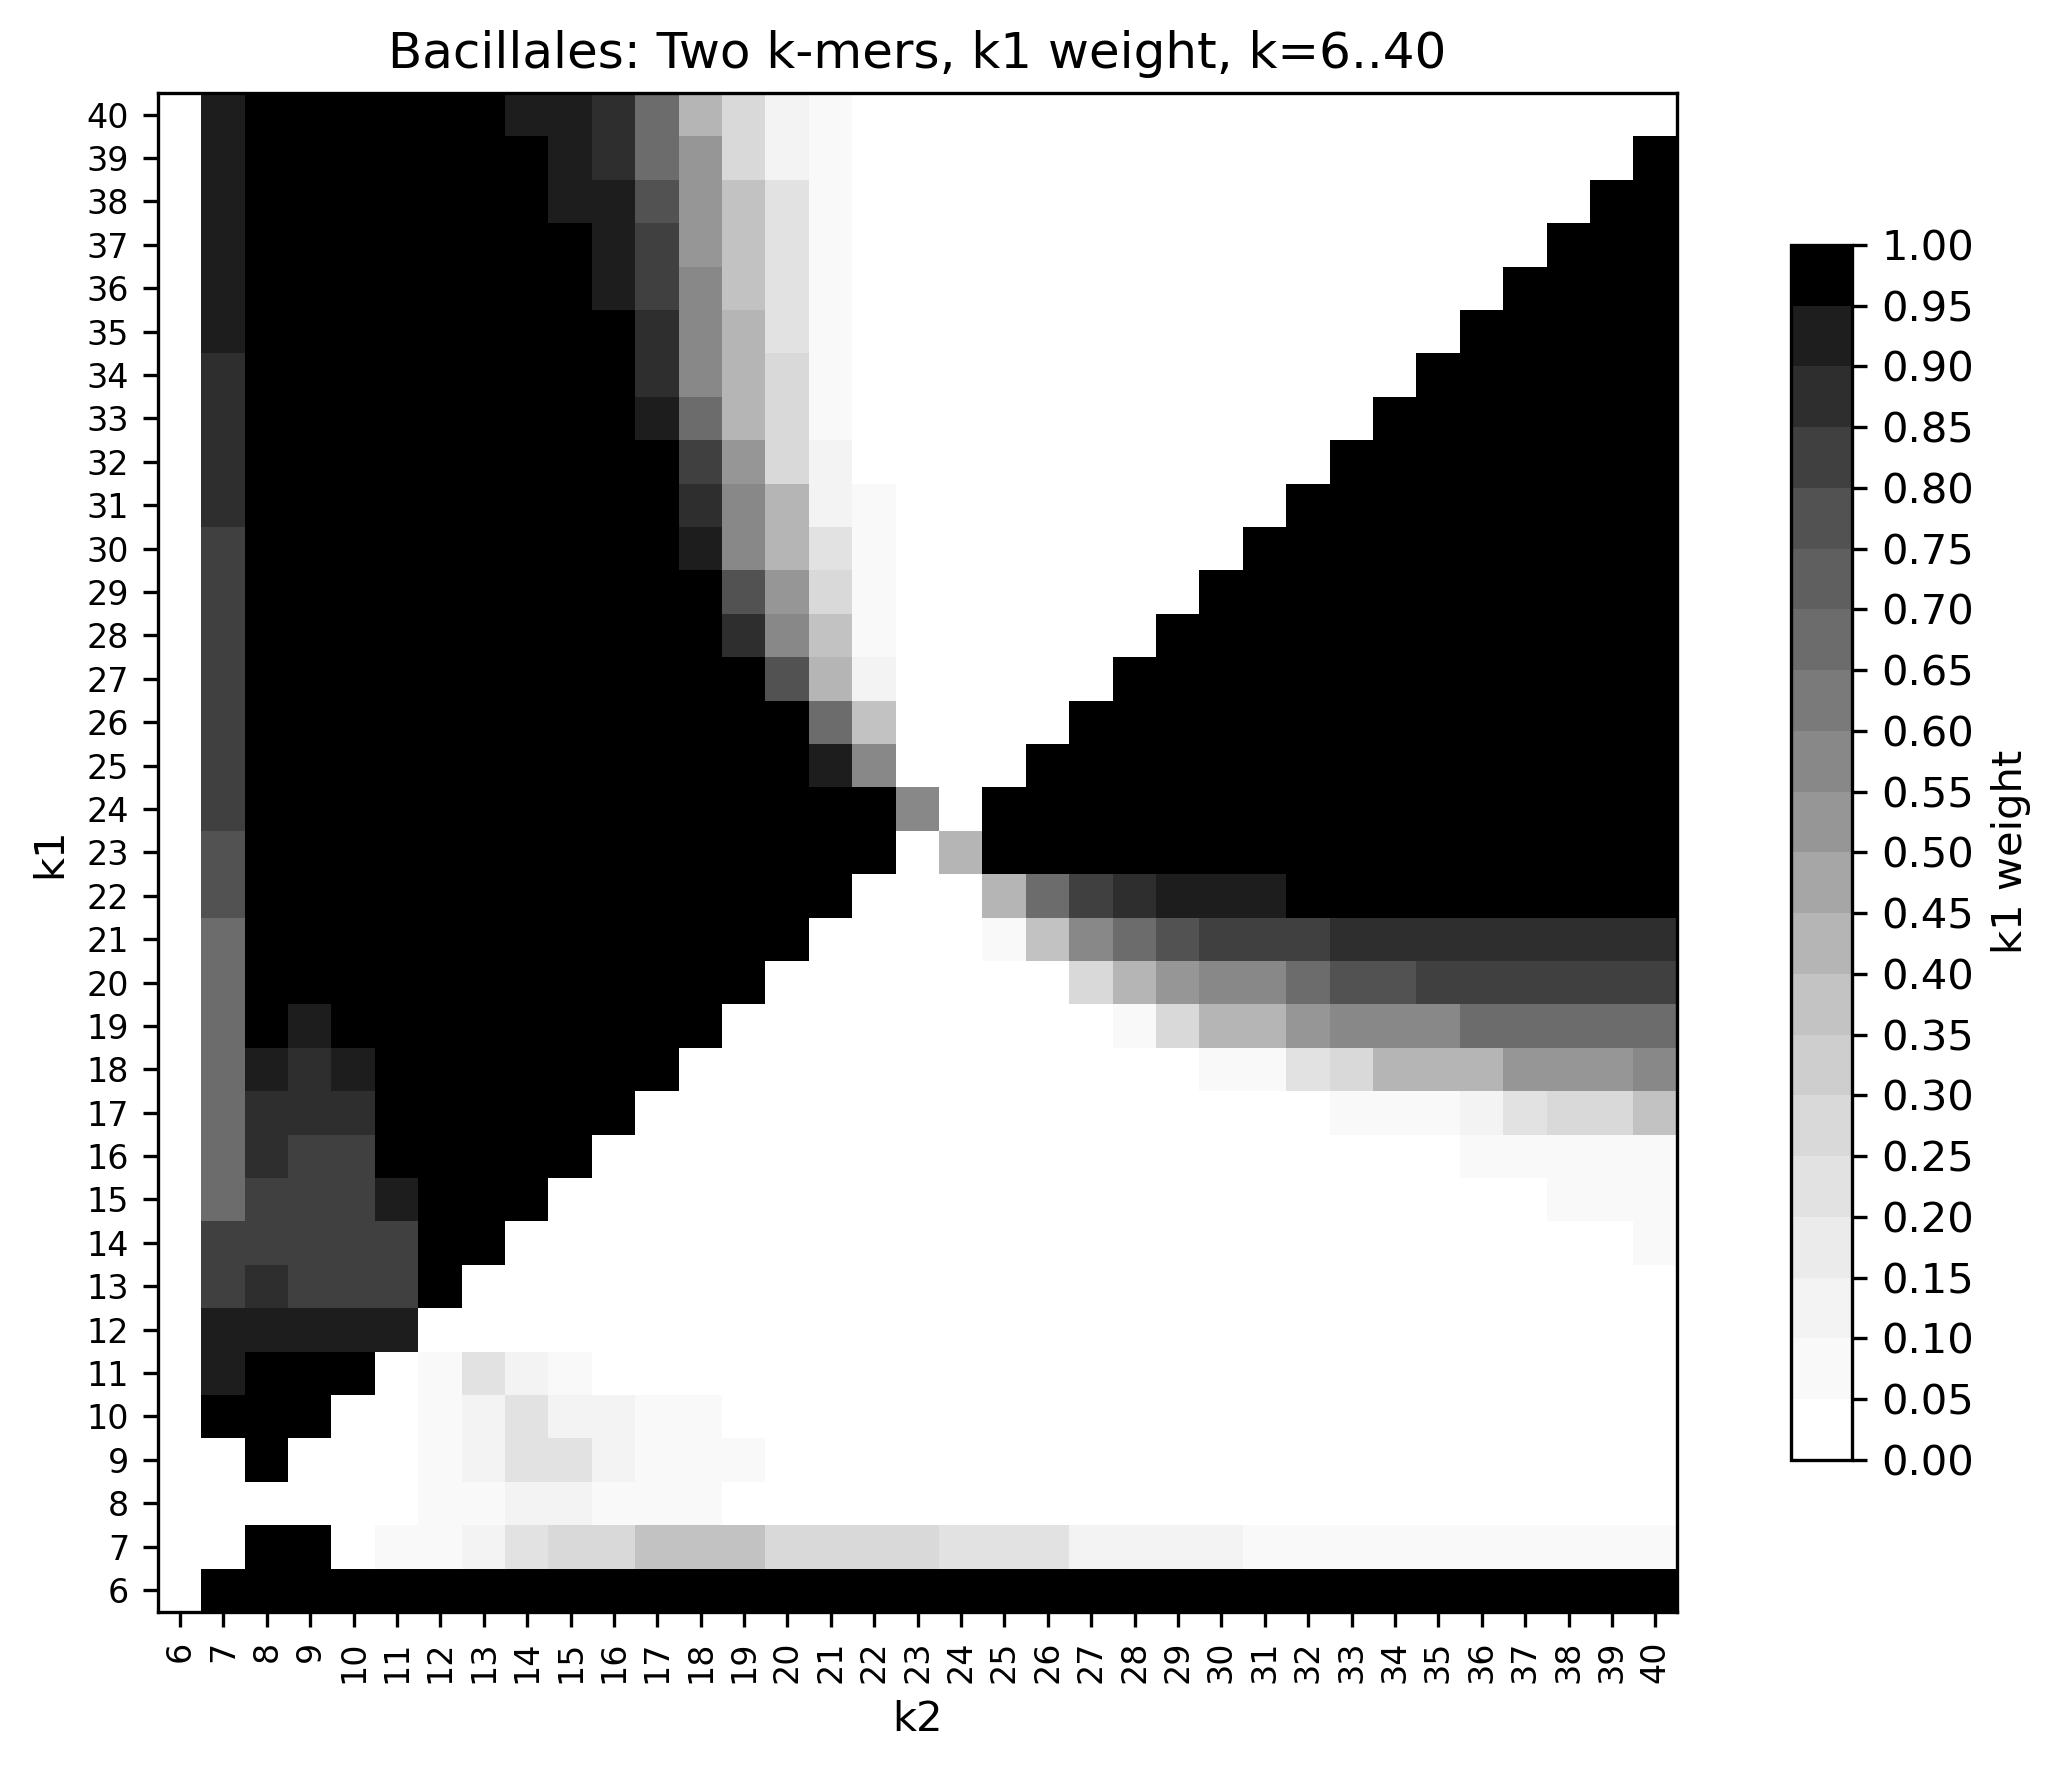


Caldisericia
(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34]), array([14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,  0,  1,  2,
        3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
       20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
       14])) 0.7732939230754757


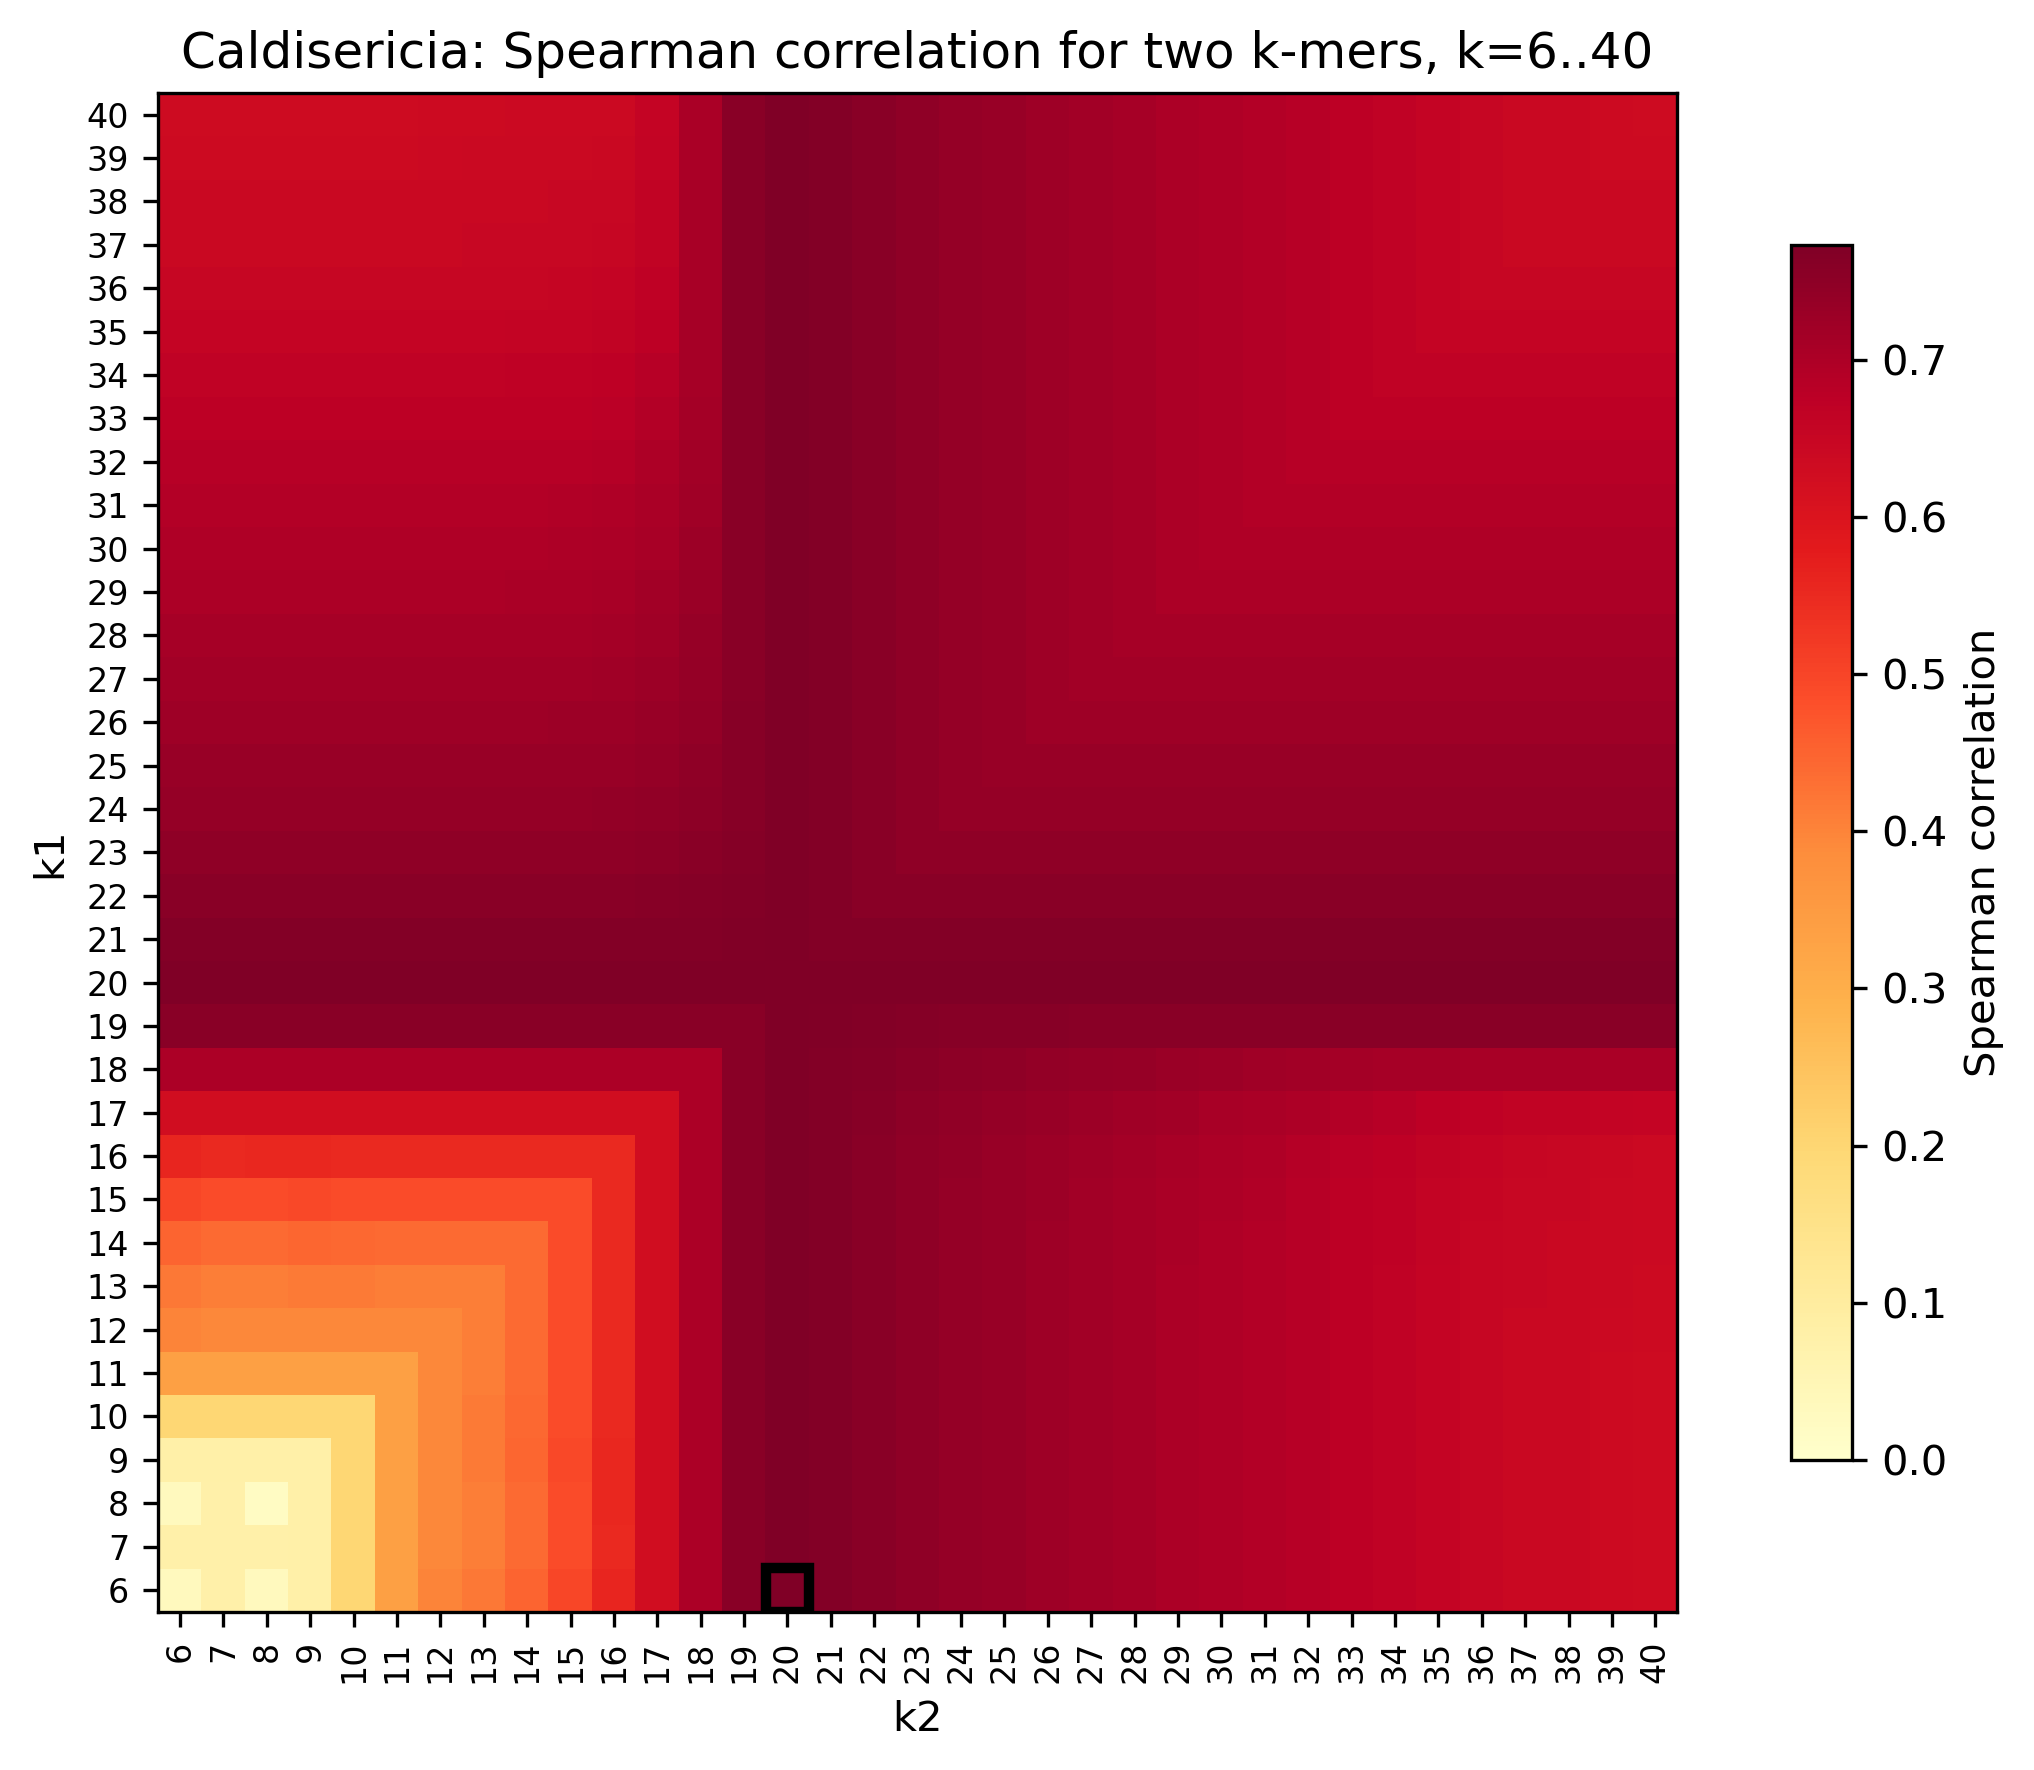

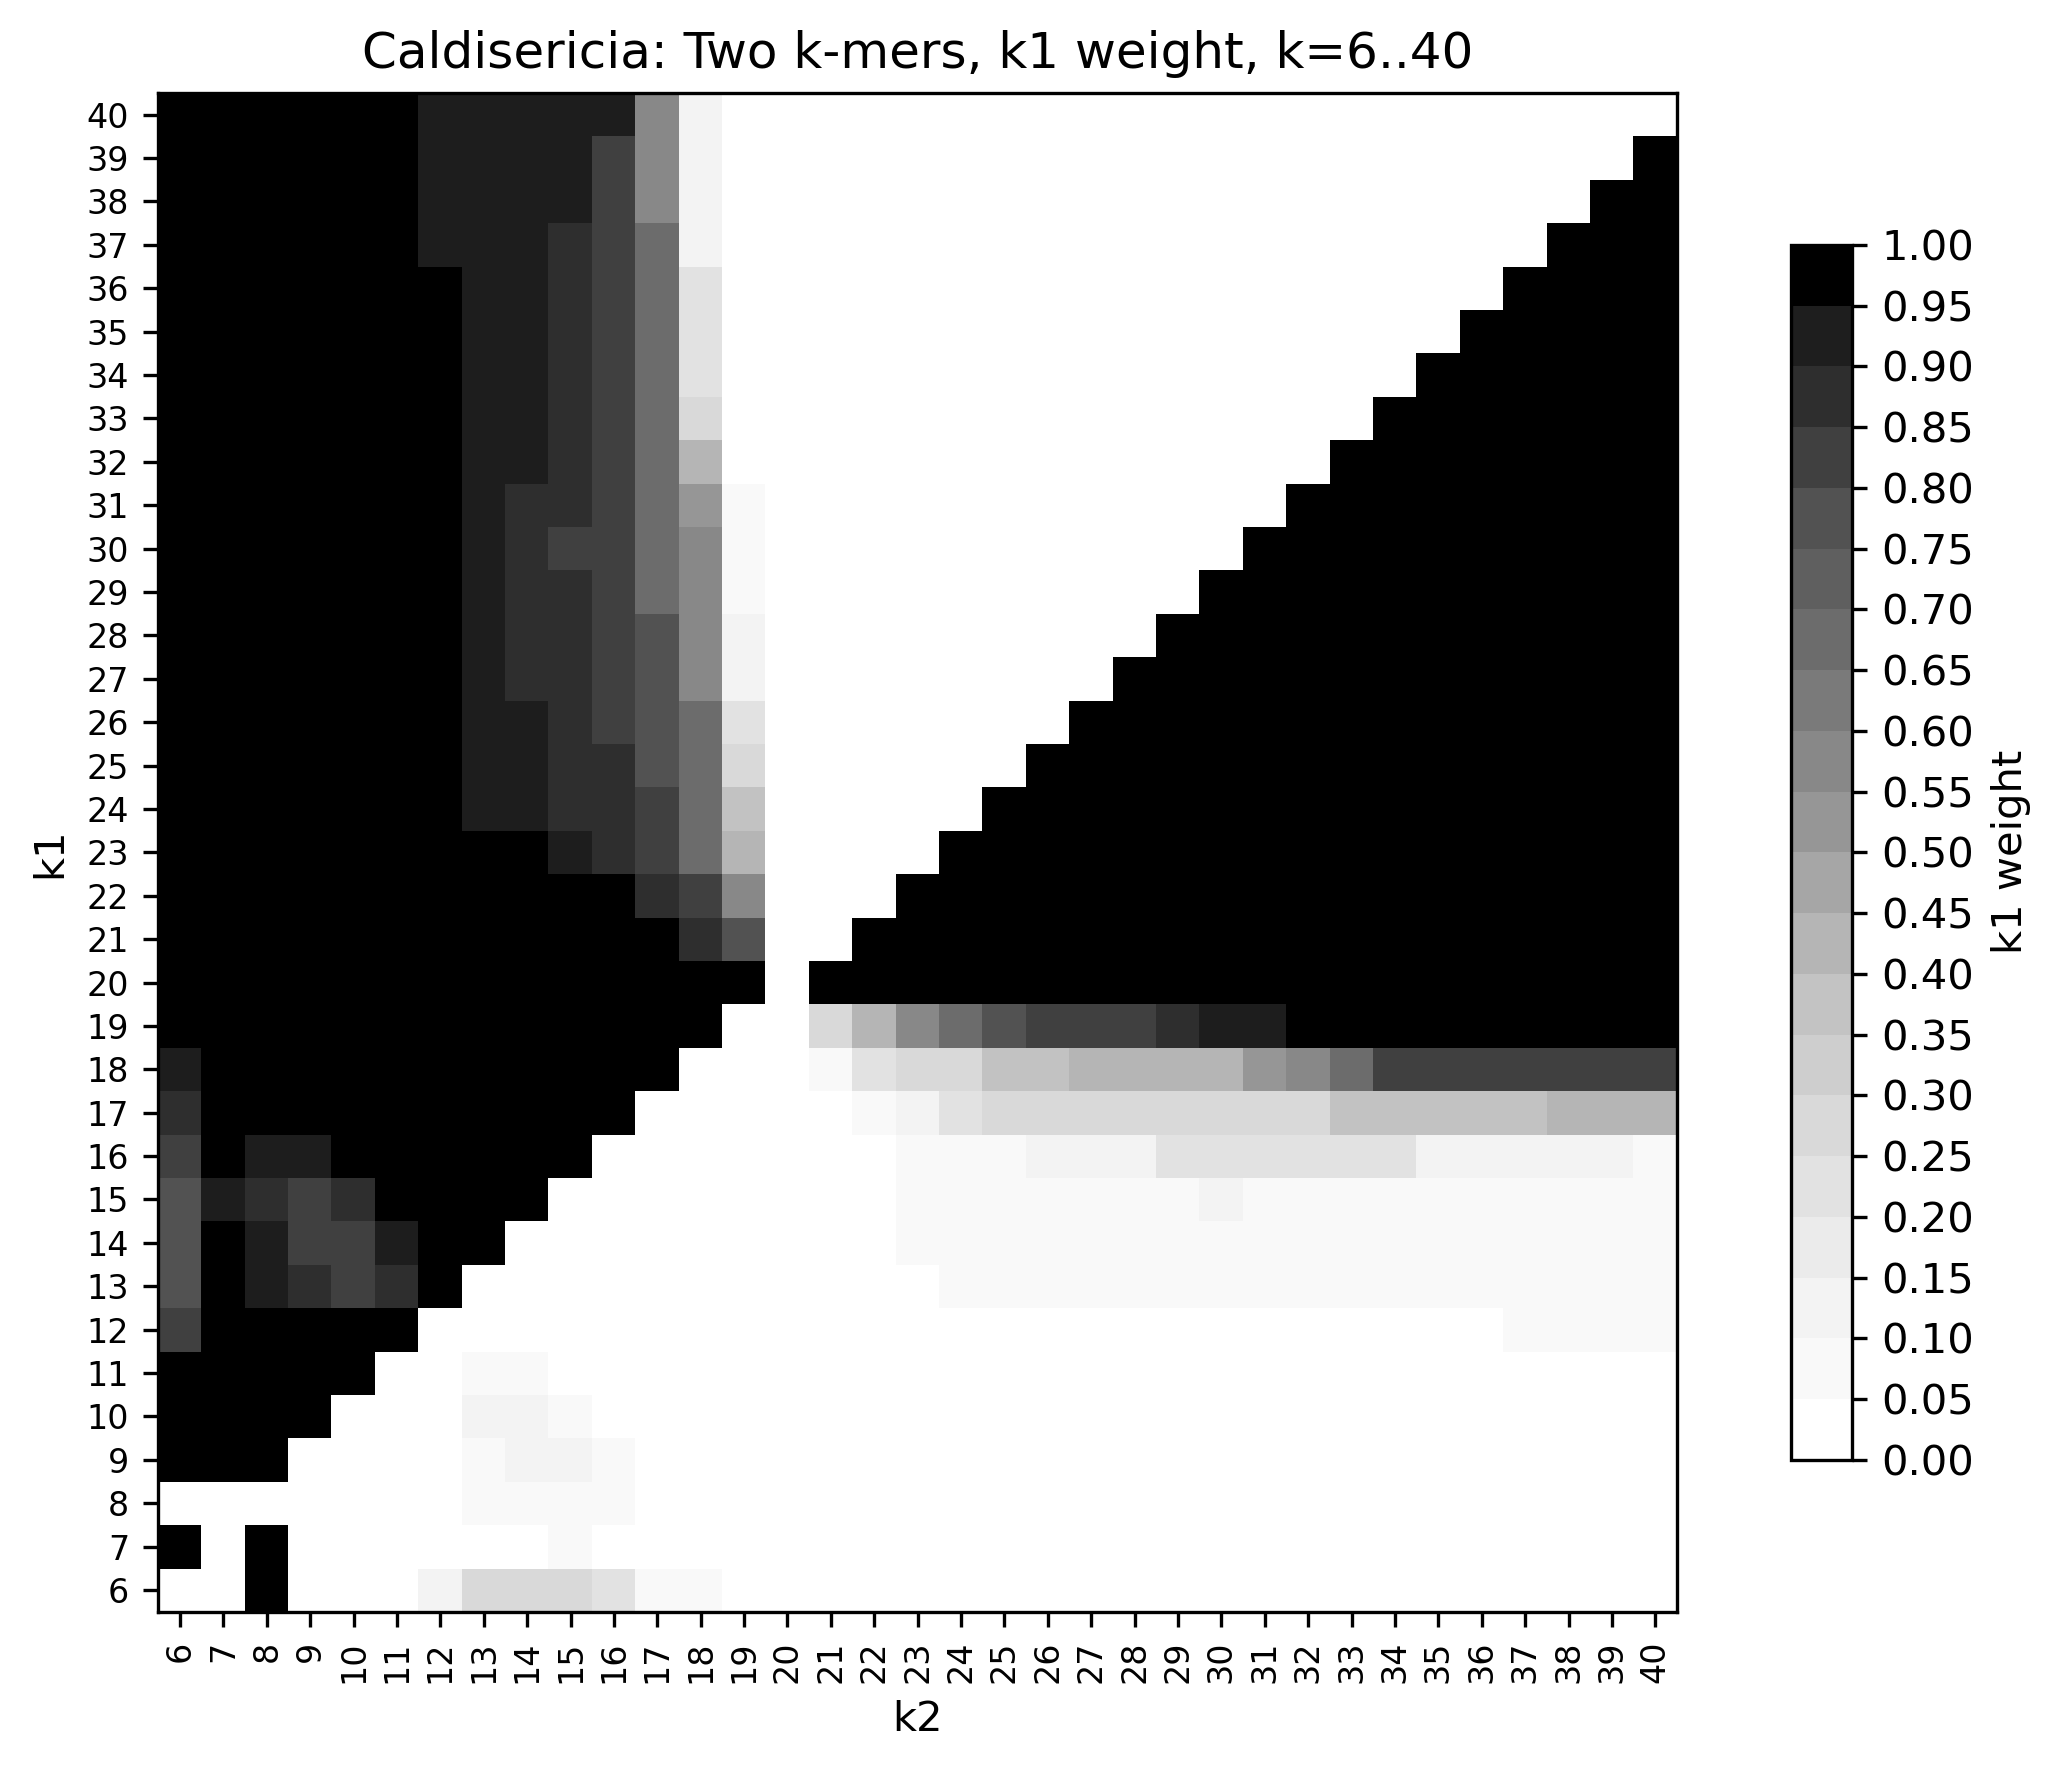


Chlamydia
(array([3]), array([12])) 0.5132143691921338


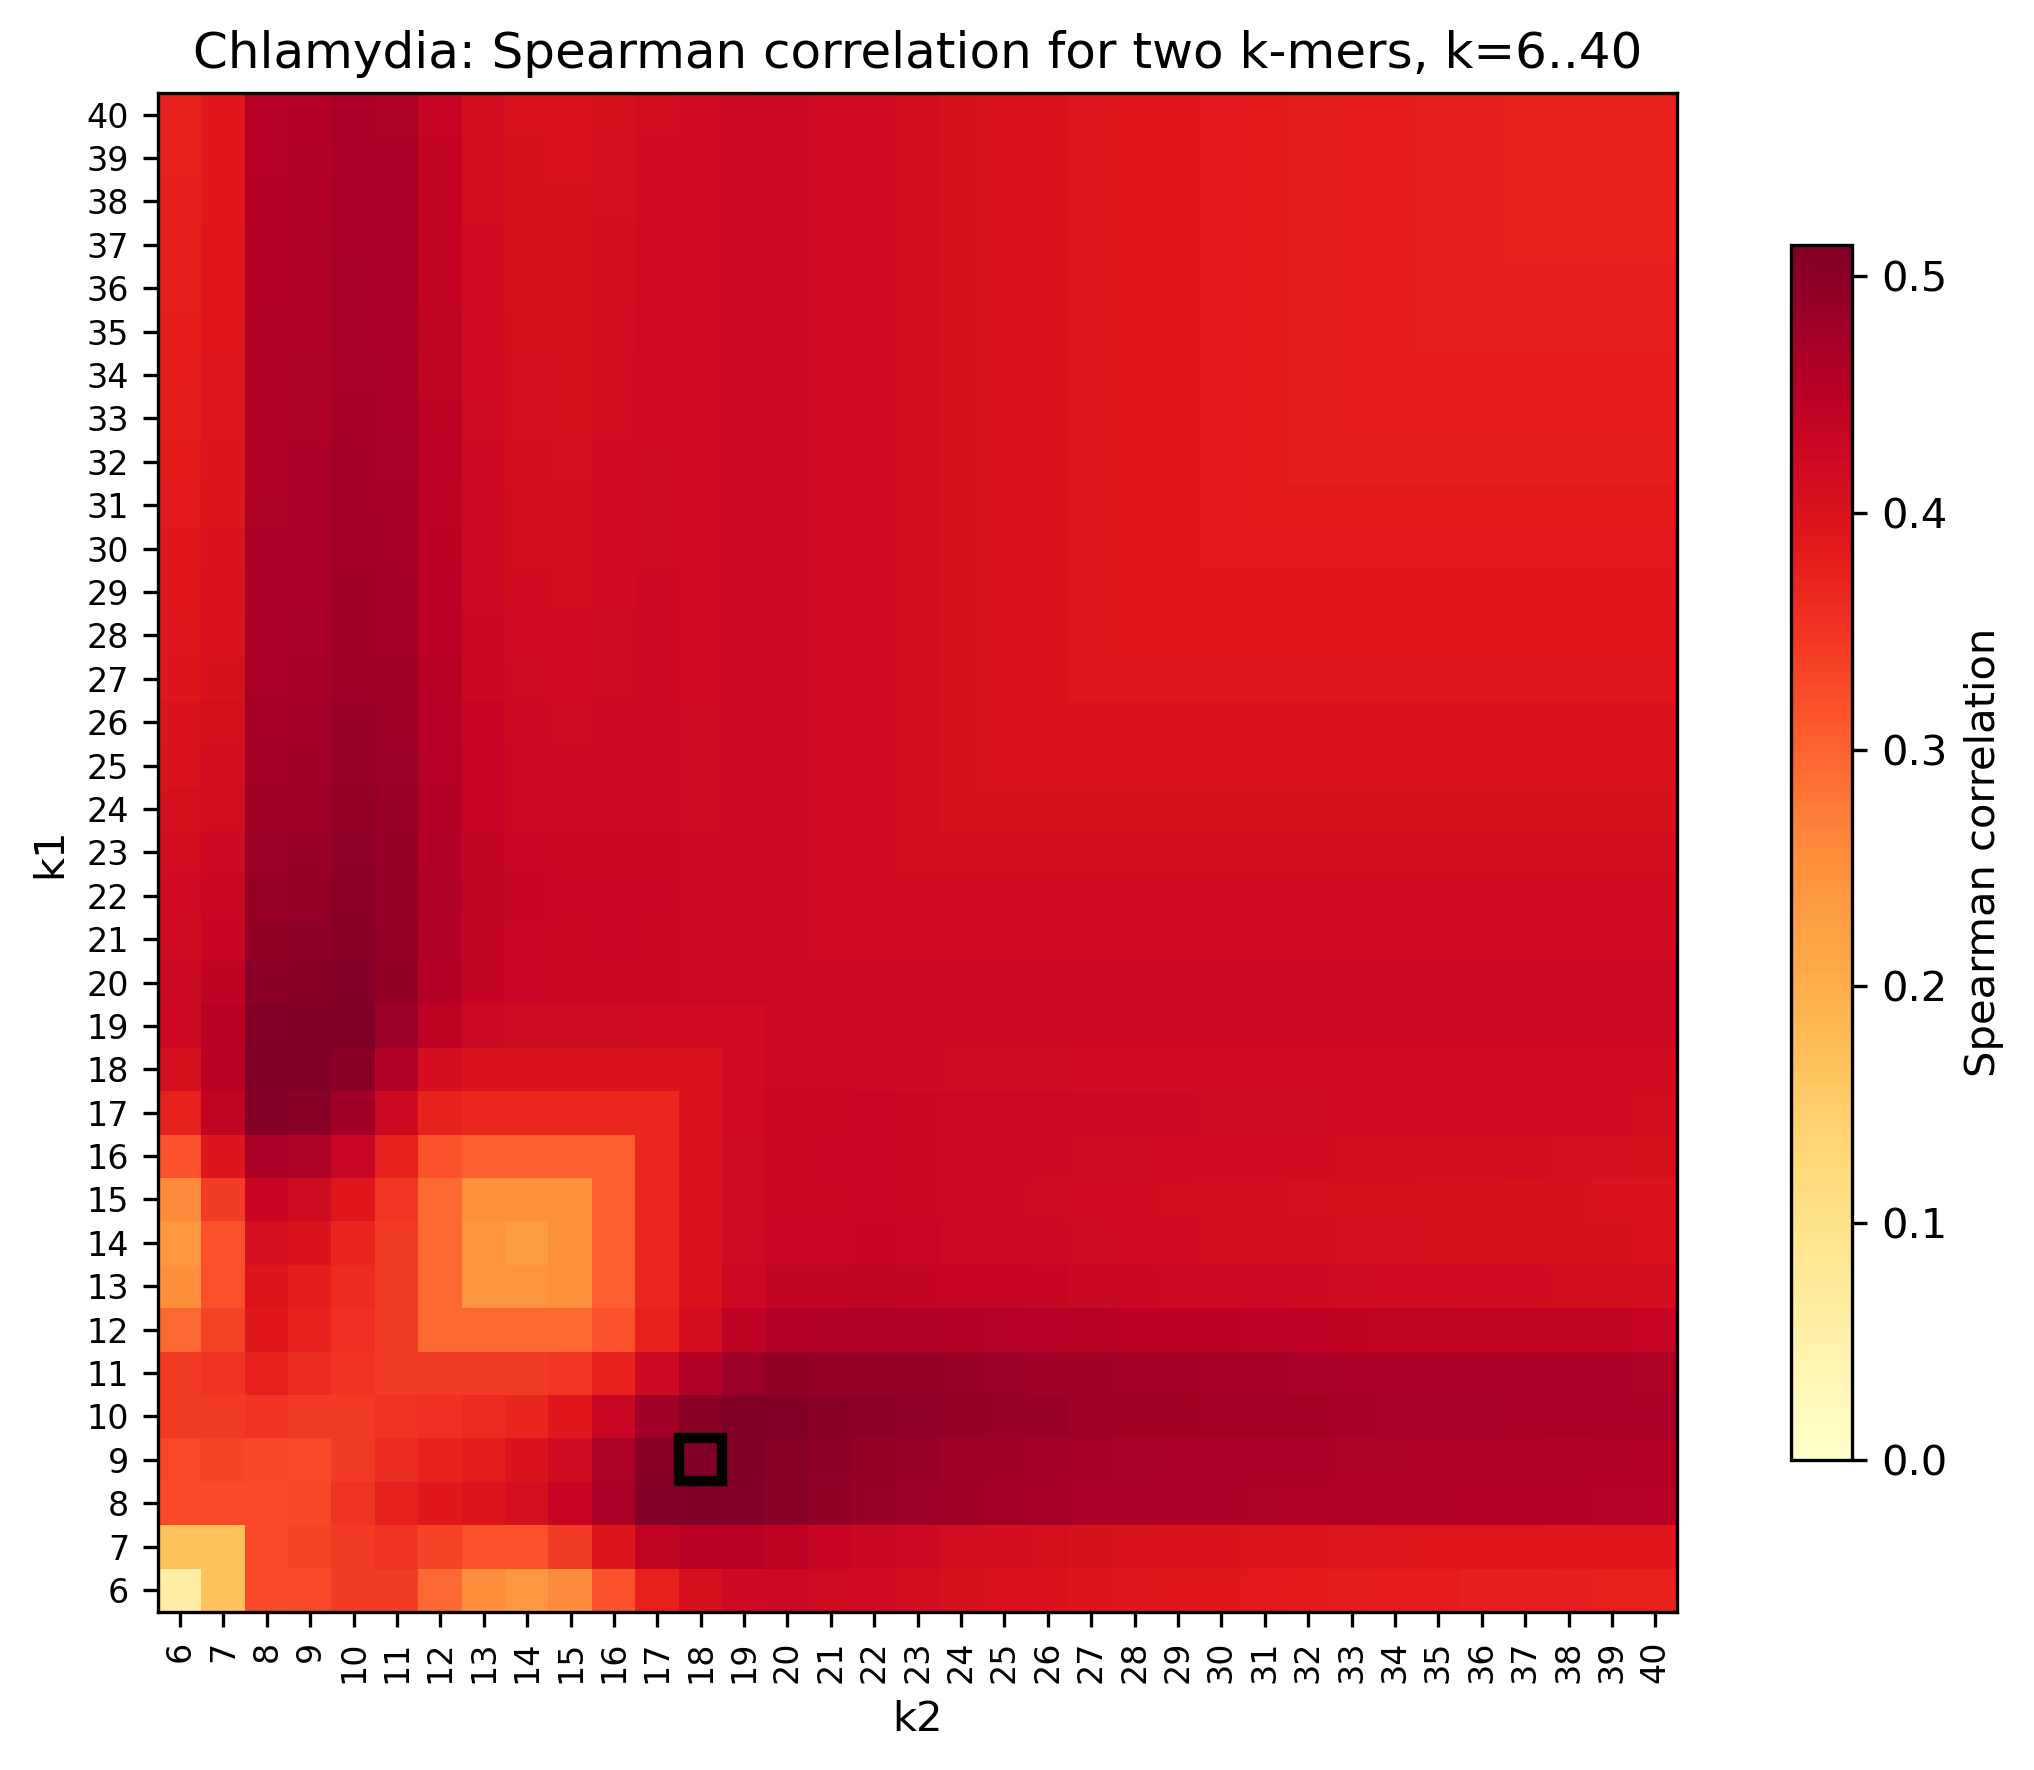

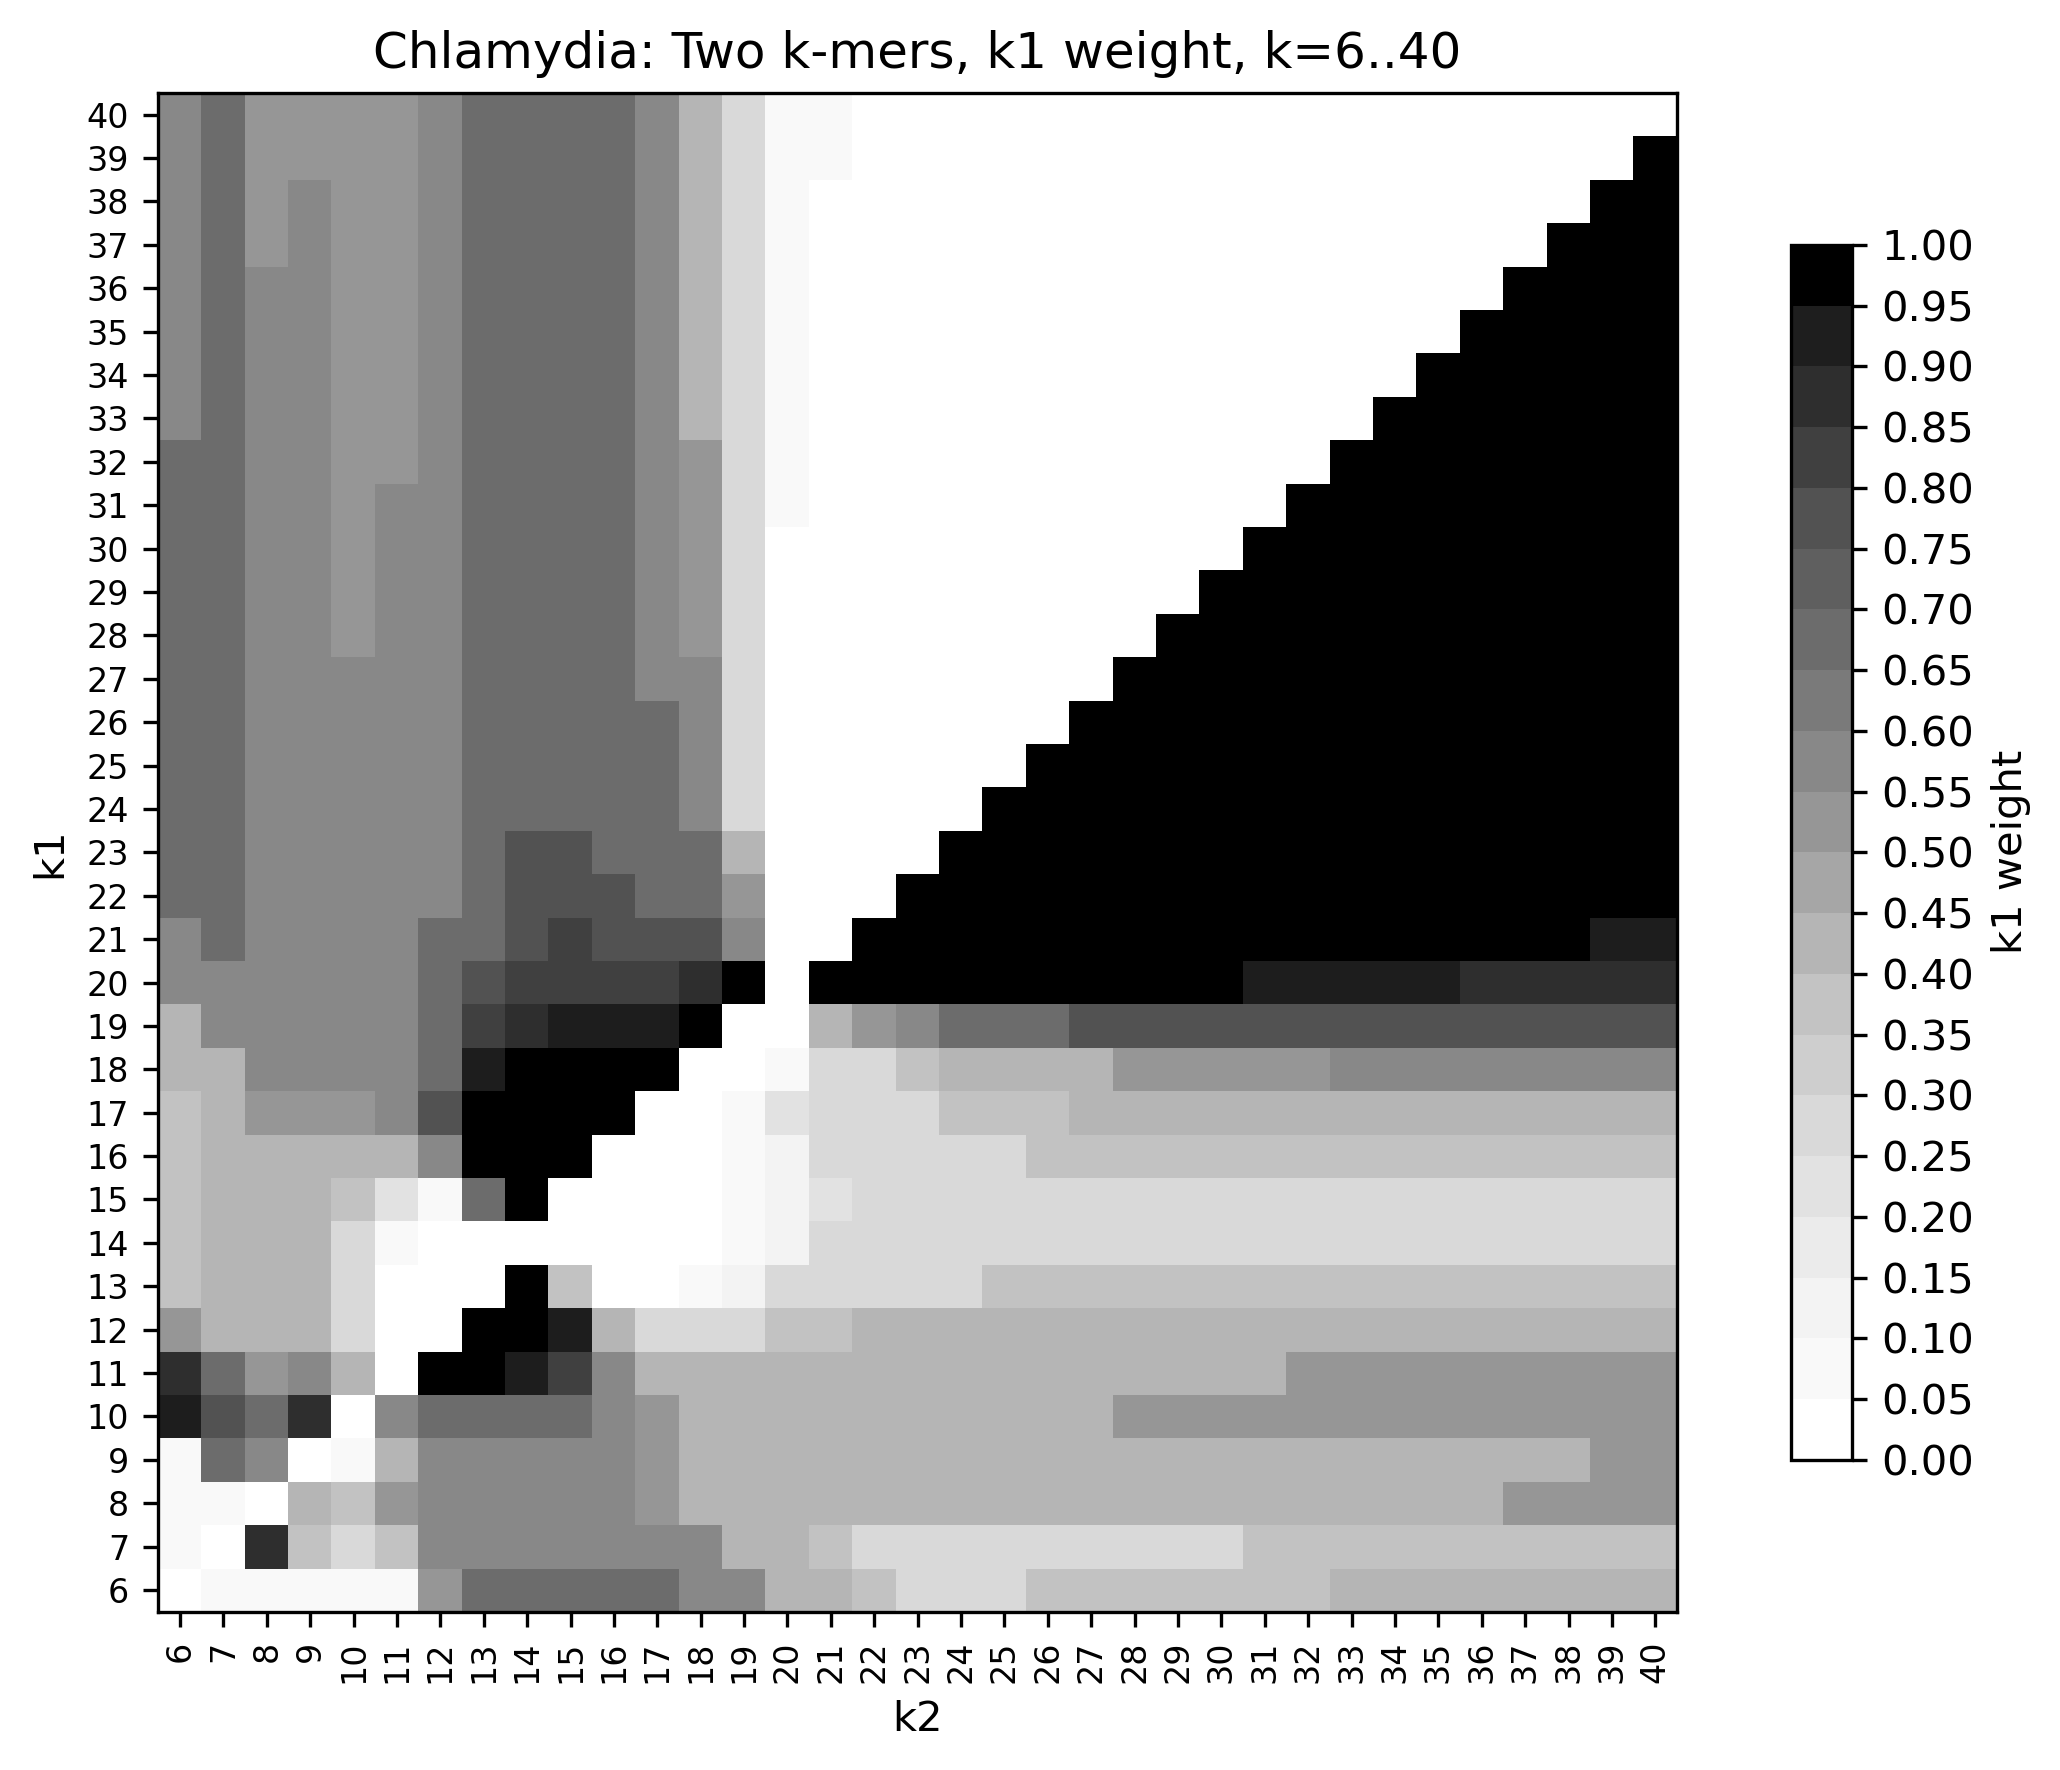


Cyano
(array([ 4, 14]), array([14,  4])) 0.8159030261740672


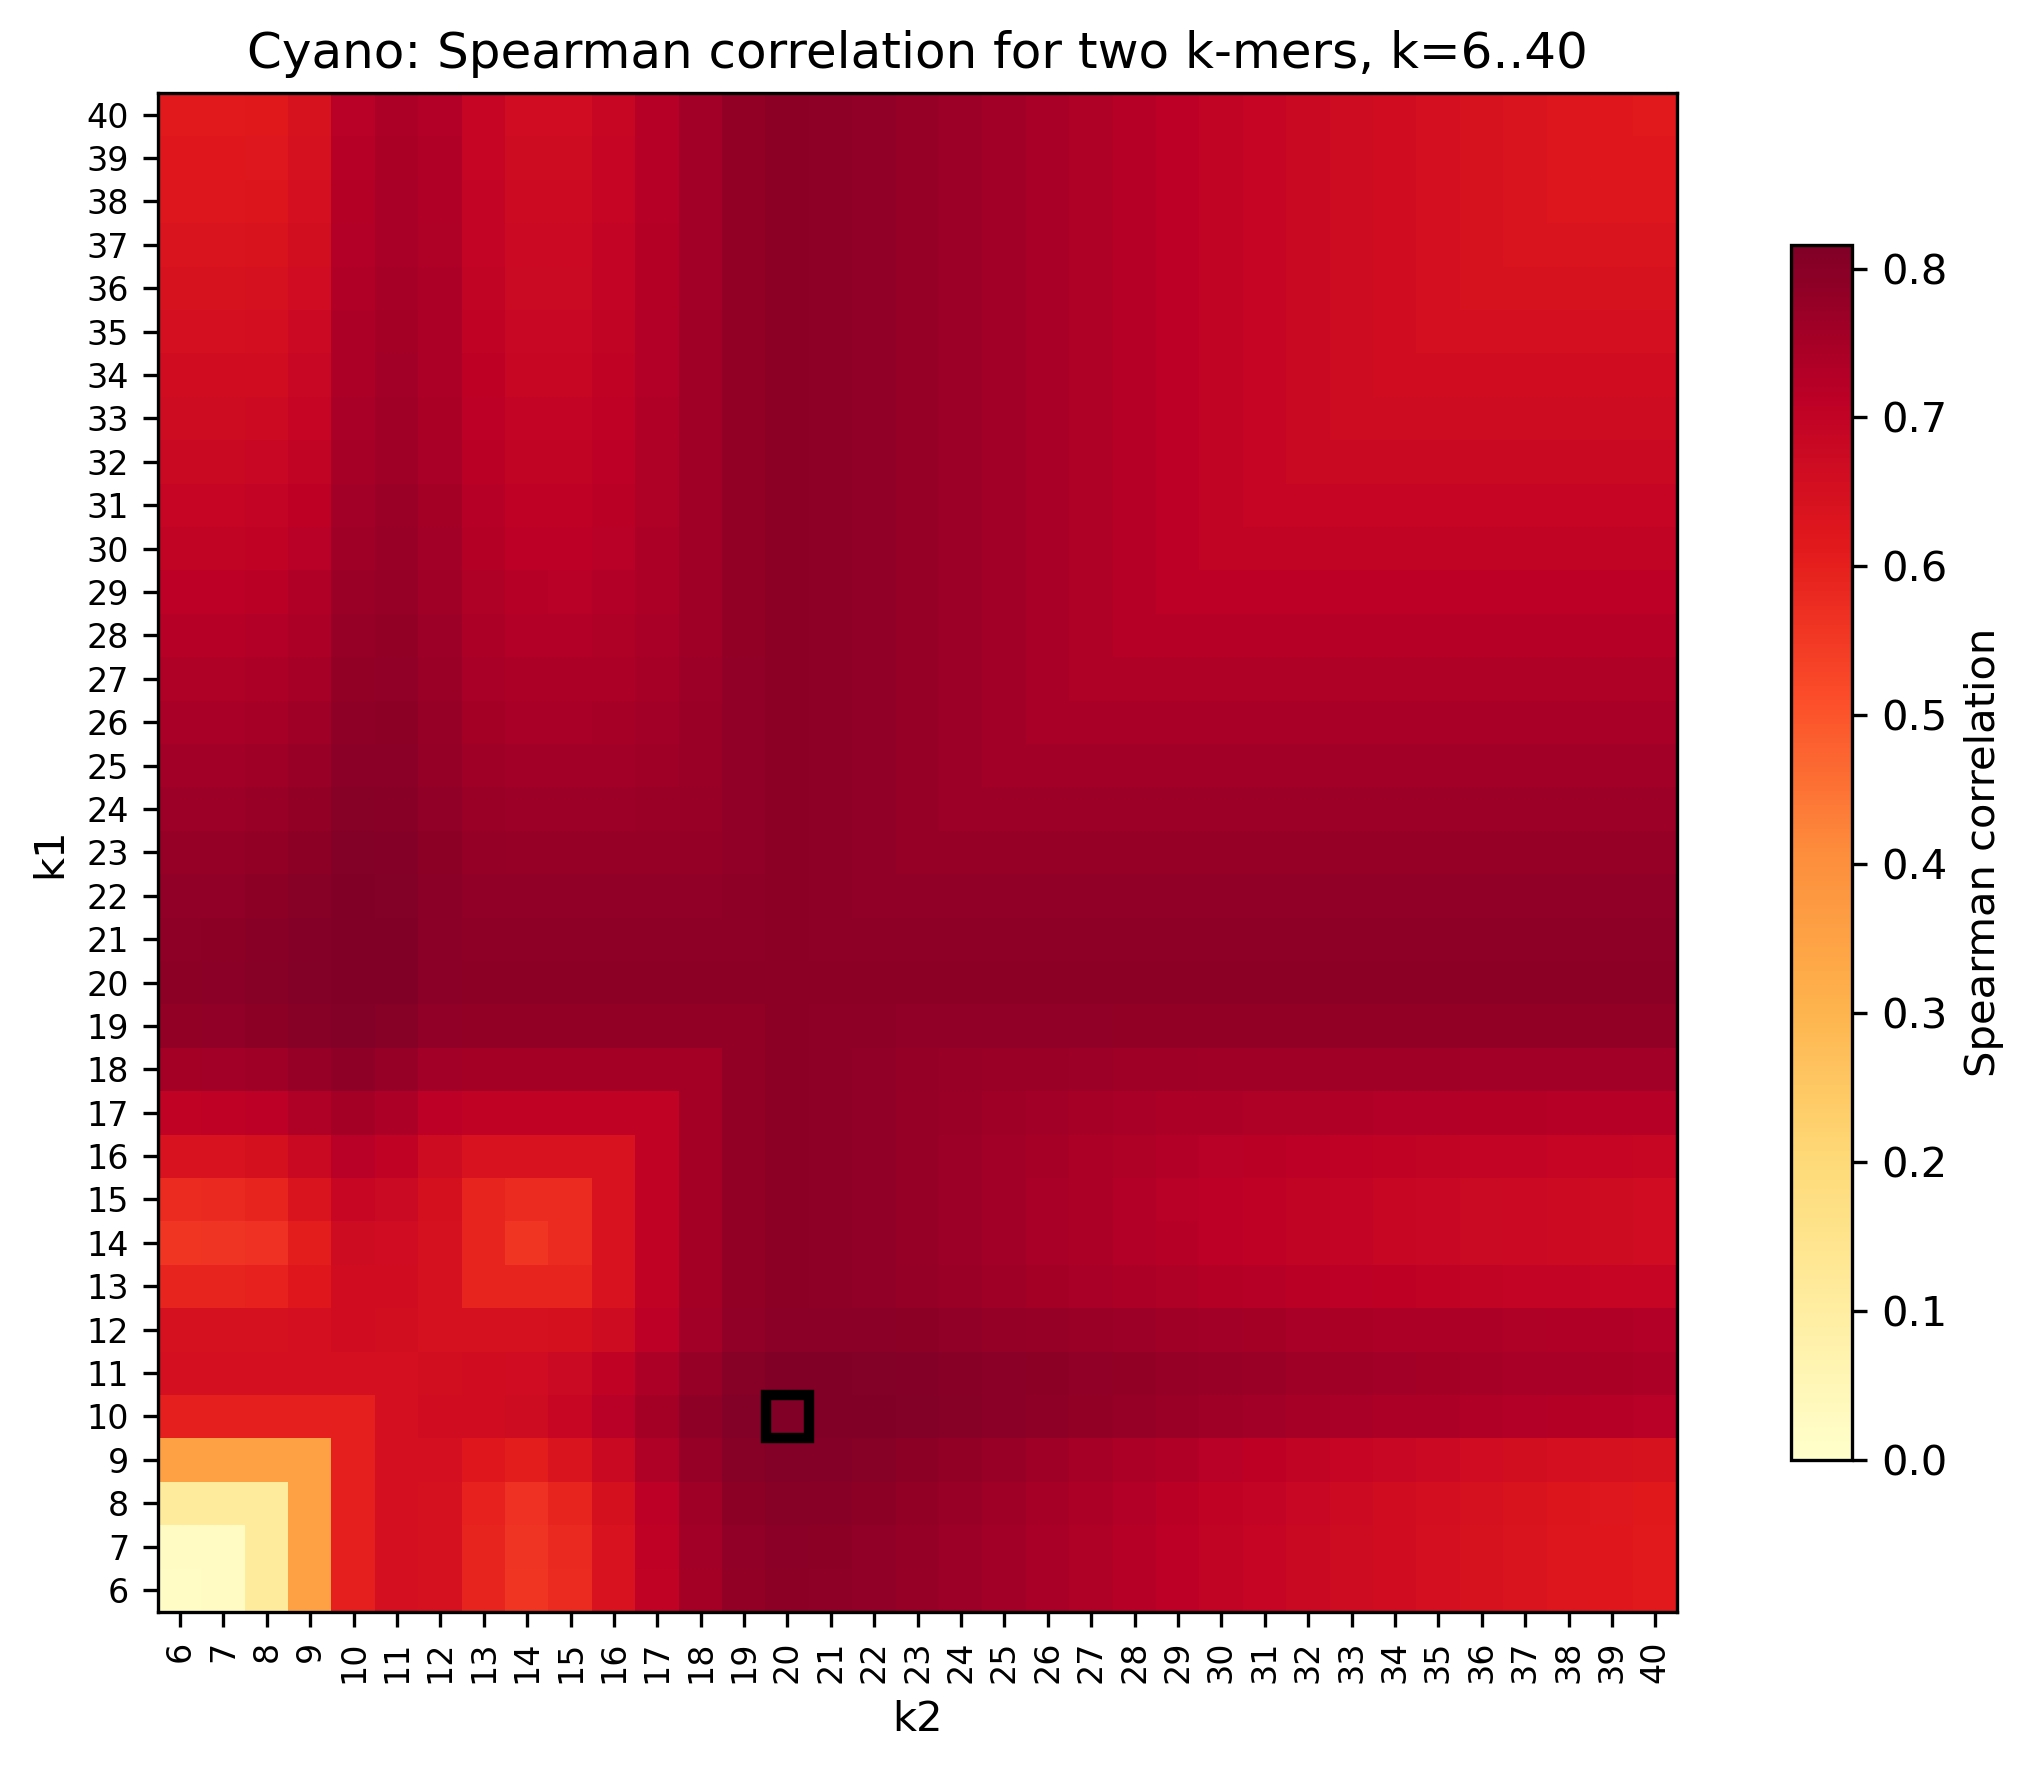

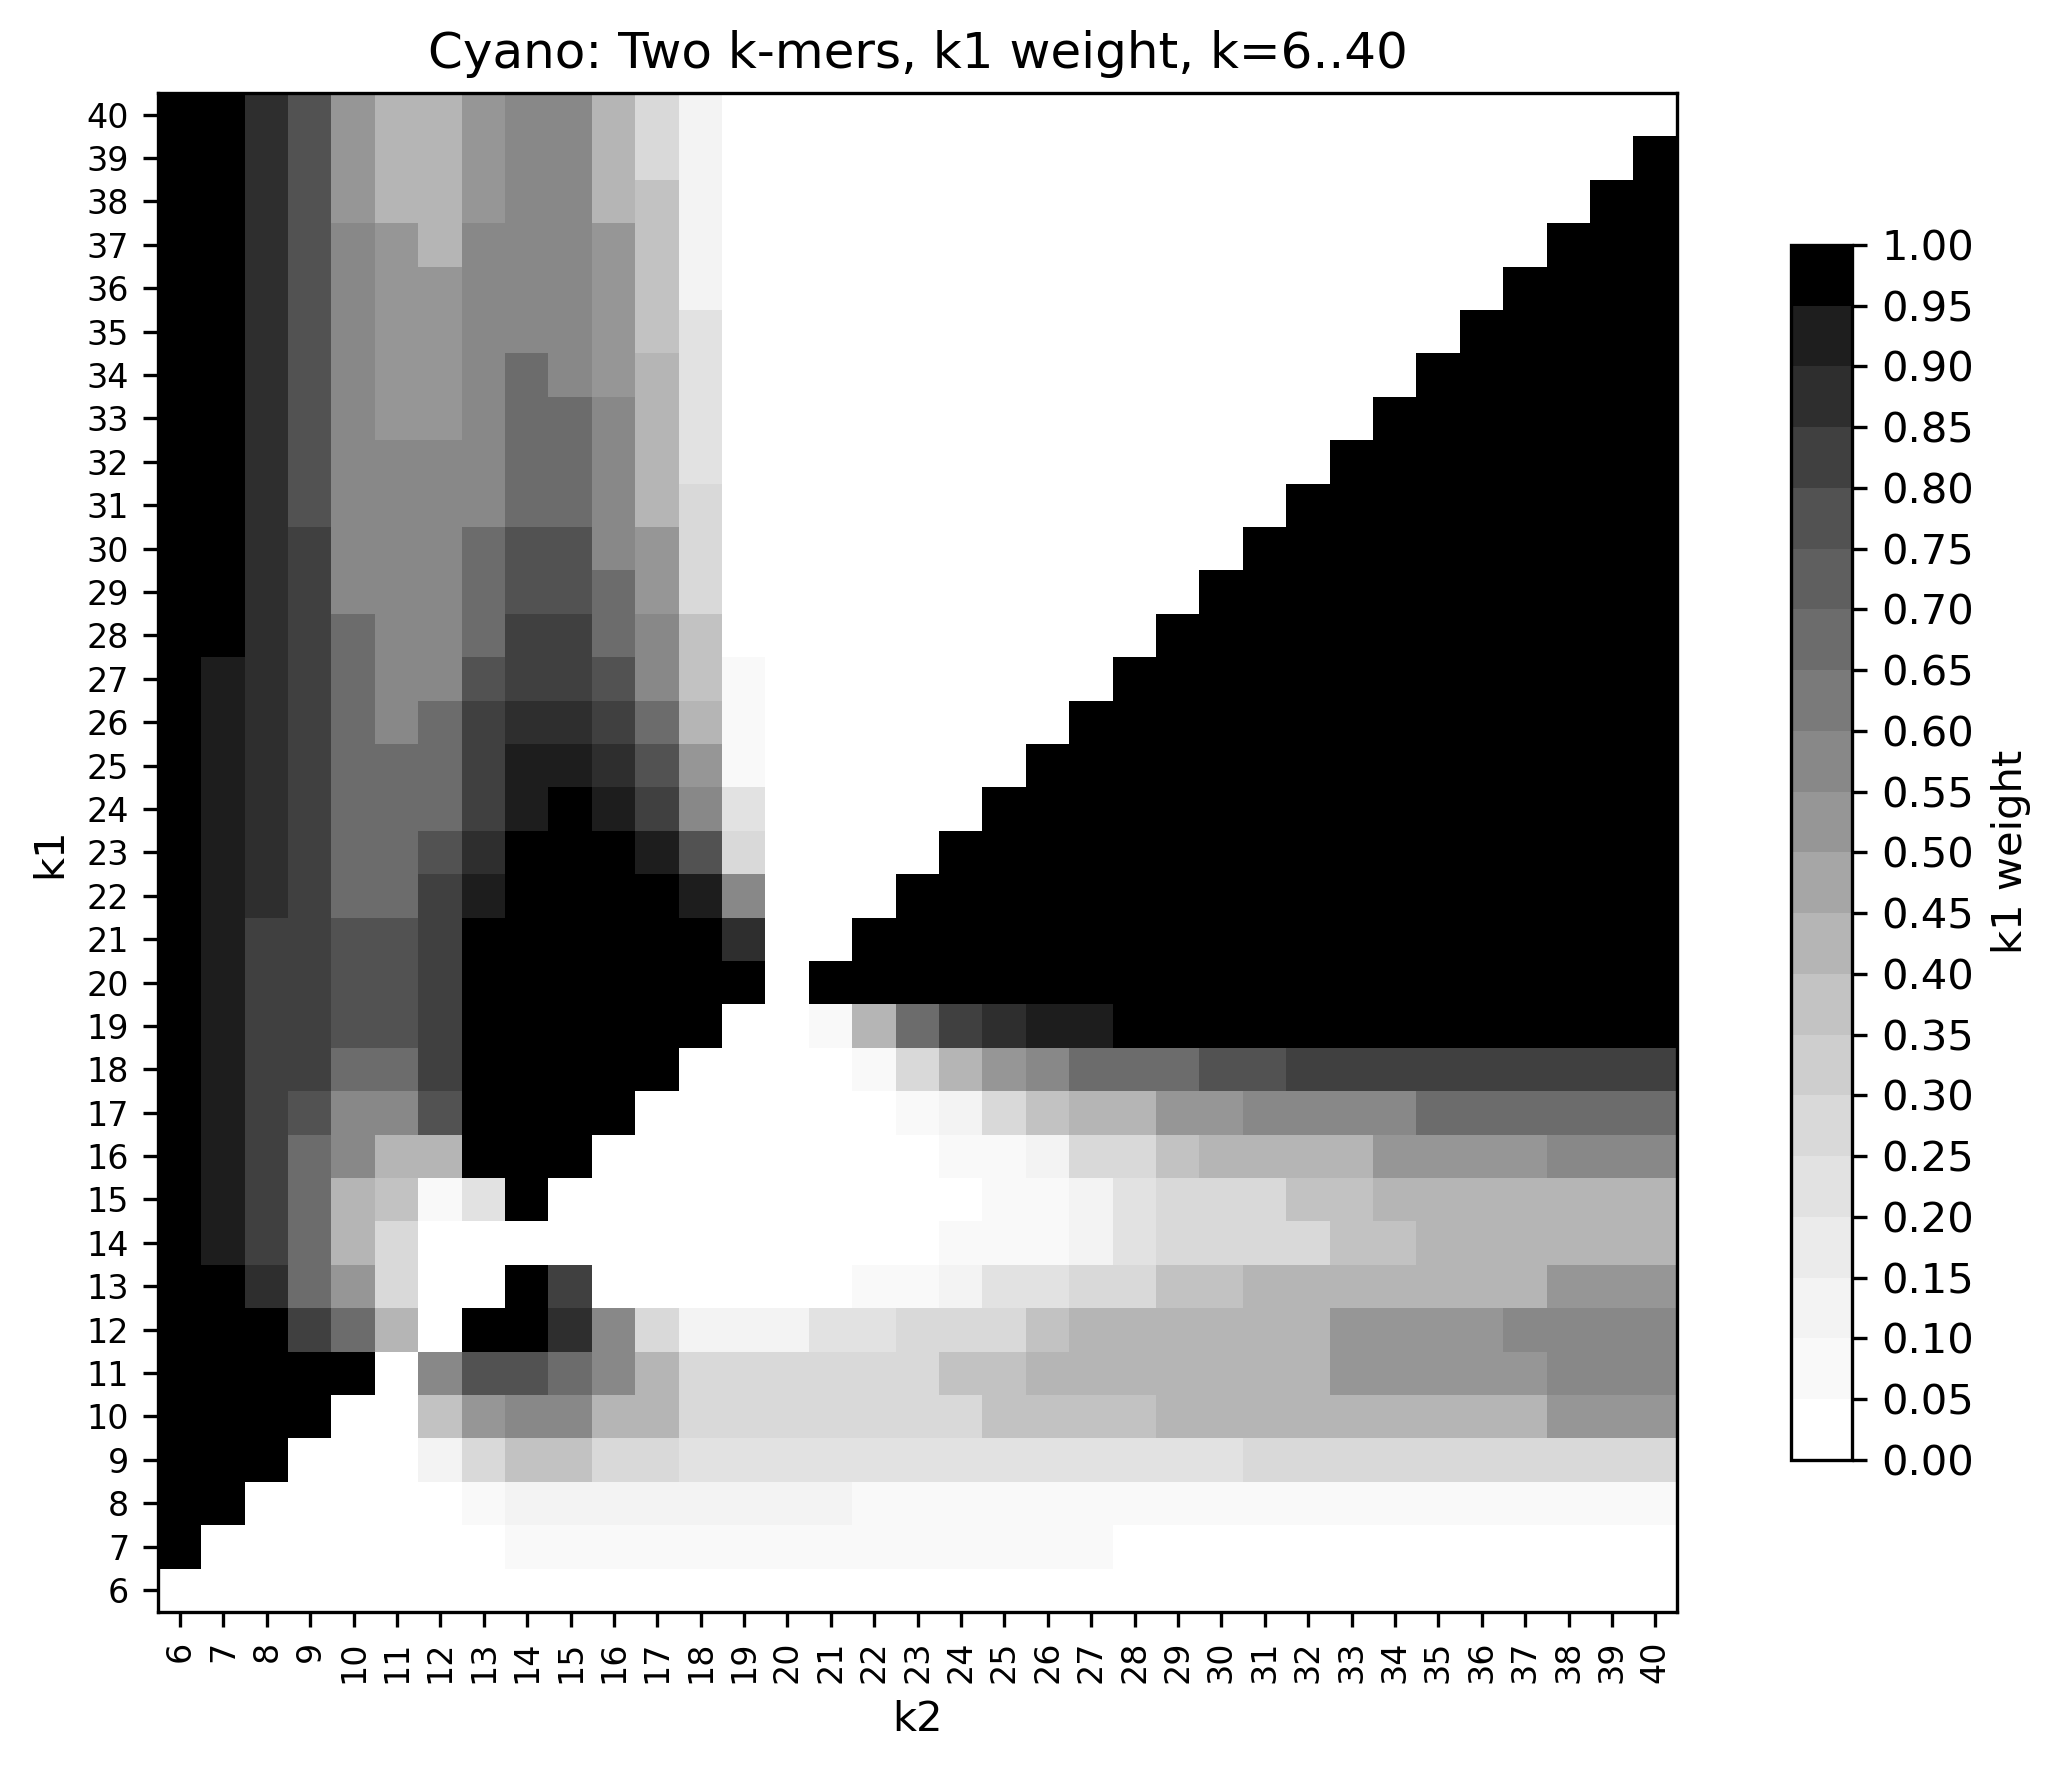


Neisseriaceae
(array([4]), array([13])) 0.9102818641263019


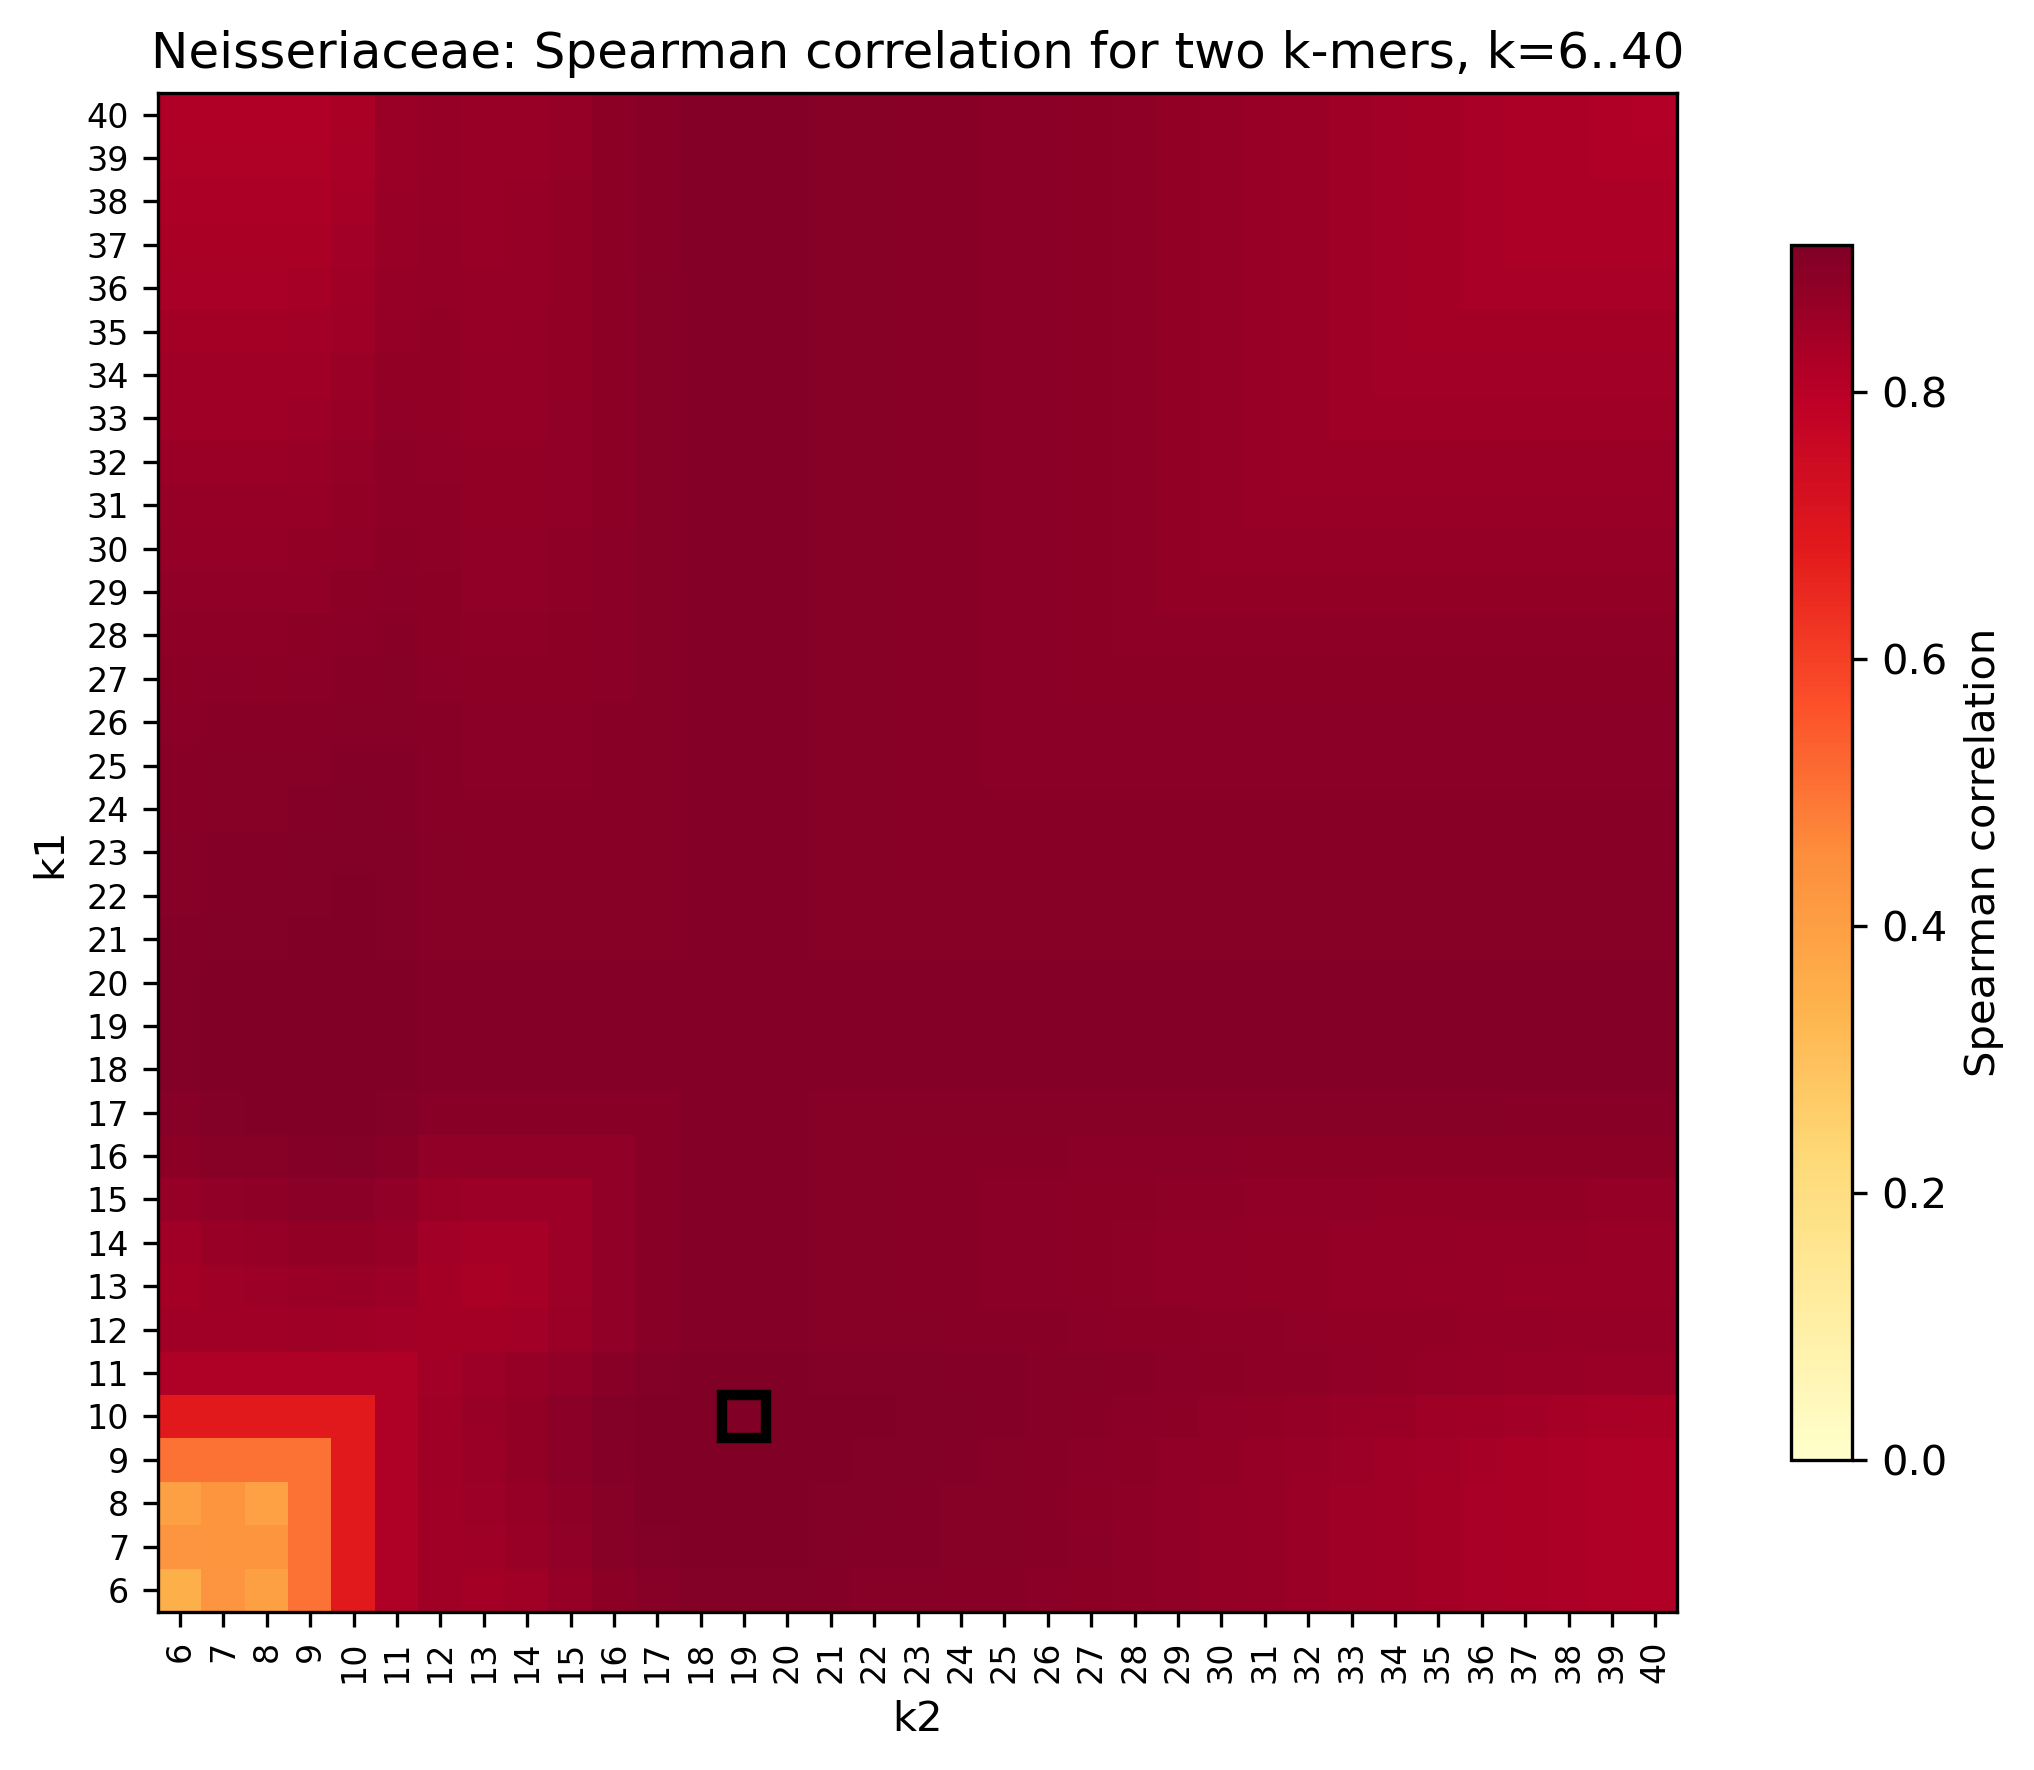

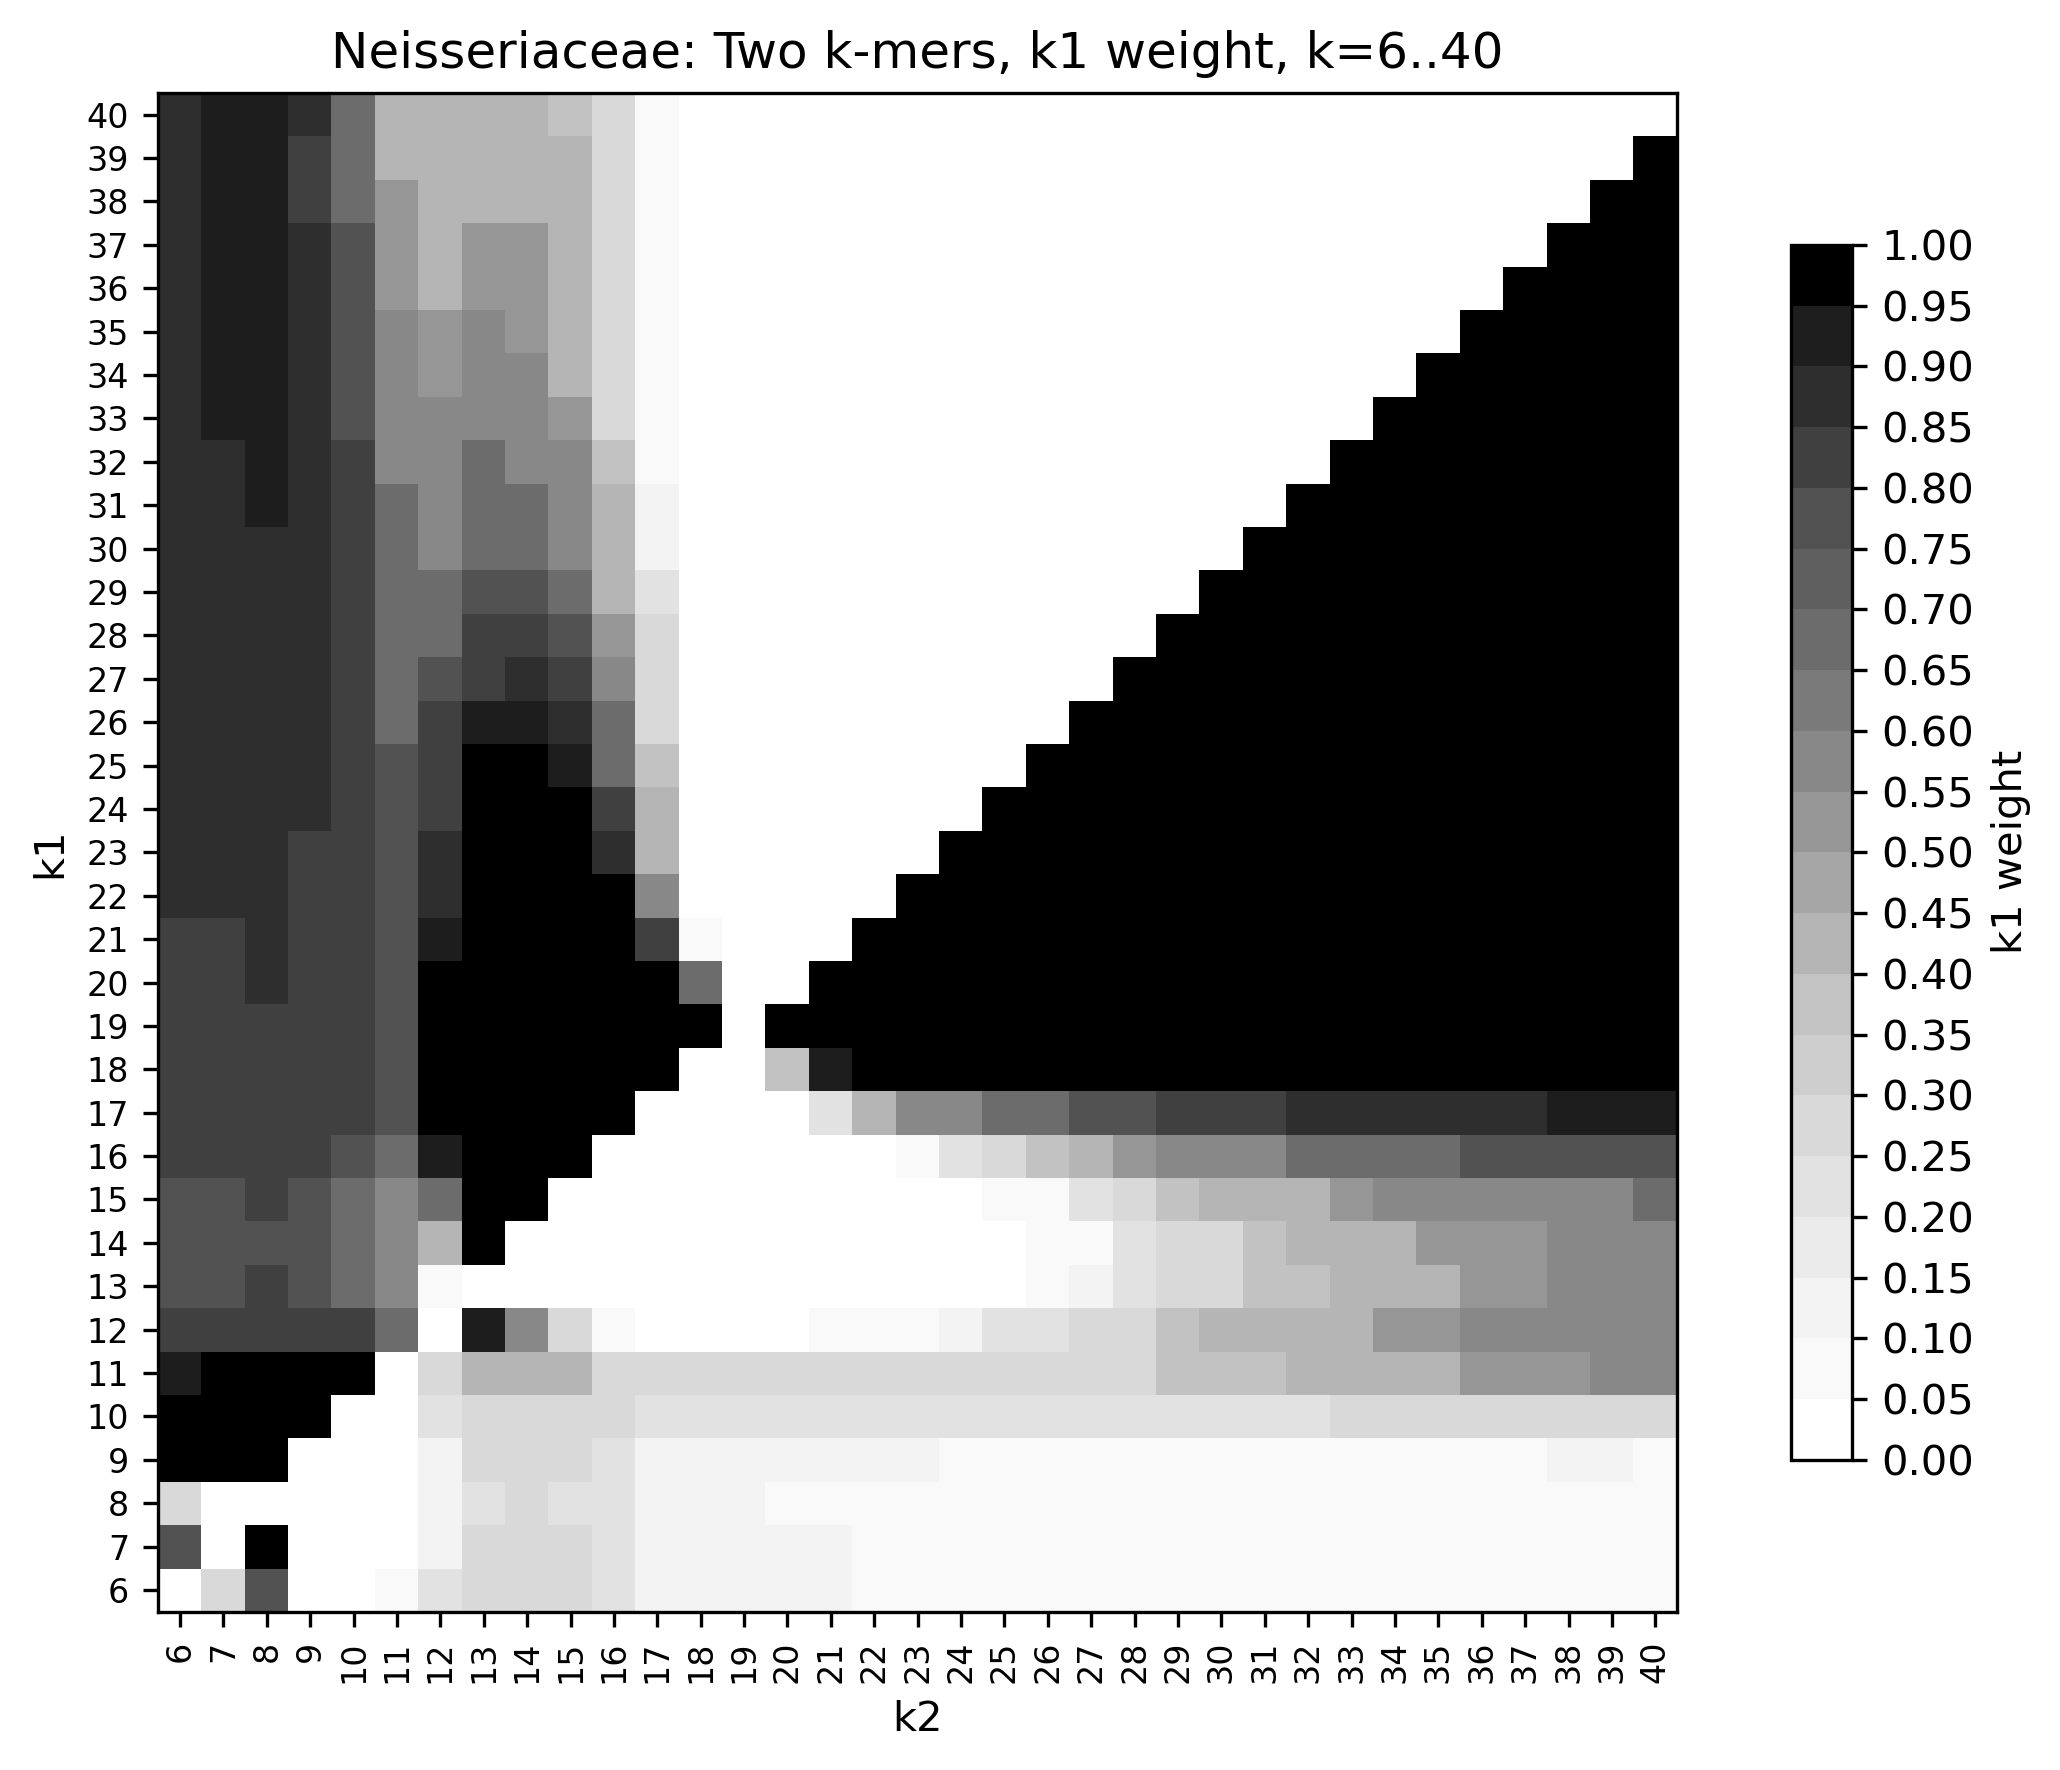

In [10]:
# Run full grid search
for name, results_matrix in datasets_2k:
    print(name)
    results_matrix = np.abs(results_matrix)
    # results_matrix, min_val, k1_min, k2_min, w_min, min_val = ok_k_mer.run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)   # run grid search, now is a slurm script
    ok_k_mer.plot_2d_heatmap_from_results_matrix(name, results_matrix, k_low=6, k_high=40)
    ok_k_mer.plot_2d_heatmap_weights_from_results_matrix(name, results_matrix, k_low=6, k_high=40, w_low=0, w_high=1, w_step=0.05)
    print()


### Three k-mers

In [12]:
# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_3k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_3k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_3k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_3k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_3k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_3k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = -1 * aquificota_grid
bacillales_grid    = -1 * bacillales_grid
caldisericia_grid  = -1 * caldisericia_grid
chlamydia_grid     = -1 * chlamydia_grid
cyano_grid         = -1 * cyano_grid
neisseriaceae_grid = -1 * neisseriaceae_grid

datasets_with_k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]


Aquificota 20


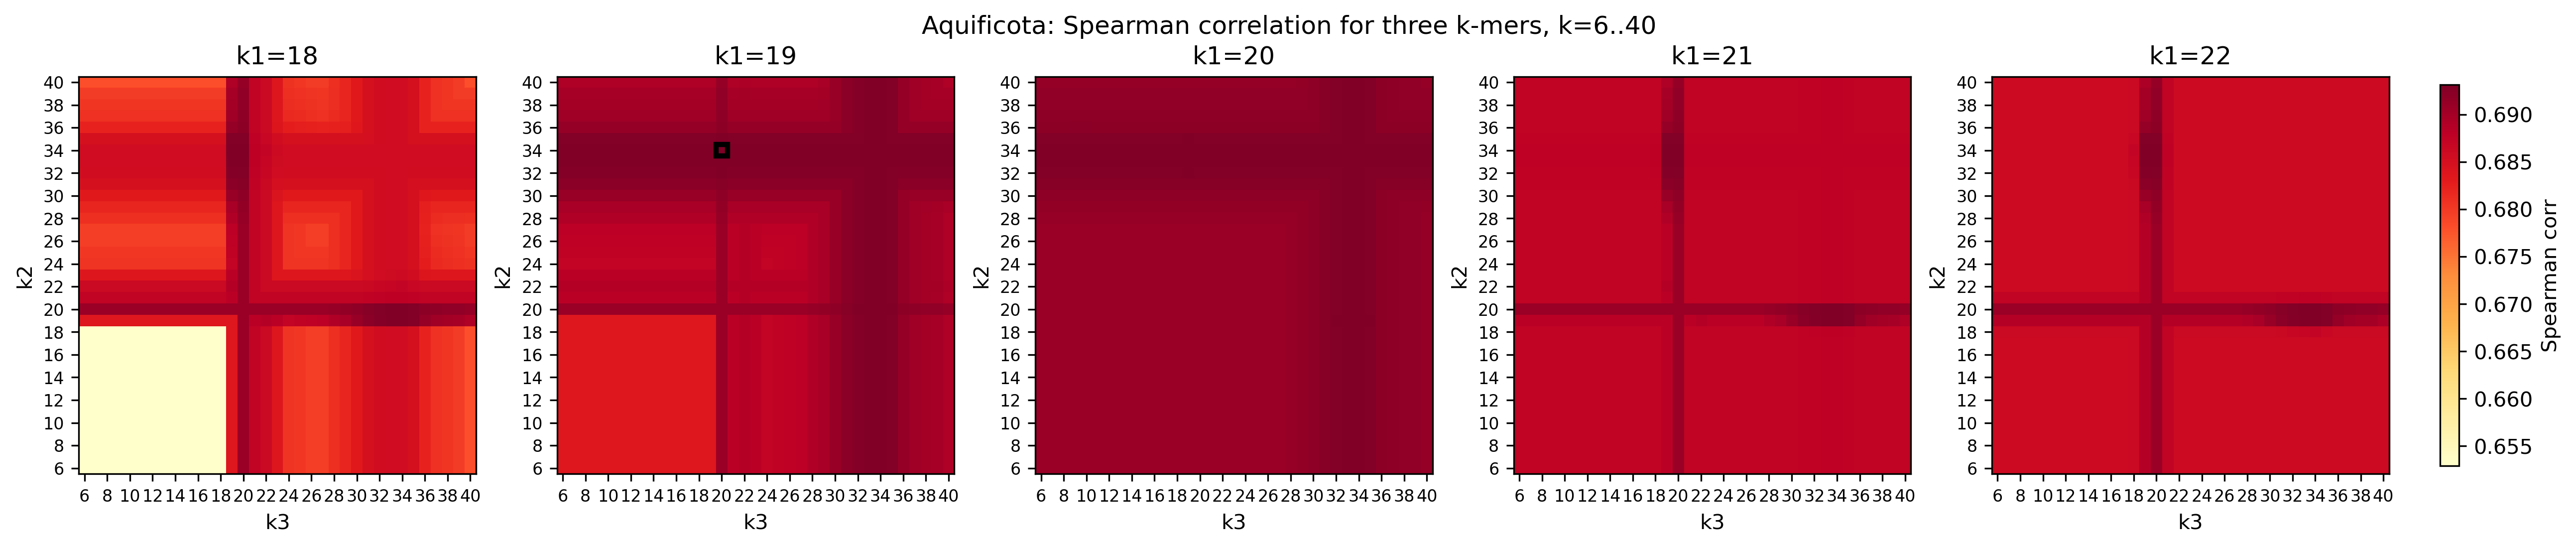


Bacillales 24


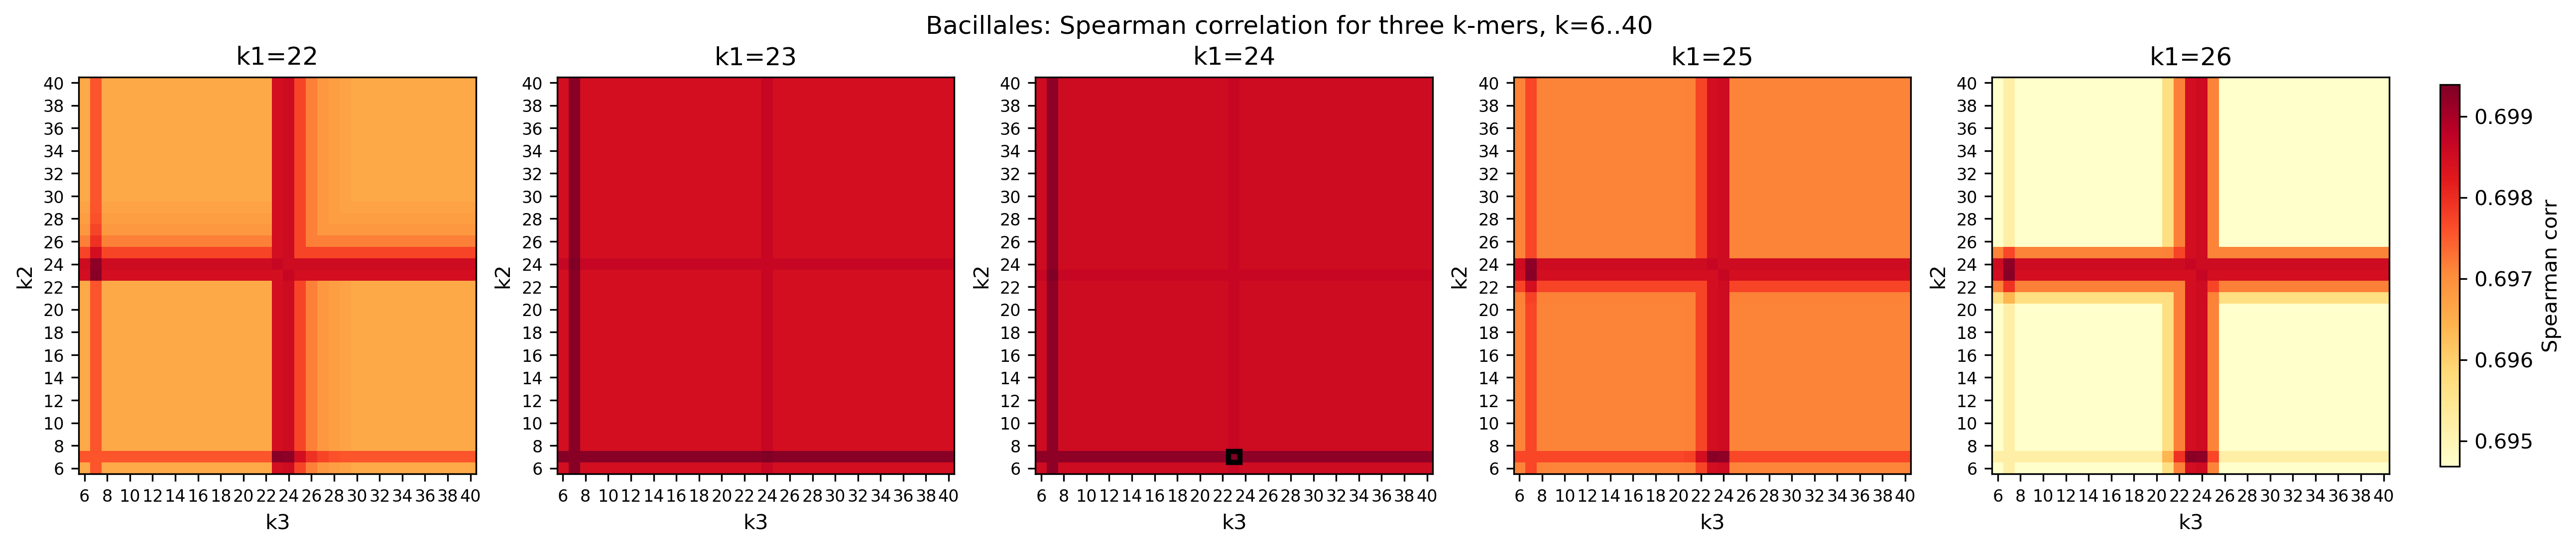


Caldisericia 20


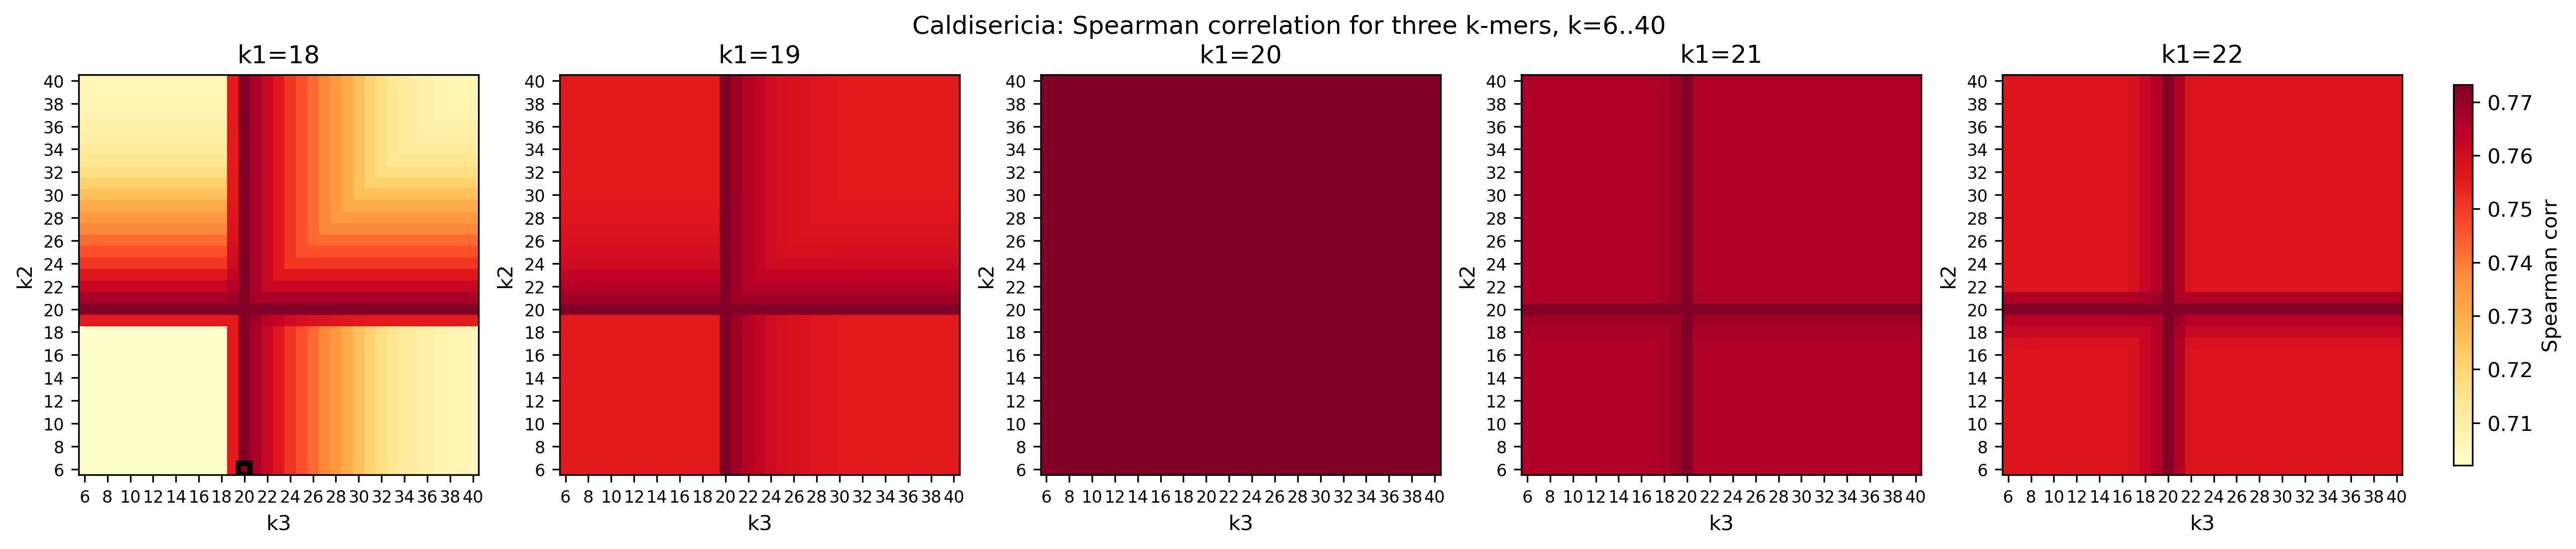


Chlamydia 20


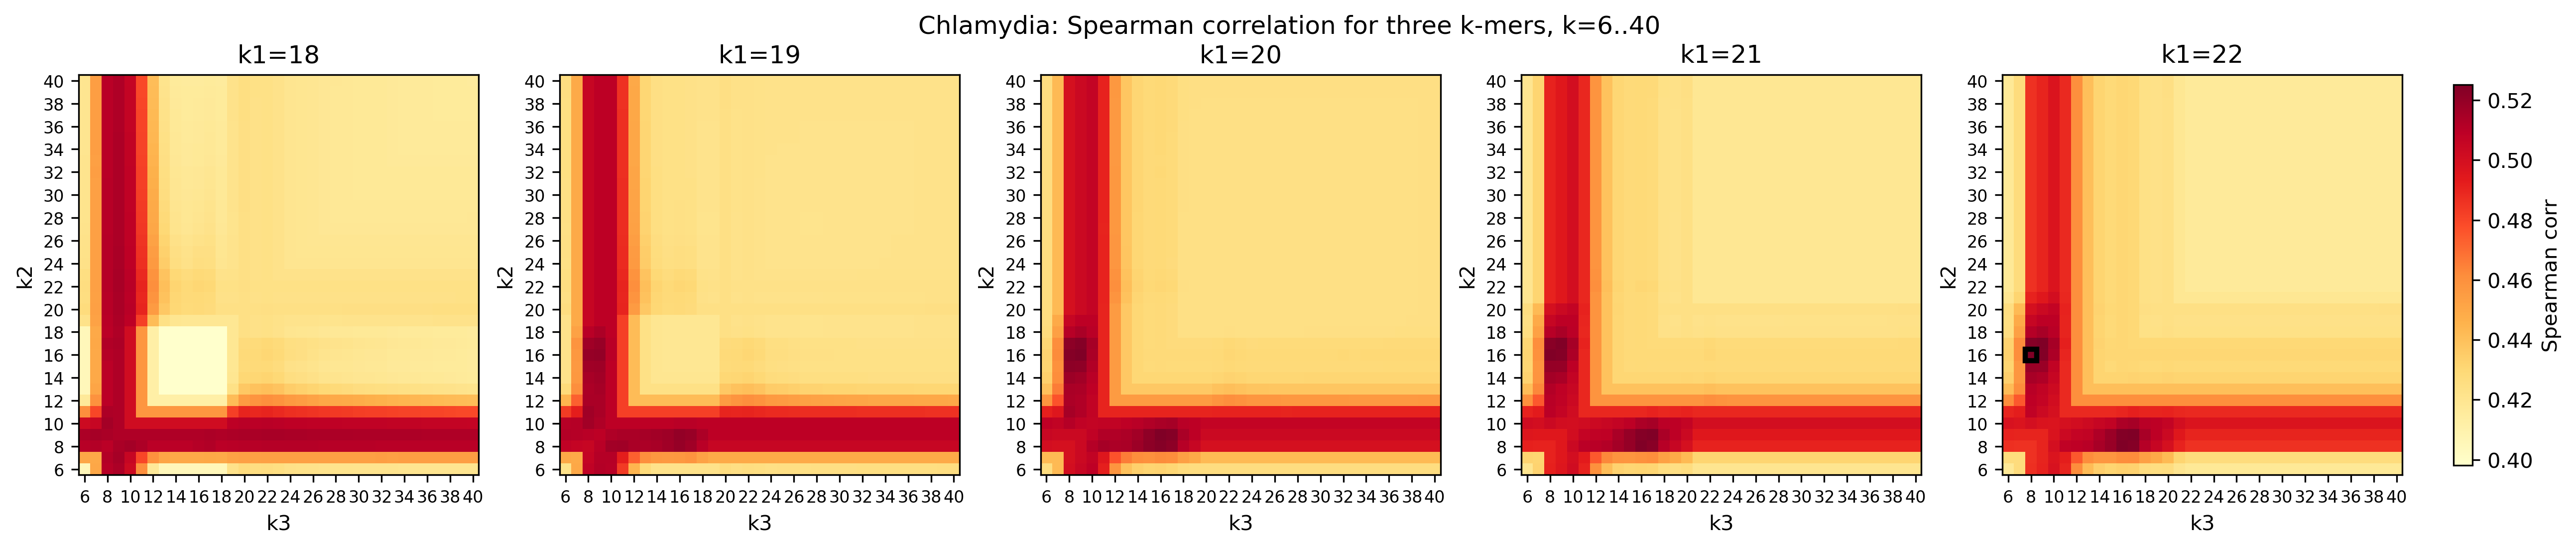


Cyano 20


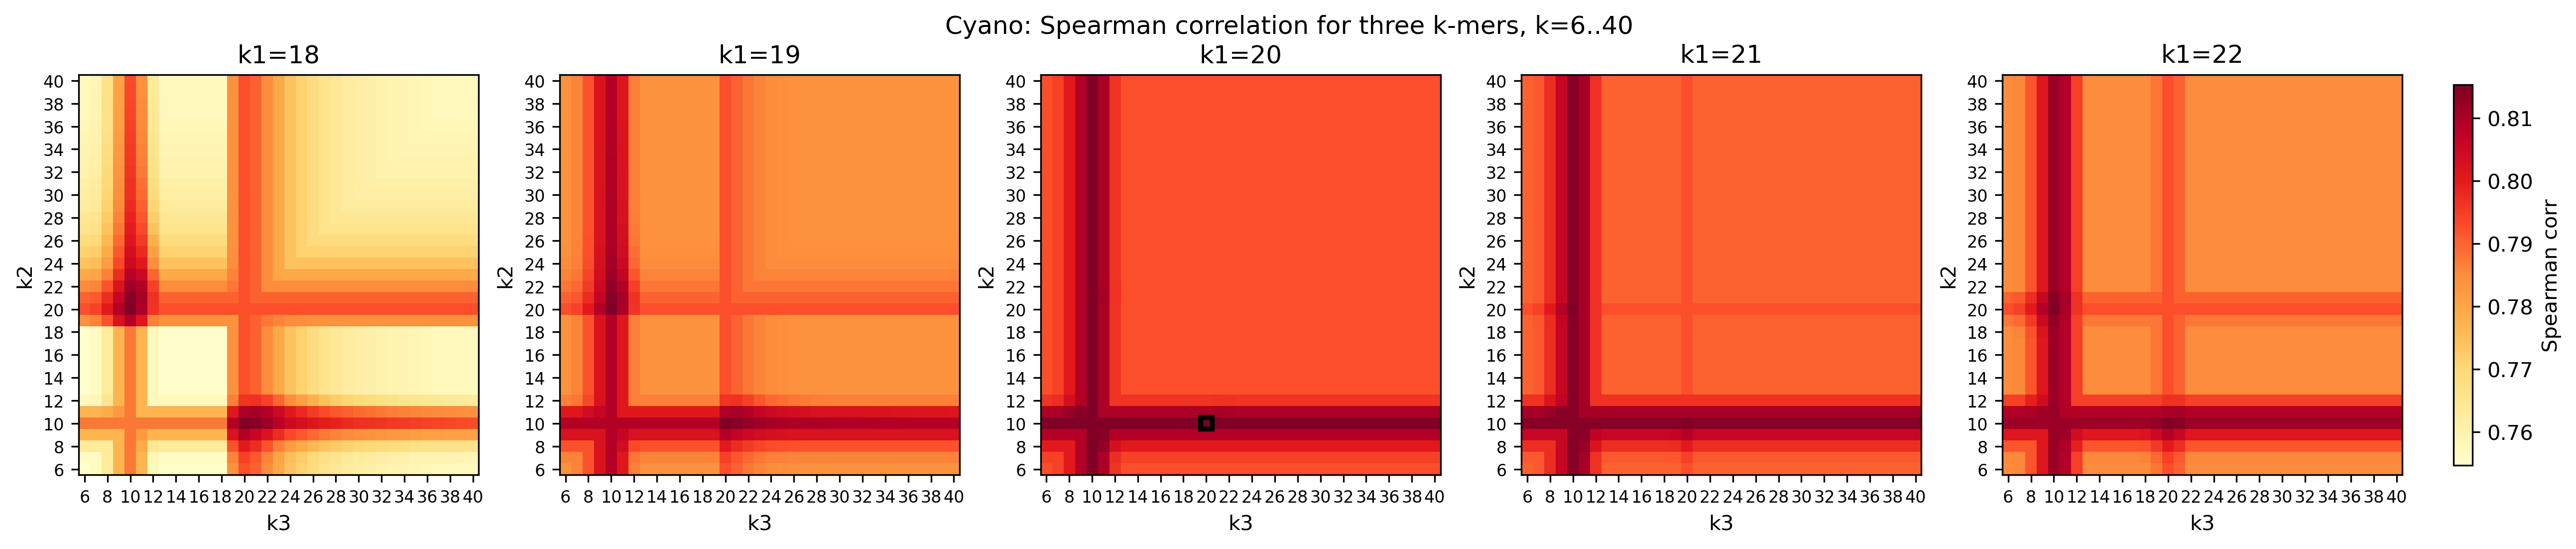


Neisseriaceae 19


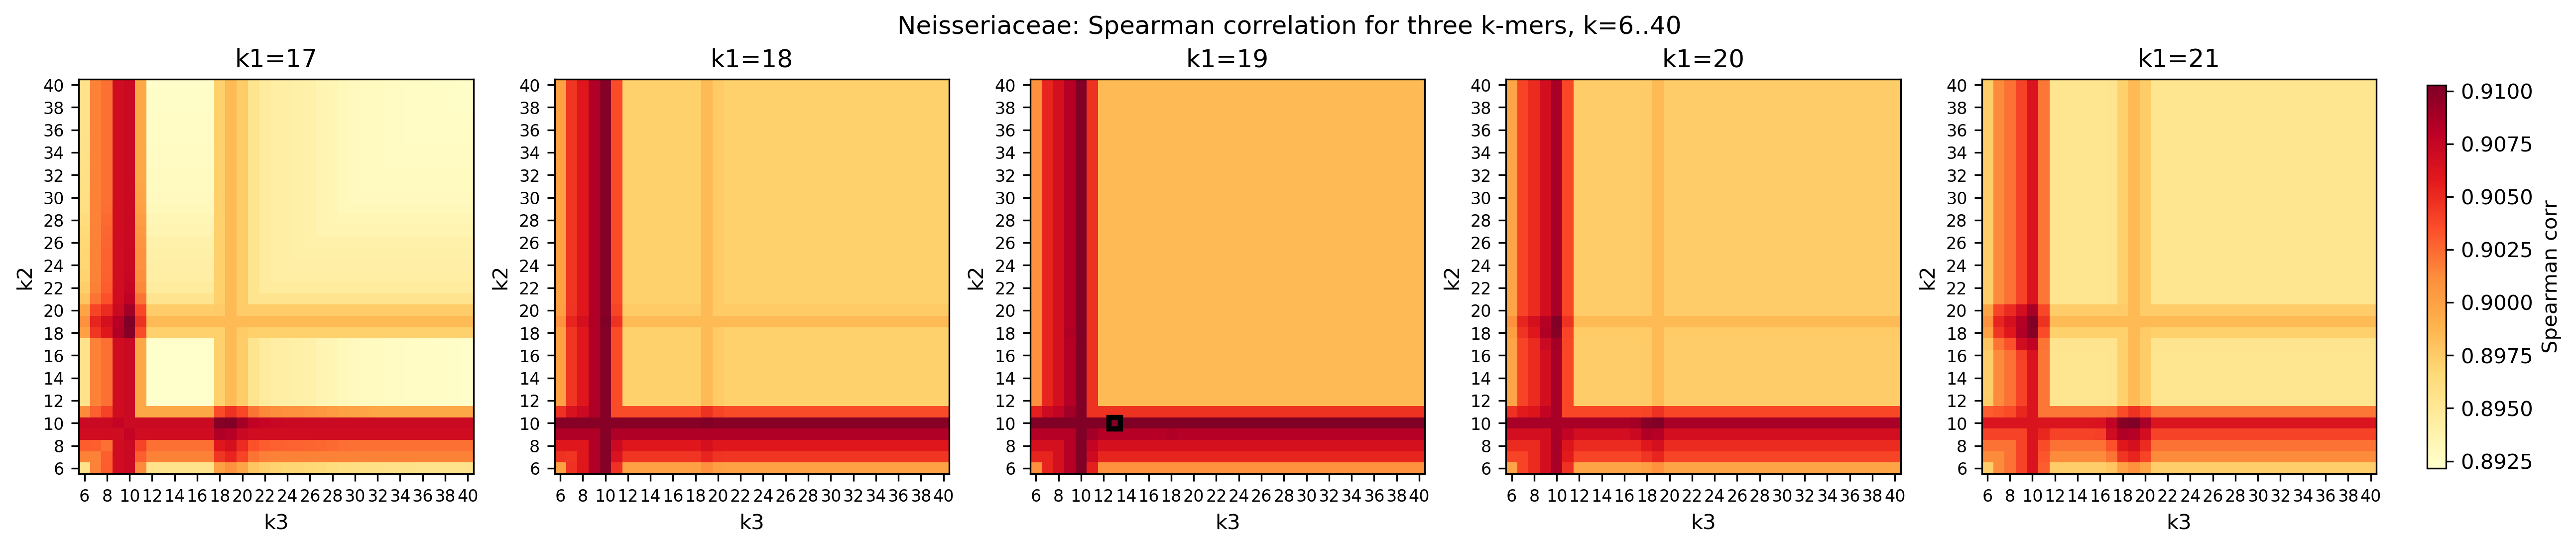

In [13]:
# Run across all datasets

s = 2 # s = 3
k_low = 6
k_high = 40

# Run 3-kmer grid search
for name, grid_df, k_best in datasets_with_k:
    print(name, k_best)
    results = ok_k_mer.plot_3k_grid_corr_k(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high)
    print()


## Plotting k-mer dist botxplot across k-mer lengths
For each genome-pair, plot dist from Dragen across k-kmers 5 -> 64.

In [ ]:
def plot_kmer_dashing_distances(merged_df, k_min=5, k_max=64):
    """
    Plot k-mer distances boxplots for columns k{k}_distance in merged_df.

    Parameters
    ----------
    merged_df : pandas.DataFrame
        DataFrame containing columns like 'k5_distance', ..., 'k64_distance'.
    k_min : int, optional
        Minimum k to start from (default is 5).
    k_max : int, optional
        Maximum k to end at (default is 64).
    """
    data = []
    labels = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_distance"
        if col in merged_df.columns:
            data.append(merged_df[col].dropna())
            labels.append(f"k{k}")

    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.xticks(rotation=90)
    plt.ylabel("k-mer distance")
    plt.title(f"k-mer distances (k = {k_min}..{k_max})")
    plt.tight_layout()
    plt.show()


In [ ]:
for name, df in datasets:
    print(f"Plotting k-mer distances for {name}")
    plot_kmer_dashing_distances(df, k_min=5, k_max=32)


In [ ]:
def calc_k_medians(merged_df, k_min=5, k_max=64):
    """
    For each k in range k_min to k_max, calculate the median k-mer distance
    and return a dictionary with k as key and median as value.
    """
    k_medians = {}
    for k in range(k_min, k_max + 1):
        col = f"k{k}_distance"
        if col in merged_df.columns:
            median_val = merged_df[col].dropna().median()
            k_medians[k] = median_val
    return k_medians


In [ ]:
k_medians_records = []
for name, df in datasets:
    print(f"Plotting k-mer distances for {name}")
    medians = calc_k_medians(df, k_min=5, k_max=32)
    for k, median_val in medians.items():
        k_medians_records.append({"dataset": name, "k": k, "median": median_val})

k_medians_df = pd.DataFrame(k_medians_records)

################################################################################
# plot medians

colors = [ "#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02" ]

fig, ax = plt.subplots(figsize=(10, 6))

for i, (dataset_name, df_subset) in enumerate(k_medians_df.groupby('dataset')):
    color = colors[i % len(colors)]
    ax.plot(df_subset['k'], df_subset['median'], marker='o', label=dataset_name, color=color)

ax.set_xlabel('k')
ax.set_ylabel('Median k-mer Distance')
ax.set_title('Median k-mer Distance by k (stratified by dataset)')
ax.legend(title='Dataset')
plt.tight_layout()
plt.show()


## Plot k-mer cardinality
f(G1, G2, k) = G1(k) U G2(k) / 4**k


In [ ]:
def parse_union_cardinality_dashing_dfs(dir_path):
    """
    Parses all distance_* files in the given directory into a dictionary of pandas DataFrames.
    Each DataFrame skips the first line, assumes tab-separation and adjusts indices and columns as expected.

    Args:
        dir_path (str): Path to the directory containing distance_* files.

    Returns:
        dict: Dictionary mapping filename to corresponding DataFrame.
    """

    # Get list of files in directory that start with 'distance_'
    files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f)) and f.startswith('union_')]

    # Create a dictionary to store dataframes
    dashing_dfs = {}

    # Read each file into a dataframe, skipping first line
    for file in files:
        file_path = os.path.join(dir_path, file)
        try:
            # Skip first line and read tab-separated data
            df = pd.read_csv(file_path, sep='\t', header=None, skiprows=3)
            df.index = df.iloc[:, 0].str.replace('genomes_ncbi/', '')
            df = df.iloc[:, 1:]
            df.columns = df.index
            dashing_dfs[file] = df
            # print(f"Successfully read {file}")
        except Exception as e:
            print(f"Error reading {file}: {str(e)}")

    # Print summary of loaded dataframes
    print(f"\nLoaded {len(dashing_dfs)} files")
    for file, df in dashing_dfs.items():
        print(f"{file}: {df.shape}")
    return dashing_dfs



In [ ]:

def build_merged_card_df(tree_dict, dashing_card_dfs):
    """
    Build merged dataframe for all genome pairs among `genomes`,
    including tree distances and distances for each k from `dashing_card_dfs`.

    Parameters:
    -----------
    tree_dict : dict
        Nested dictionary of tree-based distances; tree_dict[g1][g2] gives distance.
    dashing_card_dfs : dict
        Mapping from dashing file name to pairwise distance DataFrame.

    Returns:
    --------
    merged_card_df : pd.DataFrame
        DataFrame indexed by sorted genome pairs, with metadata and k-mer distances.
    """

    genomes = sorted(tree_dict.keys())

    # Create all pairs of genomes (upper triangle only, sorted lexicographically)
    pairs = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            pair = '_'.join(sorted([genomes[i], genomes[j]]))
            pairs.append(pair)

    # Initialize dataframe with pairs as index
    merged_card_df = pd.DataFrame(index=pairs)

    # Add metadata columns to merged_card_df
    genome_pairs = []
    genomes_1s = []
    genomes_2s = []
    tree_distances = []
    for index in merged_card_df.index:
        # Split the genome pair
        genome1 = "_".join(index.split("_", 2)[:2])
        genome2 = "_".join(index.split("_", 2)[2:])

        # Get distance from tree_dict
        genome_pairs.append(index)
        genomes_1s.append(genome1)
        genomes_2s.append(genome2)
        tree_distances.append(tree_dict[genome1][genome2])

    merged_card_df['genome_pair'] = genome_pairs
    merged_card_df['genome_1'] = genomes_1s
    merged_card_df['genome_2'] = genomes_2s
    merged_card_df['tree_distance'] = tree_distances

    print(f"Final dataframe shape: {merged_card_df.shape}")

    # For each k, add a column to merged_card_df with the pairwise distances
    for fname, df in dashing_card_dfs.items():
        k_val = int(str(fname).replace('union_k', '').replace('.txt', ''))
        # Build a dictionary mapping sorted genome pair -> distance
        pair_to_dist = {}
        for i in range(len(df)):
            g1 = df.iloc[i].name
            for g2, d in dict(df.iloc[i]).items():
                if g1 == g2: continue
                pair = '_'.join(sorted([g1, g2]))
                pair_to_dist[pair] = d

        # Map the distances to the merged_card_df for this k
        colname = f'k{k_val}_cardinality'
        merged_card_df[colname] = merged_card_df.index.map(pair_to_dist.get)

        print(f"Added column '{colname}' to merged_card_df.")
        if k_val % 2 == 0: # k-mer is even
            num_pal = 4**(k_val/2)
            num_distinct_kmers = (4**k_val - num_pal) / 2 + num_pal
        else:
            num_distinct_kmers = 4**k_val / 2

        merged_card_df[colname] = merged_card_df[colname] / num_distinct_kmers

    return merged_card_df

def process_card_data(tree_path, dashing_dir_path):
    tree_dict = make_tree_dict(tree_path)
    dashing_card_dfs = parse_union_cardinality_dashing_dfs(dashing_dir_path)
    merged_card_df = build_merged_card_df(tree_dict, dashing_card_dfs)
    return tree_dict, dashing_card_dfs, merged_card_df

In [ ]:

aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/union_cardinality'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/union_cardinality'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/union_cardinality'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/union_cardinality'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/union_cardinality'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/union_cardinality'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = process_card_data(aquificota_tree_path, aquificota_dir_path)
bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = process_card_data(bacillales_tree_path, bacillales_dir_path)
caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = process_card_data(caldisericia_tree_path, caldisericia_dir_path)
chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_card_data(chlamydia_tree_path, chlamydia_dir_path)
cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = process_card_data(cyano_tree_path, cyano_dir_path)
neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = process_card_data(neisseriaceae_tree_path, neisseriaceae_dir_path)

# Prepare a list of all available merged_dfs and their names
datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

In [ ]:

def plot_kmer_dashing_card(merged_card_df, name, k_min=5, k_max=64, log=False):
    """
    Plot k-mer cardinality boxplots or their -log10 transforms for columns k{k}_cardinality in merged_card_df.

    Parameters
    ----------
    merged_card_df : pandas.DataFrame
        DataFrame containing columns like 'k5_cardinality', ..., 'k64_cardinality'.
    name : str
        Title prefix for plot.
    k_min : int, optional
        Minimum k to start from (default is 5).
    k_max : int, optional
        Maximum k to end at (default is 64).
    log : bool, optional
        If True, plot -1 * log10(cardinality) instead of cardinality. Default is False.
    """

    data = []
    labels = []
    medians = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_cardinality"
        if col in merged_card_df.columns:
            col_values = merged_card_df[col].dropna()
            if log:
                # Compute -1 * np.log10 of the cardinality, avoiding log(0)
                values = -1 * np.log10(col_values)
            else:
                values = col_values
            data.append(values)
            labels.append(f"k{k}")
            if len(values) > 0:
                medians.append(np.median(values))
            else:
                medians.append(np.nan)

    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
    box = plt.boxplot(data, labels=labels, showfliers=False)
    plt.xticks(rotation=90)
    if log:
        plt.ylabel(r"-log$_{10}$(k-mer cardinality / number of k-mers)")
        plt.title(f"{name}: -log10 k-mer cardinality (k = {k_min}..{k_max})")
    else:
        plt.ylabel("k-mer cardinality / number of k-mers")
        plt.title(f"{name}: k-mer cardinality (k = {k_min}..{k_max})")
    plt.tight_layout()

    # Label each boxplot with the median
    for i, median in enumerate(medians, start=1):
        if not np.isnan(median):
            if log:
                plt.text(i, median, f"{median:.3f}", ha='center', va='bottom', color='midnightblue',
                        fontsize=8, fontweight='bold', rotation=90)
            else:
                plt.text(i, median, f"{median:.2e}", ha='center', va='bottom', color='midnightblue',
                        fontsize=8, fontweight='bold', rotation=90)

    plt.show()


In [ ]:
# plot k-mer cardinalities

k_min = 5
k_max = 40

for name, df in datasets:
    print(f"Plotting k-mer cardinality for {name}")
    plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max)
    plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max, log=True)
    print()

# def plot_kmer_dashing_card(merged_card_df, name, k_min=5, k_max=64, log=False):


In [ ]:

def plot_kmer_dashing_card(merged_card_df, name, k_min=5, k_max=64):
    """
    Plot k-mer cardinality boxplots for columns k{k}_distance in merged_card_df.

    Parameters
    ----------
    merged_card_df : pandas.DataFrame
        DataFrame containing columns like 'k5_distance', ..., 'k64_distance'.
    k_min : int, optional
        Minimum k to start from (default is 5).
    k_max : int, optional
        Maximum k to end at (default is 64).
    """
    data = []
    labels = []
    medians = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_cardinality"
        if col in merged_card_df.columns:
            col_values = merged_card_df[col].dropna()
            data.append(col_values)
            labels.append(f"k{k}")
            if len(col_values) > 0:
                medians.append(np.median(col_values))
            else:
                medians.append(np.nan)

    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
    box = plt.boxplot(data, labels=labels, showfliers=False)
    plt.xticks(rotation=90)
    plt.ylabel("k-mer cardinality / number of k-mers")
    plt.title(f"{name}: k-mer cardinality (k = {k_min}..{k_max})")
    plt.tight_layout()

    # Label each boxplot with the median
    for i, median in enumerate(medians, start=1):
        if not np.isnan(median):
            plt.text(i, median, f"{median:.2e}", ha='center', va='bottom', color='midnightblue',

                     fontsize=8, fontweight='bold', rotation=90)

    plt.show()



def plot_kmer_dashing_card_draft(merged_card_df, name, k_min=5, k_max=64):
    """
    Plot -1*np.log10 of k-mer cardinality boxplots for columns k{k}_cardinality in merged_card_df.

    Parameters
    ----------
    merged_card_df : pandas.DataFrame
        DataFrame containing columns like 'k5_cardinality', ..., 'k64_cardinality'.
    k_min : int, optional
        Minimum k to start from (default is 5).
    k_max : int, optional
        Maximum k to end at (default is 64).
    """
    import matplotlib.pyplot as plt
    import numpy as np

    data = []
    labels = []
    medians = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_cardinality"
        if col in merged_card_df.columns:
            col_values = merged_card_df[col].dropna()
            # Compute -1 * np.log10 of the cardinality
            neg_log_col_values = -1 * np.log10(col_values.clip(lower=1e-16))
            data.append(neg_log_col_values)
            labels.append(f"k{k}")
            if len(neg_log_col_values) > 0:
                medians.append(np.median(neg_log_col_values))
            else:
                medians.append(np.nan)

    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
    box = plt.boxplot(data, labels=labels, showfliers=False)
    plt.xticks(rotation=90)
    plt.ylabel(fr"$-\log_{10}($k$-$mer cardinality$)$")
    plt.title(f"{name}: -log10 k-mer cardinality (k = {k_min}..{k_max})")
    plt.tight_layout()

    # Label each boxplot with the median
    for i, median in enumerate(medians, start=1):
        if not np.isnan(median):
            plt.text(i, median, f"{median:.2e}", ha='center', va='bottom', color='midnightblue',
                     fontsize=8, fontweight='bold', rotation=90)

    plt.show()

In [ ]:
# old

#def plot_kmer_dashing_card_archived(merged_card_df, name, k_min=5, k_max=64):
#    """
#    Plot k-mer cardinality boxplots for columns k{k}_distance in merged_card_df.
#
#    Parameters
#    ----------
#    merged_card_df : pandas.DataFrame
#        DataFrame containing columns like 'k5_distance', ..., 'k64_distance'.
#    k_min : int, optional
#        Minimum k to start from (default is 5).
#    k_max : int, optional
#        Maximum k to end at (default is 64).
#    """
#    data = []
#    labels = []
#    for k in range(k_min, k_max + 1):
#        col = f"k{k}_cardinality"
#        if col in merged_card_df.columns:
#            data.append(merged_card_df[col].dropna())
#            labels.append(f"k{k}")
#
#    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
#    plt.boxplot(data, labels=labels, showfliers=False)
#    plt.xticks(rotation=90)
#    plt.ylabel("k-mer cardinality / number of k-mers")
#    plt.title(f"{name}: k-mer cardinality (k = {k_min}..{k_max})")
#    plt.tight_layout()
#    plt.show()
#
#
#def plot_kmer_dashing_card_zoom_archived(merged_card_df, name, k_min=5, k_max=64):
#    """
#    Plot k-mer cardinality boxplots for columns k{k}_distance in merged_card_df.
#    Overlay a zoomed-in region of k13..k32 with y-axis as 0..0.1 in the upper right.
#    """
#    import matplotlib.pyplot as plt
#
#    data = []
#    labels = []
#    for k in range(k_min, k_max + 1):
#        col = f"k{k}_cardinality"
#        if col in merged_card_df.columns:
#            data.append(merged_card_df[col].dropna())
#            labels.append(f"k{k}")
#
#    fig, ax = plt.subplots(figsize=(max(12, len(labels) * 0.4), 6))
#    ax.boxplot(data, labels=labels, showfliers=False)
#    ax.set_xticklabels(labels, rotation=90)
#    ax.set_ylabel("k-mer cardinality / number of k-mers")
#    ax.set_title(f"{name}: k-mer cardinality (k = {k_min}..{k_max})")
#    plt.tight_layout()
#
#
#    # Overlay zoomed-in region as an inset
#    # Inset: Find indices of k14 to k32 in our labels list
#    k_from, k_to = 14, 32
#    inset_indices = [i for i, label in enumerate(labels)
#                     if label.startswith("k") and k_from <= int(label[1:]) <= k_to]
#    if inset_indices:
#        inset_data = [data[i] for i in inset_indices]
#        inset_labels = [labels[i] for i in inset_indices]
#        # Place the inset in the upper right
#        axins = inset_axes(ax, width="36%", height="65%", loc="upper right",
#                           bbox_to_anchor=(0, 0, 1, 1),
#                           bbox_transform=ax.transAxes)
#        axins.boxplot(inset_data, labels=inset_labels, showfliers=False)
#        axins.set_ylim(0, 0.00125)
#        axins.set_xticklabels(inset_labels, rotation=90, fontsize=8)
#        axins.set_ylabel("")
#        # axins.set_yticks([0, 0.05, 0.1])
#        axins.tick_params(axis='y', labelsize=8)
#        axins.set_title(f"k={k_from}..{k_to}", fontsize=9)
#
#    plt.show()
#

## plot k-mer cardinalities
#
## zoom = True # zoom = False
#zoom = False
#k_min = 5
#k_max = 40
#
#for name, df in datasets:
#    print(f"Plotting k-mer cardinality for {name}")
#    if zoom:
#        plot_kmer_dashing_card_zoom(df, name, k_min=k_min, k_max=k_max)
#    else:
#        plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max)


## Tree annotated by k-mer recs


# Scratch

## 3+ k-mer correlation

### Idea:

Iteration 1 and 2:
* take the best k-mer
* find the average rank with the other k-mers
* when find the best two, weight the ranks

Iteration 3+:
* take the k-mer recommendation from the previous iteration
* next k-mer is added with weight: ((k1*w1 + k2*w2) * (num_k/ 100)) + kn * (100 - num_k)/100
* then when find that that does better: ((k1*w1 + k2*w2) * (num_k/ 100)) * wn + kn * (100 - num_k)/100 * (1-wn)

keep iterating until the correlation is no longer improving

output is:
* (k1,w1), (k2,w2), ... , (kn,wn)
* correlation of the best weighted rank of k-mers

In [ ]:
# modifying to be recursive

def initial_corr(merged_df, iteration=0, k_low=5, k_high=32):
    ''' '''
    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))
    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
        results_matrix[i, :] = [k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3]), iteration, results_matrix


def two_plus(merged_df, ks, results_matrix_prev, iteration, k_low=5, k_high=32):
    ''' '''
    iteration += 1
    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))

    if iteration >= 1:
        ranks = []
        for k in ks:
            ranks.append(merged_df[f'k{k}_distance'].rank())
        # then within ranks

            # k_fixed_rank = merged_df[f'k{fixed_ks}_distance'].rank()


    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
        results_matrix[i, :] = [k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3]), iteration, results_matrix


    k_fixed_ith = ks[0]
    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()

    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))

    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        if k in nan_ks:  # skip nan ks
            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
        else:
            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), int(results_matrix[min_idx][1]), *results_matrix[min_idx][1:3])



def double_k_corr(merged_df, ks, results_matrix_prev, k_low=5, k_high=32):
    ''' '''
    num_k = len(ks) + 1
    k_fixed_ith = ks[0]
    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()

    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))

    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        if k in nan_ks:  # skip nan ks
            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
        else:
            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), int(results_matrix[min_idx][1]), *results_matrix[min_idx][1:3])


def double_k_corr_weighted(merged_df, ks, w_low=0, w_high=1, w_step=0.05):
    ''' '''
    ws = np.arange(w_low, w_high, w_step)
    num_k = len(ks) + 1
    k1 = ks[0]
    k2 = ks[1]

    results_matrix = np.zeros((len(ws), 2 + num_k))
    k1_rank = merged_df[f'k{k1}_distance'].rank()
    k2_rank = merged_df[f'k{k2}_distance'].rank()

    for i, w in enumerate(ws):
        avg_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
        corr, pval = calc_corr(avg_w_rank, merged_df['tree_distance'], prnt=False)
        results_matrix[i, :] = [k1, k2, w, corr, pval]

    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix[min_idx]  # return results_matrix


################################################################################
# initial best-k

def run_iterative_search(merged_df):
    ''' adsf '''
    results_matrix_init, (k, corr, pval) = single_k_corr(merged_df)
    print('single-k:', k, corr, pval)

    # double k
    ks = [k]
    results_matrix_double, (k1, k2, corr, pval) = double_k_corr(merged_df, ks, results_matrix_init)
    print('double-k:', k1, k2, corr, pval)

    # double k, weighted
    ks = [k1, k2]
    k1, k2, w, corr, pval = double_k_corr_weighted(merged_df, ks)
    print('double-k, weighted', k1, k2, w, corr, pva)


# merged_df = cyano_merged_df
# merged_df = chlamydia_merged_df
run_iterative_search(chlamydia_merged_df)

In [ ]:
# this is good, working

def single_k_corr(merged_df, k_low=5, k_high=32):
    ''' '''
    num_k = 1
    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = calc_corr(k_rank, merged_df['tree_distance'], prnt=False)
        results_matrix[i, :] = [k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3])


def double_k_corr(merged_df, ks, results_matrix_prev, k_low=5, k_high=32):
    ''' '''
    num_k = len(ks) + 1
    k_fixed_ith = ks[0]
    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()

    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))

    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        if k in nan_ks:  # skip nan ks
            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
        else:
            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
            # results_matrix[i, :] = [int(k_fixed_ith), int(k), corr, pval]
            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    print(results_matrix)
    return results_matrix, results_matrix[min_idx]
    #(int(results_matrix[min_idx][0]), int(results_matrix[min_idx][1]), *results_matrix[min_idx][1:3])

def double_k_corr_weighted(merged_df, ks, w_low=0.5, w_high=1, w_step=0.05):
    ''' '''
    ws = np.arange(w_low, w_high, w_step)
    num_k = len(ks) + 1
    k1, k2 = map(int, ks)
    k1_rank = merged_df[f'k{k1}_distance'].rank()
    k2_rank = merged_df[f'k{k2}_distance'].rank()

    results_matrix = np.zeros((len(ws), 2 + num_k))
    for i, w in enumerate(ws):
        avg_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
        corr, pval = calc_corr(avg_w_rank, merged_df['tree_distance'], prnt=False)
        results_matrix[i, :] = [k1, k2, w, corr, pval]

    min_idx = np.nanargmin(results_matrix[:,-2])
    # print(results_matrix)
    return results_matrix[min_idx]  # return results_matrix


################################################################################
# initial best-k

def run_iterative_search(merged_df):
    ''' adsf '''
    results_matrix_init, (k, corr, pval) = single_k_corr(merged_df)
    print('single-k:', k, corr, pval)

    # double k
    ks = [k]
    results_matrix_double, (k1, k2, corr, pval) = double_k_corr(merged_df, ks, results_matrix_init)
    print('double-k:', int(k1), int(k2), corr, pval)

    # double k, weighted
    ks = [k1, k2]
    k1, k2, w, corr, pval = double_k_corr_weighted(merged_df, ks)
    print('double-k, weighted', int(k1), int(k2), w, corr, pval)


In [ ]:
# Prepare a list of all available merged_dfs and their names
datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

for name, merged_df in datasets:
    print(name)
    run_iterative_search(merged_df)
    print()

## Analyze corrrelation


In [ ]:
# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict, sample_mask=[]):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')
                # Only analyze samples not in sample_mask
                if (g1 in sample_mask) or (g2 in sample_mask):
                    continue
                td = tree_dict[g1][g2]
                dashing_dist = float(df.loc[raw1, raw2])
                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        corr, pval = spearmanr(x_dashing, y_tree)
        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)

In [ ]:





def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """
    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


In [ ]:

def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """

    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


## 2+ k-mer correlation

In [ ]:
def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """

    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


In [ ]:

def plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref=20):
    """
    Plot the Spearman correlations as a function of k (single and averaged k-mer ranks).

    Args:
        k_values (list): List of k values.
        combined_corrs (list): Spearman correlations for average of k_ref & k.
        single_k_corrs (list): Spearman correlations for single k.
        title (str, optional): Plot title. If None, generates a default title using k_ref.
        k_ref (int, optional): Reference k-mer value (default=20).
    """

    combined_label = f"(k, {k_ref})-mer average"
    single_label = "Single k-mer"

    plot_df = pd.DataFrame({
        'k_value': k_values,
        'Combined k': combined_corrs,
        single_label: single_k_corrs
    })

    plot_df = pd.melt(plot_df,
                      id_vars=['k_value'],
                      value_vars=['Combined k', single_label],
                      var_name='Method',
                      value_name='correlation')

    plot_df['Method'] = plot_df['Method'].replace({single_label: single_label, 'Combined k': combined_label})

    plot = (
        ggplot(plot_df) +
        geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
        geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
        ggtitle(f"Dashing Jaccard index:\nSingle k-mer and (k, {k_ref})-mer average") +
        xlab("k-mer Jaccard length") +
        ylab("Spearman correlation") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
        scale_x_continuous(breaks=range(5,33,2)) +
        scale_color_manual(values=['#000000', '#D7263D'],
                          breaks=[single_label, combined_label])
    )
    return plot


In [ ]:

# tree_dict =
# tree_dict =
# spearman_corr_against_tree(dfs_dict, tree_dict)

# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
spearman_corr_against_tree(chlamydia_dashing_dfs, chlamydia_tree_dict)


In [ ]:
k_ref = 23
merged_df = bacillales_merged_df

k_values, combined_corrs, single_k_corrs = compute_kmer_avg_rank_corr(merged_df, k_ref)
plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref)

In [ ]:
# genomes =
from itertools import permutations

x = list(permutations(chlam_sample_names, 2))

In [ ]:
# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)



In [ ]:


# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)


In [ ]:
k_mid_ranks = merged_df[f'k_{k}'].rank()
avg_ranks = (k_mid_ranks + k20_ranks) / 2

In [ ]:
# for k=11, and 20 -0.4885741793163473 0.0

In [ ]:

# df_name = int(str(fname).replace('distance_k', '').replace('.txt', ''))
# g1, g2 = 'GCA_021372155.1', 'GCA_013813265.1'


# average of ranks of k
# g1

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_rank_dict = dict()

for g1, g2 in x[:10]:
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    d1_rank = df1.values.flatten().argsort().argsort()[df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)]
    d2_rank = df2.values.flatten().argsort().argsort()[df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)]
    d_avg = (d1_rank + d2_rank) / 2
    print(g1, g2, d_avg)





In [ ]:
# 1. Find k indices where spearman_corr is a local minimum
from scipy.signal import argrelextrema
import numpy as np
from scipy.stats import spearmanr

# Assume chlam_corr_df is sorted by 'k'
corrs = chlam_corr_df['spearman_corr'].values
ks = chlam_corr_df['k'].values

# Find local minima (order=1 for adjacent points)
minima_idx = argrelextrema(corrs, np.less, order=1)[0]
local_minima_k = ks[minima_idx]

print("Local minima ks:", local_minima_k)

# 2. Calculate average ranks across the associated 'k's
# For each k in local_minima_k, get its index in chlam_corr_df
# Compute, for each sample: the average rank across all those ks
# We'll assume for the next step that there is a function or dataframe with per-sample values
# For demonstration, let's say chlam_dashing_dfs[k] is a dataframe for a given k, with index/sample and 'distance' column.

# Get list of "distance" values (distance matrices) for each minimum k
distance_matrices = [chlam_dashing_dfs[k] for k in local_minima_k]

# For a valid average-of-ranks, we'd usually compare all-against-all distances per sample.
# Let's flatten all off-diagonal distances for each matrix, then for each sample pair compute the mean rank
import pandas as pd

all_pairs = None
for k, df in zip(local_minima_k, distance_matrices):
    if isinstance(df, pd.DataFrame):
        mat = df.copy()
    else:
        mat = pd.DataFrame(df)
    dists = mat.values
    # Flatten and skip diagonal (self to self)
    mask = ~np.eye(dists.shape[0],dtype=bool)
    col = mat.columns if hasattr(mat, 'columns') else np.arange(dists.shape[0])
    row = mat.index if hasattr(mat, 'index') else np.arange(dists.shape[0])
    pairs = [(row[i], col[j], dists[i,j]) for i in range(dists.shape[0]) for j in range(dists.shape[1]) if i != j]
    tmp = pd.DataFrame(pairs, columns=['sample1', 'sample2', f'dist_{k}'])
    if all_pairs is None:
        all_pairs = tmp.set_index(['sample1', 'sample2'])
    else:
        all_pairs = all_pairs.join(tmp.set_index(['sample1', 'sample2']), how='inner')

# Now for each pair, take the average of the distances across used ks
all_pairs['avg_dist'] = all_pairs.mean(axis=1)
# Rank (average rank for each pair)
all_pairs['avg_dist_rank'] = all_pairs['avg_dist'].rank()

# Now, compare these ranks to the tree distances

# Create matching tree distances Series for sample pairs (assume chlam_nwk_dict has tree distances)
# We'll flatten the tree distances for each sample pair (match above order)

tree_dist_pairs = []
for i, name1 in enumerate(all_pairs.index.get_level_values(0)):
    name2 = all_pairs.index.get_level_values(1)[i]
    try:
        tree_dist = chlam_nwk_dict[name1][name2]
    except KeyError:
        tree_dist = chlam_nwk_dict[name2][name1]  # Try reverse
    tree_dist_pairs.append(tree_dist)
all_pairs['tree_dist'] = tree_dist_pairs
all_pairs['tree_dist_rank'] = all_pairs['tree_dist'].rank()

# Calculate Spearman's rank correlation between the average-of-ranks distances and tree ranks
spearman_corr, p_value = spearmanr(all_pairs['avg_dist_rank'], all_pairs['tree_dist_rank'])

print("Spearman correlation of average-of-ranks distances (at local minima ks) vs. tree distances:", spearman_corr)
print("p-value:", p_value)

In [ ]:
chlam_corr_df.loc[chlam_corr_df['spearman_corr'].idxmin()]

In [ ]:
chlam_corr_df_mask.loc[chlam_corr_df_mask['spearman_corr'].idxmin()]

In [ ]:
chlam_corr_df

(
    ggplot(chlam_corr_df) +
    geom_point(aes(x='k', y='spearman_corr'), alpha=0.8) +
    geom_line(aes(x='k', y='spearman_corr'), alpha=0.8) +
    # ggtitle("Dashing Jaccard index: Cyanobacteriales (n=585)") +
    ggtitle("Dashing Jaccard index: Chlamydiales") +
    xlab("k-mer Jaccard length") +
    ylab("Spearman correlation") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
    scale_x_continuous(breaks=range(5,33,2))
    # scale_x_continuous(breaks=range(5,33,2)) +
    # scale_color_manual(values=['#000000', '#D7263D'],  # Black, Royal blue, Green
                    #   breaks=['Single k', 'k and 20-mer'])  # Specify legend order
)

In [ ]:
# Filter for just the distance_k files and sort them by k value
distance_files = sorted([f for f in dashing_dfs.keys() if f.startswith('distance_k')],
                       key=lambda x: int(x.replace('distance_k', '').replace('.txt', '')))

# Create list of pairs and their distances
pairs = []
k_values = {}

# Process first file to get genome names and create pairs
first_df = dashing_dfs[distance_files[0]]
genomes = first_df.iloc[0, 1:].tolist()  # Get genome names from first row

# Clean genome names by removing 'genomes_ncbi/'
genomes = [g.replace('genomes_ncbi/', '') for g in genomes]

# Create all pairs of genomes (upper triangle only)
for i in range(len(genomes)):
    for j in range(i+1, len(genomes)):
        # Sort lexicographically and join with '_'
        pair = '_'.join(sorted([genomes[i], genomes[j]]))
        pairs.append(pair)

# Initialize dataframe with pairs as index
merged_df = pd.DataFrame(index=pairs)

# Add data from each distance file
for file in distance_files:
    k = int(file.replace('distance_k', '').replace('.txt', ''))
    df = dashing_dfs[file]

    # Extract distances for each pair
    distances = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            distances.append(df.iloc[i+1, j+1])

    # Add as new column
    merged_df[f'k_{k}'] = distances

# Clean up the index name
merged_df.index.name = 'genome_pair'


# Add metadat columns to merged_df
genome_pairs = []
genomes_1s = []
genomes_2s = []
tree_distances = []

for index in merged_df.index:
    # Split the genome pair
    genome1 = "_".join(index.split("_", 2)[:2])
    genome2 = "_".join(index.split("_", 2)[2:])

    # Get distance from tree_dict
    distance = tree_dict[genome1][genome2]

    genome_pairs.append(index)
    genomes_1s.append(genome1)
    genomes_2s.append(genome2)
    tree_distances.append(distance)

# Add tree_distance column to merged_df
merged_df['genome_pair'] = genome_pairs
merged_df['genome_1'] = genomes_1s
merged_df['genome_2'] = genomes_2s
merged_df['tree_distance'] = tree_distances

print(f"Final dataframe shape: {merged_df.shape}")
merged_df


In [ ]:

# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        try:
            k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        except Exception:
            k_val = fname

        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')

                # Fetch tree distance (symmetric)
                td = None
                if g1 in tree_dict and g2 in tree_dict[g1]:
                    td = tree_dict[g1][g2]
                elif g2 in tree_dict and g1 in tree_dict[g2]:
                    td = tree_dict[g2][g1]
                else:
                    continue  # skip pairs not present in the tree dict

                try:
                    dashing_dist = float(df.loc[raw1, raw2])
                except Exception:
                    # If labels aren't perfectly aligned, try the symmetric access
                    try:
                        dashing_dist = float(df.loc[raw2, raw1])
                    except Exception:
                        continue

                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        if len(x_dashing) >= 2:
            corr, pval = spearmanr(x_dashing, y_tree)
        else:
            corr, pval = np.nan, np.nan

        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)